In [1]:
# GB 

### GB imports 

In [1]:
import re
import pandas as pd
import numpy as np
#from sksurv.linear_model import CoxPHSurvivalAnalysis
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import tqdm
from scipy import stats
from scipy.stats import zscore

from lifelines import CoxPHFitter
from lifelines.utils import concordance_index
from lifelines.calibration import survival_probability_calibration
from lifelines.utils import k_fold_cross_validation

from sklearn.model_selection import KFold

import seaborn as sns
import os,time,scipy
import sklearn.datasets
import random
from os import path

# Special imports
from scipy.cluster.hierarchy import dendrogram, linkage
import scipy.cluster.hierarchy as shc

from sklearn_extra.cluster import KMedoids
from sklearn.metrics import pairwise_distances_argmin_min
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics  import silhouette_samples, silhouette_score

In [ ]:
from sklearn.cluster import 

### Functions

In [2]:
def global_Z(d1,d2):
    # global mean
    gm=(np.sum(d1)+np.sum(d2))/(len(d1)+len(d2))
    # global variance
    gv=(np.sum((d2-gm)**2)+np.sum((d1-gm)**2))/((len(d1)+len(d2))-1)
    # global standard deviation
    gs=np.sqrt(gv)
    # global Z score 
    z1=(d1-gm)/(gs)
    z2=(d2-gm)/(gs)
    return z1,z2

In [3]:
#
# function that returns
# Pearson correlation coefficient.
def correlationCoefficient_wt(X, Y):
    n = len(X)
    sum_X = 0
    sum_Y = 0
    sum_XY = 0
    squareSum_X = 0
    squareSum_Y = 0
 
    for i in range(n):
 
        # sum of elements of array X.
        sum_X = sum_X + X[i]
 
        # sum of elements of array Y.
        sum_Y = sum_Y + Y[i]
 
        # sum of X[i] * Y[i].
        sum_XY = sum_XY + X[i] * Y[i]
 
        # sum of square of array
        squareSum_X = squareSum_X + X[i] * X[i] # to reduce
        squareSum_Y = squareSum_Y + Y[i] * Y[i] # to reduce
 
    # use formula for calculating
    # correlation coefficient.
  # master node 
        corr = (n * sum_XY - sum_X * sum_Y) /((n * squareSum_X -sum_X * sum_X) * (n * squareSum_Y - sum_Y * sum_Y)) ** 0.5
 
    #print('observations:',n,'\n','sum_XY:',sum_XY,'\n','sum_X:',sum_X,'\n',
    #              'sum_Y:',sum_Y,'\n','Sum_square_X:',squareSum_X ,'\n','Sum_square_Y:',
    #              squareSum_Y,'\n' ,)
    #print(squareSum_X,'\t\t',squareSum_Y,'\t\t',sum_XY)
    return n,sum_XY,sum_X,sum_Y,squareSum_X,squareSum_Y
    #return corr

In [4]:
def Global_corr(n,sum_X,sum_Y, sum_XY,squareSum_X,squareSum_Y):
    corrr= (n * sum_XY - sum_X * sum_Y) /((n * squareSum_X -sum_X * sum_X) * (n * squareSum_Y - sum_Y * sum_Y)) ** 0.5
    return corrr

In [5]:
def ft_name_standard_df(df):
    import re
    dfnew=df.copy()
    #dfnew.rename(columns=lambda x: re.sub('shape','shp',x),inplace=True)
    dfnew.rename(columns=lambda x: re.sub('-0-mm','-mm',x),inplace=True)
    dfnew.rename(columns=lambda x: re.sub('\.','-',x),inplace=True)
    return dfnew

In [6]:
    
import re
def ft_name_standard_list(col_list):
        new_col=[re.sub('-0-mm','-mm',x) for x in col_list]
        new_col=[re.sub('\.','-',x) for x in new_col]
        return new_col

In [7]:
def intersection(a, b):   
    a_set = set(a)
    b_set = set(b)
     
    # check length
    if len(a_set.intersection(b_set)) > 0:
        return(a_set.intersection(b_set)) 
    else:
        return("no common elements")

In [8]:
# Python3 code for implementation of Newton
# Raphson Method for solving equations

# An example function whose solution
# is determined using Bisection Method.
# The function is x^3 - x^2 + 2
def func( x ):
    return   x * x-36

# Derivative of the above function
# which is 3*x^x - 2*x
def derivFunc( x ):
	return 2*x

# Function to find the root
def newtonRaphson( x ):
	h = func(x) / derivFunc(x)
	while abs(h) >= 0.0001:
		h = func(x)/derivFunc(x)
		
		# x(i+1) = x(i) - f(x) / f'(x)
		x = x - h
	
	print("The value of the root is : ",
							"%.4f"% x)

# Driver program to test above
x0 = 36 # Initial values assumed
newtonRaphson(x0)



The value of the root is :  6.0000


### data loading

## Step 1

### # Global Zcore scaling

In [9]:
#*0
# Global Zcore scaling
#r1,r2=global_Z(d1=tmh_108_raw.iloc[:,1],d2=lung1_1093_raw.iloc[:,1])

import os,time,scipy

#del(gb)
path='D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/data/'
gb_main=[]
start=time.process_time()
for dirName, subdirList, fileList in os.walk(path): 
    print(subdirList)
    
    for f in fileList:
        if ".csv" in f: # read radiomics from individual nodes
            data=os.path.join(dirName, f)
            print(data)
            node0=pd.read_csv(data)
            ## apply log scaling
            #node0=node0.apply(func=np.log) # new
            #node1=node0[gb_108_ft_std_100] #100 stable features
            #node1=node0[g1]# 218 stable features
            #node1=node0# 108 stable RAW features
            gb_main.append(node0)
gbc1=[]
gbc2=[]
for i in range(len(gb_main[0].columns)):
    #  irrespective of column order between the nodes
    if gb_main[0].columns[i] in gb_main[1].columns:
        s=list(gb_main[1].columns).index(str(gb_main[0].columns[i]))
        #print(s)
        r1,r2=global_Z(d1=gb_main[0].iloc[:,i],d2=gb_main[1].iloc[:,s])
        gbc1.append(r1)
        gbc2.append(r2)
        #print(np.sum(gb_main[1].iloc[:,10]),len(gb_main[1].iloc[:,10]))
        #print(np.sum(gbm_dummy.iloc[:,s]),len(gbm_dummy.iloc[:,s]))
gz1=pd.DataFrame(gbc1).T
gz2=pd.DataFrame(gbc2).T   

fd=[]
for dirName, subdirList, fileList in os.walk(path): 
    print(subdirList)
    
    for f in fileList:
        if ".csv" in f: # read radiomics from individual nodes
            print(os.path.join(dirName))
            fd.append(os.path.join(dirName))
gz1.to_json(fd[0]+'/'+'maastro_217.json')
gz2.to_json(fd[1]+'/'+'tmh_217.json')

['maastro', 'tmh']
[]
D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/data/maastro\lung1_217_raw.csv
[]
D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/data/tmh\tmh_217_raw.csv
['maastro', 'tmh']
[]
D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/data/maastro
[]
D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/data/tmh


In [10]:
print(gz1.shape)
print(gz2.shape)

(420, 217)
(200, 217)


In [11]:
lung1_217_zscaled=gz1.copy()

In [12]:
tmh_217_zscaled=gz2.copy()

#tmh_217_zscaled['death_status_event']=node_tmh.loc[:,["death_status_event"]]

#tmh_217_zscaled['survival_time_in_days']=node_tmh.loc[:,["survival_time_in_days"]]

In [13]:
tmh_217_zscaled # non-log

,original_shape_Maximum2DDiameterColumn,wavelet-HLH_glcm_ClusterProminence,original_shape_Maximum3DDiameter,log-sigma-3-mm-3D_glcm_Idn,original_shape_MajorAxisLength,wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,original_shape_Maximum2DDiameterRow,wavelet-HLH_glcm_DifferenceVariance,log-sigma-3-mm-3D_ngtdm_Contrast,wavelet-HLH_glrlm_GrayLevelVariance,...,wavelet-HLH_glszm_GrayLevelNonUniformityNormalized,wavelet-LHL_glrlm_RunPercentage,wavelet-LHL_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation.1,wavelet-LHH_glrlm_GrayLevelVariance,wavelet-LLH_glcm_JointEnergy,wavelet-HHH_glcm_Contrast,wavelet-LHH_gldm_GrayLevelVariance,wavelet-HHH_glcm_SumSquares,wavelet-HHH_glcm_ClusterTendency
0,0.095285,-0.565539,0.847460,0.543318,0.446598,-0.925620,0.812885,-1.139238,-0.508481,-1.032304,...,1.053169,-0.868034,0.906878,-0.518176,-1.133731,0.195301,-1.139933,-1.111311,-1.142291,-1.144599
1,1.241731,-0.572337,1.105586,1.151285,1.140019,-1.068774,1.564465,-1.228358,-0.651410,-1.124202,...,2.090816,-1.936569,1.841496,-1.427224,-1.197448,3.154495,-1.191626,-1.171768,-1.194358,-1.197054
2,1.036530,-0.235186,1.224034,0.704343,1.038914,0.220946,1.791526,0.026685,-0.561227,-0.103205,...,-0.357308,-0.075605,-0.029238,-0.854189,0.084881,-0.375666,0.037235,0.084185,0.030153,0.022635
3,0.950111,-0.571333,1.670969,1.487881,1.681417,-1.059897,2.284182,-1.210649,-0.697780,-1.115788,...,3.107813,-0.954069,0.640520,-1.869646,-1.175070,1.904840,-1.125764,-1.148839,-1.129196,-1.132647
4,-0.969188,-0.571714,-0.988613,0.916119,-0.955054,-1.127517,-0.853976,-1.210561,-0.703537,-1.120881,...,4.436658,-1.012859,0.663260,-2.380067,-1.258115,4.424707,-1.149534,-1.215115,-1.153755,-1.158038
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,0.884601,-0.059677,0.540902,1.042696,0.441134,0.373655,0.629882,-0.170918,-0.584735,-0.324970,...,-0.051219,-1.739402,1.568400,-0.904495,-0.414298,0.068409,-0.527322,-0.427165,-0.521711,-0.515670
196,-0.003805,0.036488,0.296057,0.472604,-0.118555,1.347468,0.452986,0.367703,-0.412997,0.267449,...,-0.511197,-0.652783,0.532491,-0.198278,1.065803,-0.151271,0.154395,0.994056,0.149861,0.145025
197,0.070242,-0.165876,-0.207688,0.410698,-0.097212,0.640965,0.095975,0.267738,-0.358047,0.092098,...,-0.414435,0.020267,-0.080931,0.382984,0.454589,-0.502157,0.626457,0.442423,0.620763,0.614616
198,-1.182590,-0.279042,-1.240372,-1.526836,-1.182345,-0.699341,-1.245370,-0.165138,0.913087,-0.049985,...,-0.195912,0.948321,-0.852188,0.580043,-0.769730,-0.418318,-0.645692,-0.737228,-0.649410,-0.653244


In [14]:
tmh_217_zscaled # log

,original_shape_Maximum2DDiameterColumn,wavelet-HLH_glcm_ClusterProminence,original_shape_Maximum3DDiameter,log-sigma-3-mm-3D_glcm_Idn,original_shape_MajorAxisLength,wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,original_shape_Maximum2DDiameterRow,wavelet-HLH_glcm_DifferenceVariance,log-sigma-3-mm-3D_ngtdm_Contrast,wavelet-HLH_glrlm_GrayLevelVariance,...,wavelet-HLH_glszm_GrayLevelNonUniformityNormalized,wavelet-LHL_glrlm_RunPercentage,wavelet-LHL_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation.1,wavelet-LHH_glrlm_GrayLevelVariance,wavelet-LLH_glcm_JointEnergy,wavelet-HHH_glcm_Contrast,wavelet-LHH_gldm_GrayLevelVariance,wavelet-HHH_glcm_SumSquares,wavelet-HHH_glcm_ClusterTendency
0,0.095285,-0.565539,0.847460,0.543318,0.446598,-0.925620,0.812885,-1.139238,-0.508481,-1.032304,...,1.053169,-0.868034,0.906878,-0.518176,-1.133731,0.195301,-1.139933,-1.111311,-1.142291,-1.144599
1,1.241731,-0.572337,1.105586,1.151285,1.140019,-1.068774,1.564465,-1.228358,-0.651410,-1.124202,...,2.090816,-1.936569,1.841496,-1.427224,-1.197448,3.154495,-1.191626,-1.171768,-1.194358,-1.197054
2,1.036530,-0.235186,1.224034,0.704343,1.038914,0.220946,1.791526,0.026685,-0.561227,-0.103205,...,-0.357308,-0.075605,-0.029238,-0.854189,0.084881,-0.375666,0.037235,0.084185,0.030153,0.022635
3,0.950111,-0.571333,1.670969,1.487881,1.681417,-1.059897,2.284182,-1.210649,-0.697780,-1.115788,...,3.107813,-0.954069,0.640520,-1.869646,-1.175070,1.904840,-1.125764,-1.148839,-1.129196,-1.132647
4,-0.969188,-0.571714,-0.988613,0.916119,-0.955054,-1.127517,-0.853976,-1.210561,-0.703537,-1.120881,...,4.436658,-1.012859,0.663260,-2.380067,-1.258115,4.424707,-1.149534,-1.215115,-1.153755,-1.158038
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,0.884601,-0.059677,0.540902,1.042696,0.441134,0.373655,0.629882,-0.170918,-0.584735,-0.324970,...,-0.051219,-1.739402,1.568400,-0.904495,-0.414298,0.068409,-0.527322,-0.427165,-0.521711,-0.515670
196,-0.003805,0.036488,0.296057,0.472604,-0.118555,1.347468,0.452986,0.367703,-0.412997,0.267449,...,-0.511197,-0.652783,0.532491,-0.198278,1.065803,-0.151271,0.154395,0.994056,0.149861,0.145025
197,0.070242,-0.165876,-0.207688,0.410698,-0.097212,0.640965,0.095975,0.267738,-0.358047,0.092098,...,-0.414435,0.020267,-0.080931,0.382984,0.454589,-0.502157,0.626457,0.442423,0.620763,0.614616
198,-1.182590,-0.279042,-1.240372,-1.526836,-1.182345,-0.699341,-1.245370,-0.165138,0.913087,-0.049985,...,-0.195912,0.948321,-0.852188,0.580043,-0.769730,-0.418318,-0.645692,-0.737228,-0.649410,-0.653244


In [15]:
tmh_217_raw=pd.read_csv('D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/data/tmh/tmh_217_raw.csv')

In [84]:
#tmh_217_raw=tmh_217_raw.apply(func=np.log)

In [16]:
tmh_217_raw

,original_shape_Maximum2DDiameterColumn,wavelet-HLH_glcm_ClusterProminence,original_shape_Maximum3DDiameter,log-sigma-3-mm-3D_glcm_Idn,original_shape_MajorAxisLength,wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,original_shape_Maximum2DDiameterRow,wavelet-HLH_glcm_DifferenceVariance,log-sigma-3-mm-3D_ngtdm_Contrast,wavelet-HLH_glrlm_GrayLevelVariance,...,wavelet-HLH_glszm_GrayLevelNonUniformityNormalized,wavelet-LHL_glrlm_RunPercentage,wavelet-LHL_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation.1,wavelet-LHH_glrlm_GrayLevelVariance,wavelet-LLH_glcm_JointEnergy,wavelet-HHH_glcm_Contrast,wavelet-LHH_gldm_GrayLevelVariance,wavelet-HHH_glcm_SumSquares,wavelet-HHH_glcm_ClusterTendency
0,65.299311,1948.371140,107.888832,0.950367,74.256809,696.597151,89.106678,5.536986,0.054476,7.727127,...,0.067834,0.946477,9.032095,55.419931,7.301252,0.008897,3.116605,6.084590,1.536213,3.028249
1,101.980390,262.012274,117.864329,0.968864,96.589368,232.506677,112.729765,1.732018,0.019263,2.797968,...,0.094889,0.923544,12.610687,32.751236,4.259012,0.042635,1.192670,3.217576,0.595221,1.188214
2,95.414884,83902.417180,122.441823,0.955266,93.333152,4413.653456,119.866592,55.315974,0.041481,57.560998,...,0.031058,0.963484,5.447768,47.040859,65.485741,0.002387,46.929039,62.777764,22.725436,43.972706
3,92.649879,510.913320,139.713994,0.979105,114.025829,261.282198,135.351394,2.488118,0.007839,3.249267,...,0.121406,0.944630,8.012228,21.718683,5.327484,0.028388,3.643988,4.304907,1.772872,3.447500
4,31.240999,416.581826,36.932371,0.961709,29.114712,42.066697,36.715120,2.491866,0.006421,2.976097,...,0.156054,0.943369,8.099298,8.990448,1.362380,0.057117,2.759291,1.161921,1.329027,2.556818
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,90.553851,127442.858300,96.041658,0.965560,74.080838,4908.721961,83.354664,46.879333,0.035690,45.666214,...,0.039038,0.927775,11.565019,45.786390,41.651673,0.007450,25.917087,38.528373,12.751757,25.089941
196,62.128898,151299.393600,86.579443,0.948215,56.055289,8065.727785,77.794601,69.875695,0.078001,77.441661,...,0.027045,0.951097,7.598592,63.397141,112.321322,0.004946,51.289568,105.925974,24.888879,48.265949
197,64.498062,101097.043200,67.111847,0.946332,56.742671,5775.314903,66.573268,65.607714,0.091538,68.036418,...,0.029568,0.965542,5.249841,77.891918,83.138003,0.000945,68.858990,79.766260,33.399332,64.738337
198,24.413111,73022.651300,27.202941,0.887382,21.794491,1430.170444,24.413111,47.126122,0.404704,60.415535,...,0.035266,0.985460,2.296748,82.805933,24.681020,0.001901,21.511539,23.824460,10.443903,20.264074


In [17]:
np.log(65.299311)

4.1789814849250355

In [18]:
tmh_217_raw

,original_shape_Maximum2DDiameterColumn,wavelet-HLH_glcm_ClusterProminence,original_shape_Maximum3DDiameter,log-sigma-3-mm-3D_glcm_Idn,original_shape_MajorAxisLength,wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,original_shape_Maximum2DDiameterRow,wavelet-HLH_glcm_DifferenceVariance,log-sigma-3-mm-3D_ngtdm_Contrast,wavelet-HLH_glrlm_GrayLevelVariance,...,wavelet-HLH_glszm_GrayLevelNonUniformityNormalized,wavelet-LHL_glrlm_RunPercentage,wavelet-LHL_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation.1,wavelet-LHH_glrlm_GrayLevelVariance,wavelet-LLH_glcm_JointEnergy,wavelet-HHH_glcm_Contrast,wavelet-LHH_gldm_GrayLevelVariance,wavelet-HHH_glcm_SumSquares,wavelet-HHH_glcm_ClusterTendency
0,65.299311,1948.371140,107.888832,0.950367,74.256809,696.597151,89.106678,5.536986,0.054476,7.727127,...,0.067834,0.946477,9.032095,55.419931,7.301252,0.008897,3.116605,6.084590,1.536213,3.028249
1,101.980390,262.012274,117.864329,0.968864,96.589368,232.506677,112.729765,1.732018,0.019263,2.797968,...,0.094889,0.923544,12.610687,32.751236,4.259012,0.042635,1.192670,3.217576,0.595221,1.188214
2,95.414884,83902.417180,122.441823,0.955266,93.333152,4413.653456,119.866592,55.315974,0.041481,57.560998,...,0.031058,0.963484,5.447768,47.040859,65.485741,0.002387,46.929039,62.777764,22.725436,43.972706
3,92.649879,510.913320,139.713994,0.979105,114.025829,261.282198,135.351394,2.488118,0.007839,3.249267,...,0.121406,0.944630,8.012228,21.718683,5.327484,0.028388,3.643988,4.304907,1.772872,3.447500
4,31.240999,416.581826,36.932371,0.961709,29.114712,42.066697,36.715120,2.491866,0.006421,2.976097,...,0.156054,0.943369,8.099298,8.990448,1.362380,0.057117,2.759291,1.161921,1.329027,2.556818
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,90.553851,127442.858300,96.041658,0.965560,74.080838,4908.721961,83.354664,46.879333,0.035690,45.666214,...,0.039038,0.927775,11.565019,45.786390,41.651673,0.007450,25.917087,38.528373,12.751757,25.089941
196,62.128898,151299.393600,86.579443,0.948215,56.055289,8065.727785,77.794601,69.875695,0.078001,77.441661,...,0.027045,0.951097,7.598592,63.397141,112.321322,0.004946,51.289568,105.925974,24.888879,48.265949
197,64.498062,101097.043200,67.111847,0.946332,56.742671,5775.314903,66.573268,65.607714,0.091538,68.036418,...,0.029568,0.965542,5.249841,77.891918,83.138003,0.000945,68.858990,79.766260,33.399332,64.738337
198,24.413111,73022.651300,27.202941,0.887382,21.794491,1430.170444,24.413111,47.126122,0.404704,60.415535,...,0.035266,0.985460,2.296748,82.805933,24.681020,0.001901,21.511539,23.824460,10.443903,20.264074


<AxesSubplot:ylabel='Density'>

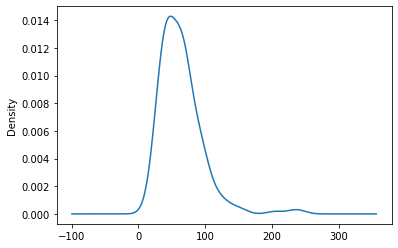

In [19]:
tmh_217_raw['original_shape_Maximum2DDiameterColumn'].plot(kind='kde')

<AxesSubplot:ylabel='Density'>

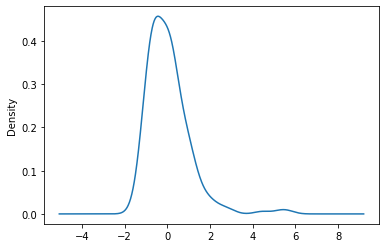

In [20]:
# disributed scaling
tmh_217_zscaled['original_shape_Maximum2DDiameterColumn'].plot(kind='kde')

In [21]:
merged_gz1_gz2=pd.concat([gz1,gz2])

In [22]:
gz2

,original_shape_Maximum2DDiameterColumn,wavelet-HLH_glcm_ClusterProminence,original_shape_Maximum3DDiameter,log-sigma-3-mm-3D_glcm_Idn,original_shape_MajorAxisLength,wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,original_shape_Maximum2DDiameterRow,wavelet-HLH_glcm_DifferenceVariance,log-sigma-3-mm-3D_ngtdm_Contrast,wavelet-HLH_glrlm_GrayLevelVariance,...,wavelet-HLH_glszm_GrayLevelNonUniformityNormalized,wavelet-LHL_glrlm_RunPercentage,wavelet-LHL_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation.1,wavelet-LHH_glrlm_GrayLevelVariance,wavelet-LLH_glcm_JointEnergy,wavelet-HHH_glcm_Contrast,wavelet-LHH_gldm_GrayLevelVariance,wavelet-HHH_glcm_SumSquares,wavelet-HHH_glcm_ClusterTendency
0,0.095285,-0.565539,0.847460,0.543318,0.446598,-0.925620,0.812885,-1.139238,-0.508481,-1.032304,...,1.053169,-0.868034,0.906878,-0.518176,-1.133731,0.195301,-1.139933,-1.111311,-1.142291,-1.144599
1,1.241731,-0.572337,1.105586,1.151285,1.140019,-1.068774,1.564465,-1.228358,-0.651410,-1.124202,...,2.090816,-1.936569,1.841496,-1.427224,-1.197448,3.154495,-1.191626,-1.171768,-1.194358,-1.197054
2,1.036530,-0.235186,1.224034,0.704343,1.038914,0.220946,1.791526,0.026685,-0.561227,-0.103205,...,-0.357308,-0.075605,-0.029238,-0.854189,0.084881,-0.375666,0.037235,0.084185,0.030153,0.022635
3,0.950111,-0.571333,1.670969,1.487881,1.681417,-1.059897,2.284182,-1.210649,-0.697780,-1.115788,...,3.107813,-0.954069,0.640520,-1.869646,-1.175070,1.904840,-1.125764,-1.148839,-1.129196,-1.132647
4,-0.969188,-0.571714,-0.988613,0.916119,-0.955054,-1.127517,-0.853976,-1.210561,-0.703537,-1.120881,...,4.436658,-1.012859,0.663260,-2.380067,-1.258115,4.424707,-1.149534,-1.215115,-1.153755,-1.158038
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,0.884601,-0.059677,0.540902,1.042696,0.441134,0.373655,0.629882,-0.170918,-0.584735,-0.324970,...,-0.051219,-1.739402,1.568400,-0.904495,-0.414298,0.068409,-0.527322,-0.427165,-0.521711,-0.515670
196,-0.003805,0.036488,0.296057,0.472604,-0.118555,1.347468,0.452986,0.367703,-0.412997,0.267449,...,-0.511197,-0.652783,0.532491,-0.198278,1.065803,-0.151271,0.154395,0.994056,0.149861,0.145025
197,0.070242,-0.165876,-0.207688,0.410698,-0.097212,0.640965,0.095975,0.267738,-0.358047,0.092098,...,-0.414435,0.020267,-0.080931,0.382984,0.454589,-0.502157,0.626457,0.442423,0.620763,0.614616
198,-1.182590,-0.279042,-1.240372,-1.526836,-1.182345,-0.699341,-1.245370,-0.165138,0.913087,-0.049985,...,-0.195912,0.948321,-0.852188,0.580043,-0.769730,-0.418318,-0.645692,-0.737228,-0.649410,-0.653244


In [23]:
gz1

,original_shape_Maximum2DDiameterColumn,wavelet-HLH_glcm_ClusterProminence,original_shape_Maximum3DDiameter,log-sigma-3-mm-3D_glcm_Idn,original_shape_MajorAxisLength,wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,original_shape_Maximum2DDiameterRow,wavelet-HLH_glcm_DifferenceVariance,log-sigma-3-mm-3D_ngtdm_Contrast,wavelet-HLH_glrlm_GrayLevelVariance,...,wavelet-HLH_glszm_GrayLevelNonUniformityNormalized,wavelet-LHL_glrlm_RunPercentage,wavelet-LHL_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation.1,wavelet-LHH_glrlm_GrayLevelVariance,wavelet-LLH_glcm_JointEnergy,wavelet-HHH_glcm_Contrast,wavelet-LHH_gldm_GrayLevelVariance,wavelet-HHH_glcm_SumSquares,wavelet-HHH_glcm_ClusterTendency
0,1.002929,-0.158593,0.535507,0.627690,0.766602,0.522904,0.614571,0.066189,-0.489722,-0.043802,...,-0.371782,0.277202,-0.350722,-0.127625,0.550076,-0.402276,-0.159752,0.519861,-0.156247,-0.152503
1,1.641442,-0.328761,1.281004,1.095175,1.012910,0.326866,1.225587,-0.361820,-0.611166,-0.478644,...,-0.080833,-0.538924,0.341873,-0.693970,-0.342535,-0.150158,-0.269198,-0.370218,-0.275640,-0.282429
2,-0.216698,0.809057,0.254426,-0.078780,0.445869,1.264531,0.662507,1.633678,-0.081371,1.344248,...,-0.669580,0.692503,-0.657963,0.768801,0.228626,-0.526297,2.454657,0.241961,2.438367,2.420668
3,1.515035,-0.316823,1.102072,0.458645,1.469101,-0.179016,1.482240,-0.146419,-0.481872,-0.237677,...,-0.227852,0.257047,-0.336965,-0.461844,-0.385211,-0.449178,-0.061031,-0.382950,-0.062334,-0.063707
4,0.486621,0.248105,0.715801,0.863169,0.575784,1.616985,0.701438,0.410477,-0.500319,0.233276,...,-0.385368,0.353066,-0.415007,-0.061863,0.367440,-0.389574,0.744221,0.342079,0.742690,0.740938
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
415,1.283747,2.758100,1.860471,1.098894,0.505962,2.533252,1.761682,0.611044,-0.571812,0.149433,...,-0.253043,-0.194363,0.011456,-0.249046,-0.210597,-0.044172,-0.261418,-0.238683,-0.259452,-0.257322
416,0.288155,-0.191458,0.875144,0.840676,0.855485,0.085703,1.395672,-0.044285,-0.543859,-0.196749,...,-0.320026,-0.675018,0.560868,-0.448879,-0.268157,-0.219777,-0.579880,-0.304330,-0.580745,-0.581565
417,-0.616651,-0.385354,-0.827103,-0.325253,-0.764525,-0.459880,-0.716487,-0.205487,-0.174620,-0.185056,...,-0.322580,-0.119261,0.064306,-0.305911,-0.008453,-0.399329,-0.271229,-0.026186,-0.276346,-0.281727
418,-0.168772,-0.229571,-0.183184,0.259505,-0.263123,0.232285,-0.172405,-0.006549,-0.232858,-0.093634,...,-0.332523,0.214750,-0.231592,0.612561,0.178467,-0.406091,-0.304453,0.156457,-0.298556,-0.292248


In [24]:
merged_gz1_gz2

,original_shape_Maximum2DDiameterColumn,wavelet-HLH_glcm_ClusterProminence,original_shape_Maximum3DDiameter,log-sigma-3-mm-3D_glcm_Idn,original_shape_MajorAxisLength,wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,original_shape_Maximum2DDiameterRow,wavelet-HLH_glcm_DifferenceVariance,log-sigma-3-mm-3D_ngtdm_Contrast,wavelet-HLH_glrlm_GrayLevelVariance,...,wavelet-HLH_glszm_GrayLevelNonUniformityNormalized,wavelet-LHL_glrlm_RunPercentage,wavelet-LHL_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation.1,wavelet-LHH_glrlm_GrayLevelVariance,wavelet-LLH_glcm_JointEnergy,wavelet-HHH_glcm_Contrast,wavelet-LHH_gldm_GrayLevelVariance,wavelet-HHH_glcm_SumSquares,wavelet-HHH_glcm_ClusterTendency
0,1.002929,-0.158593,0.535507,0.627690,0.766602,0.522904,0.614571,0.066189,-0.489722,-0.043802,...,-0.371782,0.277202,-0.350722,-0.127625,0.550076,-0.402276,-0.159752,0.519861,-0.156247,-0.152503
1,1.641442,-0.328761,1.281004,1.095175,1.012910,0.326866,1.225587,-0.361820,-0.611166,-0.478644,...,-0.080833,-0.538924,0.341873,-0.693970,-0.342535,-0.150158,-0.269198,-0.370218,-0.275640,-0.282429
2,-0.216698,0.809057,0.254426,-0.078780,0.445869,1.264531,0.662507,1.633678,-0.081371,1.344248,...,-0.669580,0.692503,-0.657963,0.768801,0.228626,-0.526297,2.454657,0.241961,2.438367,2.420668
3,1.515035,-0.316823,1.102072,0.458645,1.469101,-0.179016,1.482240,-0.146419,-0.481872,-0.237677,...,-0.227852,0.257047,-0.336965,-0.461844,-0.385211,-0.449178,-0.061031,-0.382950,-0.062334,-0.063707
4,0.486621,0.248105,0.715801,0.863169,0.575784,1.616985,0.701438,0.410477,-0.500319,0.233276,...,-0.385368,0.353066,-0.415007,-0.061863,0.367440,-0.389574,0.744221,0.342079,0.742690,0.740938
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,0.884601,-0.059677,0.540902,1.042696,0.441134,0.373655,0.629882,-0.170918,-0.584735,-0.324970,...,-0.051219,-1.739402,1.568400,-0.904495,-0.414298,0.068409,-0.527322,-0.427165,-0.521711,-0.515670
196,-0.003805,0.036488,0.296057,0.472604,-0.118555,1.347468,0.452986,0.367703,-0.412997,0.267449,...,-0.511197,-0.652783,0.532491,-0.198278,1.065803,-0.151271,0.154395,0.994056,0.149861,0.145025
197,0.070242,-0.165876,-0.207688,0.410698,-0.097212,0.640965,0.095975,0.267738,-0.358047,0.092098,...,-0.414435,0.020267,-0.080931,0.382984,0.454589,-0.502157,0.626457,0.442423,0.620763,0.614616
198,-1.182590,-0.279042,-1.240372,-1.526836,-1.182345,-0.699341,-1.245370,-0.165138,0.913087,-0.049985,...,-0.195912,0.948321,-0.852188,0.580043,-0.769730,-0.418318,-0.645692,-0.737228,-0.649410,-0.653244


In [229]:
merged_gz1_gz2

,original_shape_Maximum2DDiameterColumn,wavelet-HLH_glcm_ClusterProminence,original_shape_Maximum3DDiameter,log-sigma-3-mm-3D_glcm_Idn,original_shape_MajorAxisLength,wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,original_shape_Maximum2DDiameterRow,wavelet-HLH_glcm_DifferenceVariance,log-sigma-3-mm-3D_ngtdm_Contrast,wavelet-HLH_glrlm_GrayLevelVariance,...,wavelet-HLH_glszm_GrayLevelNonUniformityNormalized,wavelet-LHL_glrlm_RunPercentage,wavelet-LHL_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation.1,wavelet-LHH_glrlm_GrayLevelVariance,wavelet-LLH_glcm_JointEnergy,wavelet-HHH_glcm_Contrast,wavelet-LHH_gldm_GrayLevelVariance,wavelet-HHH_glcm_SumSquares,wavelet-HHH_glcm_ClusterTendency
0,1.002929,-0.158593,0.535507,0.627690,0.766602,0.522904,0.614571,0.066189,-0.489722,-0.043802,...,-0.371782,0.277202,-0.350722,-0.127625,0.550076,-0.402276,-0.159752,0.519861,-0.156247,-0.152503
1,1.641442,-0.328761,1.281004,1.095175,1.012910,0.326866,1.225587,-0.361820,-0.611166,-0.478644,...,-0.080833,-0.538924,0.341873,-0.693970,-0.342535,-0.150158,-0.269198,-0.370218,-0.275640,-0.282429
2,-0.216698,0.809057,0.254426,-0.078780,0.445869,1.264531,0.662507,1.633678,-0.081371,1.344248,...,-0.669580,0.692503,-0.657963,0.768801,0.228626,-0.526297,2.454657,0.241961,2.438367,2.420668
3,1.515035,-0.316823,1.102072,0.458645,1.469101,-0.179016,1.482240,-0.146419,-0.481872,-0.237677,...,-0.227852,0.257047,-0.336965,-0.461844,-0.385211,-0.449178,-0.061031,-0.382950,-0.062334,-0.063707
4,0.486621,0.248105,0.715801,0.863169,0.575784,1.616985,0.701438,0.410477,-0.500319,0.233276,...,-0.385368,0.353066,-0.415007,-0.061863,0.367440,-0.389574,0.744221,0.342079,0.742690,0.740938
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,0.884601,-0.059677,0.540902,1.042696,0.441134,0.373655,0.629882,-0.170918,-0.584735,-0.324970,...,-0.051219,-1.739402,1.568400,-0.904495,-0.414298,0.068409,-0.527322,-0.427165,-0.521711,-0.515670
196,-0.003805,0.036488,0.296057,0.472604,-0.118555,1.347468,0.452986,0.367703,-0.412997,0.267449,...,-0.511197,-0.652783,0.532491,-0.198278,1.065803,-0.151271,0.154395,0.994056,0.149861,0.145025
197,0.070242,-0.165876,-0.207688,0.410698,-0.097212,0.640965,0.095975,0.267738,-0.358047,0.092098,...,-0.414435,0.020267,-0.080931,0.382984,0.454589,-0.502157,0.626457,0.442423,0.620763,0.614616
198,-1.182590,-0.279042,-1.240372,-1.526836,-1.182345,-0.699341,-1.245370,-0.165138,0.913087,-0.049985,...,-0.195912,0.948321,-0.852188,0.580043,-0.769730,-0.418318,-0.645692,-0.737228,-0.649410,-0.653244


In [25]:
lung1_raw=pd.read_csv('D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/data/maastro/lung1_217_raw.csv')
tmh_raw=pd.read_csv('D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/data/tmh/tmh_217_raw.csv')

In [26]:
lung1_raw.columns==tmh_raw.columns

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,

In [27]:

merged_gz1_gz2

,original_shape_Maximum2DDiameterColumn,wavelet-HLH_glcm_ClusterProminence,original_shape_Maximum3DDiameter,log-sigma-3-mm-3D_glcm_Idn,original_shape_MajorAxisLength,wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,original_shape_Maximum2DDiameterRow,wavelet-HLH_glcm_DifferenceVariance,log-sigma-3-mm-3D_ngtdm_Contrast,wavelet-HLH_glrlm_GrayLevelVariance,...,wavelet-HLH_glszm_GrayLevelNonUniformityNormalized,wavelet-LHL_glrlm_RunPercentage,wavelet-LHL_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation.1,wavelet-LHH_glrlm_GrayLevelVariance,wavelet-LLH_glcm_JointEnergy,wavelet-HHH_glcm_Contrast,wavelet-LHH_gldm_GrayLevelVariance,wavelet-HHH_glcm_SumSquares,wavelet-HHH_glcm_ClusterTendency
0,1.002929,-0.158593,0.535507,0.627690,0.766602,0.522904,0.614571,0.066189,-0.489722,-0.043802,...,-0.371782,0.277202,-0.350722,-0.127625,0.550076,-0.402276,-0.159752,0.519861,-0.156247,-0.152503
1,1.641442,-0.328761,1.281004,1.095175,1.012910,0.326866,1.225587,-0.361820,-0.611166,-0.478644,...,-0.080833,-0.538924,0.341873,-0.693970,-0.342535,-0.150158,-0.269198,-0.370218,-0.275640,-0.282429
2,-0.216698,0.809057,0.254426,-0.078780,0.445869,1.264531,0.662507,1.633678,-0.081371,1.344248,...,-0.669580,0.692503,-0.657963,0.768801,0.228626,-0.526297,2.454657,0.241961,2.438367,2.420668
3,1.515035,-0.316823,1.102072,0.458645,1.469101,-0.179016,1.482240,-0.146419,-0.481872,-0.237677,...,-0.227852,0.257047,-0.336965,-0.461844,-0.385211,-0.449178,-0.061031,-0.382950,-0.062334,-0.063707
4,0.486621,0.248105,0.715801,0.863169,0.575784,1.616985,0.701438,0.410477,-0.500319,0.233276,...,-0.385368,0.353066,-0.415007,-0.061863,0.367440,-0.389574,0.744221,0.342079,0.742690,0.740938
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,0.884601,-0.059677,0.540902,1.042696,0.441134,0.373655,0.629882,-0.170918,-0.584735,-0.324970,...,-0.051219,-1.739402,1.568400,-0.904495,-0.414298,0.068409,-0.527322,-0.427165,-0.521711,-0.515670
196,-0.003805,0.036488,0.296057,0.472604,-0.118555,1.347468,0.452986,0.367703,-0.412997,0.267449,...,-0.511197,-0.652783,0.532491,-0.198278,1.065803,-0.151271,0.154395,0.994056,0.149861,0.145025
197,0.070242,-0.165876,-0.207688,0.410698,-0.097212,0.640965,0.095975,0.267738,-0.358047,0.092098,...,-0.414435,0.020267,-0.080931,0.382984,0.454589,-0.502157,0.626457,0.442423,0.620763,0.614616
198,-1.182590,-0.279042,-1.240372,-1.526836,-1.182345,-0.699341,-1.245370,-0.165138,0.913087,-0.049985,...,-0.195912,0.948321,-0.852188,0.580043,-0.769730,-0.418318,-0.645692,-0.737228,-0.649410,-0.653244


In [34]:
merged_cent_scaled

NameError: name 'merged_cent_scaled' is not defined

## centralized(merged) scaling vs distributed scaling

### centralized scaling

In [35]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
print(scaler.fit(merg_raw)) # merged_gz1_gz2

#print(scaler.mean_)
merged_cent_scaled=scaler.transform(merg_raw)
merged_cent_scaled=pd.DataFrame(merged_cent_scaled,columns=merg_raw.columns)
#print(scaler.transform(tmh_217_raw))

# scaler = StandardScaler()
# print(scaler.fit(np.array(tmh_217_raw['original_shape_Maximum2DDiameterColumn']).reshape(-1, 1)))
# print(scaler.mean_)
# print(scaler.transform(np.array(tmh_217_raw['original_shape_Maximum2DDiameterColumn']).reshape(-1, 1)))

StandardScaler()


In [36]:
# centralized scaling
merged_cent_scaled

,original_shape_Maximum2DDiameterColumn,wavelet-HLH_glcm_ClusterProminence,original_shape_Maximum3DDiameter,log-sigma-3-mm-3D_glcm_Idn,original_shape_MajorAxisLength,wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,original_shape_Maximum2DDiameterRow,wavelet-HLH_glcm_DifferenceVariance,log-sigma-3-mm-3D_ngtdm_Contrast,wavelet-HLH_glrlm_GrayLevelVariance,...,wavelet-HLH_glszm_GrayLevelNonUniformityNormalized,wavelet-LHL_glrlm_RunPercentage,wavelet-LHL_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation.1,wavelet-LHH_glrlm_GrayLevelVariance,wavelet-LLH_glcm_JointEnergy,wavelet-HHH_glcm_Contrast,wavelet-LHH_gldm_GrayLevelVariance,wavelet-HHH_glcm_SumSquares,wavelet-HHH_glcm_ClusterTendency
0,1.003739,-0.158721,0.535940,0.628197,0.767221,0.523326,0.615067,0.066242,-0.490118,-0.043837,...,-0.372082,0.277426,-0.351005,-0.127728,0.550521,-0.402601,-0.159881,0.520281,-0.156373,-0.152626
1,1.642767,-0.329026,1.282039,1.096060,1.013728,0.327130,1.226576,-0.362113,-0.611660,-0.479030,...,-0.080898,-0.539359,0.342149,-0.694530,-0.342811,-0.150280,-0.269416,-0.370517,-0.275863,-0.282657
2,-0.216873,0.809710,0.254632,-0.078844,0.446229,1.265552,0.663042,1.634997,-0.081437,1.345334,...,-0.670121,0.693062,-0.658494,0.769422,0.228810,-0.526722,2.456639,0.242156,2.440335,2.422623
3,1.516258,-0.317079,1.102962,0.459016,1.470287,-0.179160,1.483437,-0.146537,-0.482261,-0.237869,...,-0.228036,0.257255,-0.337237,-0.462217,-0.385522,-0.449540,-0.061080,-0.383259,-0.062385,-0.063758
4,0.487014,0.248305,0.716379,0.863866,0.576249,1.618291,0.702004,0.410808,-0.500723,0.233464,...,-0.385679,0.353351,-0.415342,-0.061913,0.367737,-0.389888,0.744822,0.342355,0.743289,0.741537
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
615,0.885315,-0.059725,0.541339,1.043538,0.441490,0.373957,0.630391,-0.171056,-0.585207,-0.325233,...,-0.051260,-1.740806,1.569666,-0.905226,-0.414633,0.068464,-0.527748,-0.427510,-0.522133,-0.516086
616,-0.003808,0.036517,0.296296,0.472986,-0.118651,1.348556,0.453352,0.368000,-0.413330,0.267665,...,-0.511610,-0.653310,0.532921,-0.198438,1.066664,-0.151394,0.154520,0.994858,0.149982,0.145142
617,0.070299,-0.166010,-0.207855,0.411030,-0.097291,0.641483,0.096052,0.267954,-0.358336,0.092173,...,-0.414769,0.020284,-0.080996,0.383293,0.454956,-0.502563,0.626963,0.442780,0.621264,0.615112
618,-1.183544,-0.279267,-1.241374,-1.528069,-1.183300,-0.699906,-1.246375,-0.165271,0.913824,-0.050025,...,-0.196070,0.949087,-0.852876,0.580512,-0.770352,-0.418656,-0.646213,-0.737823,-0.649934,-0.653772


In [87]:
# old

,original_shape_Maximum2DDiameterColumn,wavelet-HLH_glcm_ClusterProminence,original_shape_Maximum3DDiameter,log-sigma-3-mm-3D_glcm_Idn,original_shape_MajorAxisLength,wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,original_shape_Maximum2DDiameterRow,wavelet-HLH_glcm_DifferenceVariance,log-sigma-3-mm-3D_ngtdm_Contrast,wavelet-HLH_glrlm_GrayLevelVariance,...,wavelet-HLH_glszm_GrayLevelNonUniformityNormalized,wavelet-LHL_glrlm_RunPercentage,wavelet-LHL_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation.1,wavelet-LHH_glrlm_GrayLevelVariance,wavelet-LLH_glcm_JointEnergy,wavelet-HHH_glcm_Contrast,wavelet-LHH_gldm_GrayLevelVariance,wavelet-HHH_glcm_SumSquares,wavelet-HHH_glcm_ClusterTendency
0,1.003739,-0.158721,0.535940,0.628197,0.767221,0.523326,0.615067,0.066242,-0.490118,-0.043837,...,-0.372082,0.277426,-0.351005,-0.127728,0.550521,-0.402601,-0.159881,0.520281,-0.156373,-0.152626
1,1.642767,-0.329026,1.282039,1.096060,1.013728,0.327130,1.226576,-0.362113,-0.611660,-0.479030,...,-0.080898,-0.539359,0.342149,-0.694530,-0.342811,-0.150280,-0.269416,-0.370517,-0.275863,-0.282657
2,-0.216873,0.809710,0.254632,-0.078844,0.446229,1.265552,0.663042,1.634997,-0.081437,1.345334,...,-0.670121,0.693062,-0.658494,0.769422,0.228810,-0.526722,2.456639,0.242156,2.440335,2.422623
3,1.516258,-0.317079,1.102962,0.459016,1.470287,-0.179160,1.483437,-0.146537,-0.482261,-0.237869,...,-0.228036,0.257255,-0.337237,-0.462217,-0.385522,-0.449540,-0.061080,-0.383259,-0.062385,-0.063758
4,0.487014,0.248305,0.716379,0.863866,0.576249,1.618291,0.702004,0.410808,-0.500723,0.233464,...,-0.385679,0.353351,-0.415342,-0.061913,0.367737,-0.389888,0.744822,0.342355,0.743289,0.741537
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
615,0.885315,-0.059725,0.541339,1.043538,0.441490,0.373957,0.630391,-0.171056,-0.585207,-0.325233,...,-0.051260,-1.740806,1.569666,-0.905226,-0.414633,0.068464,-0.527748,-0.427510,-0.522133,-0.516086
616,-0.003808,0.036517,0.296296,0.472986,-0.118651,1.348556,0.453352,0.368000,-0.413330,0.267665,...,-0.511610,-0.653310,0.532921,-0.198438,1.066664,-0.151394,0.154520,0.994858,0.149982,0.145142
617,0.070299,-0.166010,-0.207855,0.411030,-0.097291,0.641483,0.096052,0.267954,-0.358336,0.092173,...,-0.414769,0.020284,-0.080996,0.383293,0.454956,-0.502563,0.626963,0.442780,0.621264,0.615112
618,-1.183544,-0.279267,-1.241374,-1.528069,-1.183300,-0.699906,-1.246375,-0.165271,0.913824,-0.050025,...,-0.196070,0.949087,-0.852876,0.580512,-0.770352,-0.418656,-0.646213,-0.737823,-0.649934,-0.653772


### distributed scaling

In [38]:
lung1_217_zscaled.head()

,original_shape_Maximum2DDiameterColumn,wavelet-HLH_glcm_ClusterProminence,original_shape_Maximum3DDiameter,log-sigma-3-mm-3D_glcm_Idn,original_shape_MajorAxisLength,wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,original_shape_Maximum2DDiameterRow,wavelet-HLH_glcm_DifferenceVariance,log-sigma-3-mm-3D_ngtdm_Contrast,wavelet-HLH_glrlm_GrayLevelVariance,...,wavelet-HLH_glszm_GrayLevelNonUniformityNormalized,wavelet-LHL_glrlm_RunPercentage,wavelet-LHL_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation.1,wavelet-LHH_glrlm_GrayLevelVariance,wavelet-LLH_glcm_JointEnergy,wavelet-HHH_glcm_Contrast,wavelet-LHH_gldm_GrayLevelVariance,wavelet-HHH_glcm_SumSquares,wavelet-HHH_glcm_ClusterTendency
0,1.002929,-0.158593,0.535507,0.627690,0.766602,0.522904,0.614571,0.066189,-0.489722,-0.043802,...,-0.371782,0.277202,-0.350722,-0.127625,0.550076,-0.402276,-0.159752,0.519861,-0.156247,-0.152503
1,1.641442,-0.328761,1.281004,1.095175,1.012910,0.326866,1.225587,-0.361820,-0.611166,-0.478644,...,-0.080833,-0.538924,0.341873,-0.693970,-0.342535,-0.150158,-0.269198,-0.370218,-0.275640,-0.282429
2,-0.216698,0.809057,0.254426,-0.078780,0.445869,1.264531,0.662507,1.633678,-0.081371,1.344248,...,-0.669580,0.692503,-0.657963,0.768801,0.228626,-0.526297,2.454657,0.241961,2.438367,2.420668
3,1.515035,-0.316823,1.102072,0.458645,1.469101,-0.179016,1.482240,-0.146419,-0.481872,-0.237677,...,-0.227852,0.257047,-0.336965,-0.461844,-0.385211,-0.449178,-0.061031,-0.382950,-0.062334,-0.063707
4,0.486621,0.248105,0.715801,0.863169,0.575784,1.616985,0.701438,0.410477,-0.500319,0.233276,...,-0.385368,0.353066,-0.415007,-0.061863,0.367440,-0.389574,0.744221,0.342079,0.742690,0.740938


In [39]:
tmh_217_zscaled.head()

,original_shape_Maximum2DDiameterColumn,wavelet-HLH_glcm_ClusterProminence,original_shape_Maximum3DDiameter,log-sigma-3-mm-3D_glcm_Idn,original_shape_MajorAxisLength,wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,original_shape_Maximum2DDiameterRow,wavelet-HLH_glcm_DifferenceVariance,log-sigma-3-mm-3D_ngtdm_Contrast,wavelet-HLH_glrlm_GrayLevelVariance,...,wavelet-HLH_glszm_GrayLevelNonUniformityNormalized,wavelet-LHL_glrlm_RunPercentage,wavelet-LHL_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation.1,wavelet-LHH_glrlm_GrayLevelVariance,wavelet-LLH_glcm_JointEnergy,wavelet-HHH_glcm_Contrast,wavelet-LHH_gldm_GrayLevelVariance,wavelet-HHH_glcm_SumSquares,wavelet-HHH_glcm_ClusterTendency
0,0.095285,-0.565539,0.847460,0.543318,0.446598,-0.925620,0.812885,-1.139238,-0.508481,-1.032304,...,1.053169,-0.868034,0.906878,-0.518176,-1.133731,0.195301,-1.139933,-1.111311,-1.142291,-1.144599
1,1.241731,-0.572337,1.105586,1.151285,1.140019,-1.068774,1.564465,-1.228358,-0.651410,-1.124202,...,2.090816,-1.936569,1.841496,-1.427224,-1.197448,3.154495,-1.191626,-1.171768,-1.194358,-1.197054
2,1.036530,-0.235186,1.224034,0.704343,1.038914,0.220946,1.791526,0.026685,-0.561227,-0.103205,...,-0.357308,-0.075605,-0.029238,-0.854189,0.084881,-0.375666,0.037235,0.084185,0.030153,0.022635
3,0.950111,-0.571333,1.670969,1.487881,1.681417,-1.059897,2.284182,-1.210649,-0.697780,-1.115788,...,3.107813,-0.954069,0.640520,-1.869646,-1.175070,1.904840,-1.125764,-1.148839,-1.129196,-1.132647
4,-0.969188,-0.571714,-0.988613,0.916119,-0.955054,-1.127517,-0.853976,-1.210561,-0.703537,-1.120881,...,4.436658,-1.012859,0.663260,-2.380067,-1.258115,4.424707,-1.149534,-1.215115,-1.153755,-1.158038


# gb important cell

In [90]:
### comparing centralized scaling vs distributed scaling


In [91]:
# centrlized lung
merged_cent_scaled['original_shape_Maximum2DDiameterColumn'][:420]

0      1.003739
1      1.642767
2     -0.216873
3      1.516258
4      0.487014
         ...   
415    1.284784
416    0.288387
417   -0.617149
418   -0.168908
419   -0.320636
Name: original_shape_Maximum2DDiameterColumn, Length: 420, dtype: float64

In [92]:
# distributed lung
lung1_217_zscaled['original_shape_Maximum2DDiameterColumn']

0      1.002929
1      1.641442
2     -0.216698
3      1.515035
4      0.486621
         ...   
415    1.283747
416    0.288155
417   -0.616651
418   -0.168772
419   -0.320377
Name: original_shape_Maximum2DDiameterColumn, Length: 420, dtype: float64

In [40]:
merged_cent_scaled.head(5)

,original_shape_Maximum2DDiameterColumn,wavelet-HLH_glcm_ClusterProminence,original_shape_Maximum3DDiameter,log-sigma-3-mm-3D_glcm_Idn,original_shape_MajorAxisLength,wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,original_shape_Maximum2DDiameterRow,wavelet-HLH_glcm_DifferenceVariance,log-sigma-3-mm-3D_ngtdm_Contrast,wavelet-HLH_glrlm_GrayLevelVariance,...,wavelet-HLH_glszm_GrayLevelNonUniformityNormalized,wavelet-LHL_glrlm_RunPercentage,wavelet-LHL_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation.1,wavelet-LHH_glrlm_GrayLevelVariance,wavelet-LLH_glcm_JointEnergy,wavelet-HHH_glcm_Contrast,wavelet-LHH_gldm_GrayLevelVariance,wavelet-HHH_glcm_SumSquares,wavelet-HHH_glcm_ClusterTendency
0,1.003739,-0.158721,0.535940,0.628197,0.767221,0.523326,0.615067,0.066242,-0.490118,-0.043837,...,-0.372082,0.277426,-0.351005,-0.127728,0.550521,-0.402601,-0.159881,0.520281,-0.156373,-0.152626
1,1.642767,-0.329026,1.282039,1.096060,1.013728,0.327130,1.226576,-0.362113,-0.611660,-0.479030,...,-0.080898,-0.539359,0.342149,-0.694530,-0.342811,-0.150280,-0.269416,-0.370517,-0.275863,-0.282657
2,-0.216873,0.809710,0.254632,-0.078844,0.446229,1.265552,0.663042,1.634997,-0.081437,1.345334,...,-0.670121,0.693062,-0.658494,0.769422,0.228810,-0.526722,2.456639,0.242156,2.440335,2.422623
3,1.516258,-0.317079,1.102962,0.459016,1.470287,-0.179160,1.483437,-0.146537,-0.482261,-0.237869,...,-0.228036,0.257255,-0.337237,-0.462217,-0.385522,-0.449540,-0.061080,-0.383259,-0.062385,-0.063758
4,0.487014,0.248305,0.716379,0.863866,0.576249,1.618291,0.702004,0.410808,-0.500723,0.233464,...,-0.385679,0.353351,-0.415342,-0.061913,0.367737,-0.389888,0.744822,0.342355,0.743289,0.741537


In [41]:
lung1_217_zscaled.head(5)

,original_shape_Maximum2DDiameterColumn,wavelet-HLH_glcm_ClusterProminence,original_shape_Maximum3DDiameter,log-sigma-3-mm-3D_glcm_Idn,original_shape_MajorAxisLength,wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,original_shape_Maximum2DDiameterRow,wavelet-HLH_glcm_DifferenceVariance,log-sigma-3-mm-3D_ngtdm_Contrast,wavelet-HLH_glrlm_GrayLevelVariance,...,wavelet-HLH_glszm_GrayLevelNonUniformityNormalized,wavelet-LHL_glrlm_RunPercentage,wavelet-LHL_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation.1,wavelet-LHH_glrlm_GrayLevelVariance,wavelet-LLH_glcm_JointEnergy,wavelet-HHH_glcm_Contrast,wavelet-LHH_gldm_GrayLevelVariance,wavelet-HHH_glcm_SumSquares,wavelet-HHH_glcm_ClusterTendency
0,1.002929,-0.158593,0.535507,0.627690,0.766602,0.522904,0.614571,0.066189,-0.489722,-0.043802,...,-0.371782,0.277202,-0.350722,-0.127625,0.550076,-0.402276,-0.159752,0.519861,-0.156247,-0.152503
1,1.641442,-0.328761,1.281004,1.095175,1.012910,0.326866,1.225587,-0.361820,-0.611166,-0.478644,...,-0.080833,-0.538924,0.341873,-0.693970,-0.342535,-0.150158,-0.269198,-0.370218,-0.275640,-0.282429
2,-0.216698,0.809057,0.254426,-0.078780,0.445869,1.264531,0.662507,1.633678,-0.081371,1.344248,...,-0.669580,0.692503,-0.657963,0.768801,0.228626,-0.526297,2.454657,0.241961,2.438367,2.420668
3,1.515035,-0.316823,1.102072,0.458645,1.469101,-0.179016,1.482240,-0.146419,-0.481872,-0.237677,...,-0.227852,0.257047,-0.336965,-0.461844,-0.385211,-0.449178,-0.061031,-0.382950,-0.062334,-0.063707
4,0.486621,0.248105,0.715801,0.863169,0.575784,1.616985,0.701438,0.410477,-0.500319,0.233276,...,-0.385368,0.353066,-0.415007,-0.061863,0.367440,-0.389574,0.744221,0.342079,0.742690,0.740938


In [42]:
# centralized TMH
merged_cent_scaled['log-sigma-3-mm-3D_glcm_Idn'][420:]

420    0.543757
421    1.152215
422    0.704911
423    1.489082
424    0.916858
         ...   
615    1.043538
616    0.472986
617    0.411030
618   -1.528069
619    0.174097
Name: log-sigma-3-mm-3D_glcm_Idn, Length: 200, dtype: float64

In [43]:
# distributed TMh
tmh_217_zscaled['log-sigma-3-mm-3D_glcm_Idn']

0      0.543318
1      1.151285
2      0.704343
3      1.487881
4      0.916119
         ...   
195    1.042696
196    0.472604
197    0.410698
198   -1.526836
199    0.173956
Name: log-sigma-3-mm-3D_glcm_Idn, Length: 200, dtype: float64

In [33]:
np.min(tmh_217_zscaled['wavelet-HLH_glcm_ClusterProminence'])

-0.5733704682632209

In [34]:
np.mean(tmh_217_zscaled['wavelet-HLH_glcm_ClusterProminence'])

-0.3206593397859719

In [35]:
np.max(tmh_217_zscaled['wavelet-HLH_glcm_ClusterProminence'])

3.944267629708839

<AxesSubplot:title={'center':'Raw data'}, ylabel='Density'>

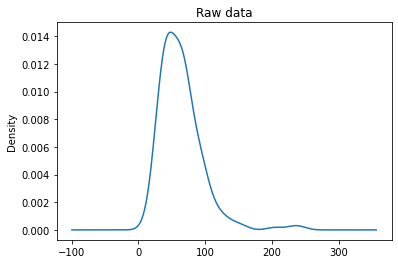

In [113]:
tmh_217_raw['original_shape_Maximum2DDiameterColumn'].plot(kind='kde',title='Raw data')

<AxesSubplot:title={'center':'distributed scaling'}, ylabel='Density'>

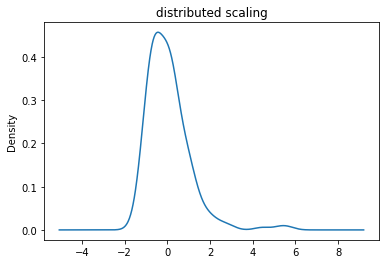

In [44]:
tmh_217_zscaled['original_shape_Maximum2DDiameterColumn'].plot(kind='kde',title='distributed scaling')
#merged_cent_scaled['original_shape_Maximum2DDiameterColumn'][420:].plot(kind='kde')

<AxesSubplot:title={'center':'centralized scaling'}, ylabel='Density'>

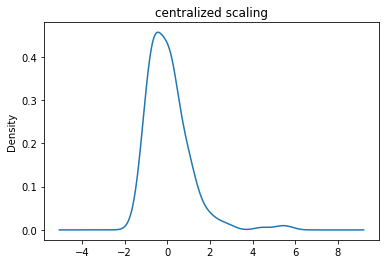

In [121]:
merged_cent_scaled['original_shape_Maximum2DDiameterColumn'][420:].plot(kind='kde',title='centralized scaling')

<AxesSubplot:title={'center':'Raw data'}>

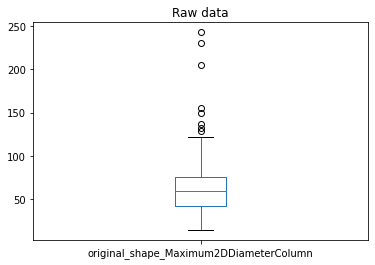

In [114]:
tmh_217_raw['original_shape_Maximum2DDiameterColumn'].plot(kind='box',title='Raw data')

In [109]:
# fig, axes = plt.subplots()

# axes.violinplot(dataset = [tmh_217_raw['wavelet-HLH_glcm_ClusterProminence'].values,
#                            tmh_217_zscaled['wavelet-HLH_glcm_ClusterProminence'].values,
#                            merged_cent_scaled['wavelet-HLH_glcm_ClusterProminence'][420:].values])

# axes.set_title('Day Ahead Market')
# axes.yaxis.grid(True)
# axes.set_xlabel('Scenario')
# axes.set_ylabel('LMP ($/MWh)')

# plt.show()

<AxesSubplot:title={'center':'distributed scaling'}>

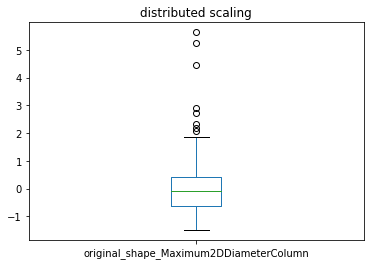

In [122]:
tmh_217_zscaled['original_shape_Maximum2DDiameterColumn'].plot(kind='box',title='distributed scaling')


In [11]:
pwd

'D:\\gb_NLP_to_paper\\gb_nlp_scripts\\gb_nlp_scripts'

<AxesSubplot:title={'center':'centralized scaling'}>

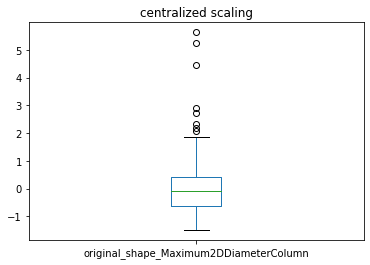

In [120]:
merged_cent_scaled['original_shape_Maximum2DDiameterColumn'][420:].plot(kind='box',title='centralized scaling')

## centralized(merged) vs Distributed Univariate features

In [45]:
#*00 
# univariate cox feauters from R distributed Script D:\test_that_univariate.R 
# 


ucox=pd.read_csv('D:/DIstributed_Univariate_cox_features.csv')

In [46]:
ucox

,Unnamed: 0,"gb_1[order(gb_1, decreasing = FALSE), ]"
0,wavelet.LLL_gldm_DependenceNonUniformity,1.000000e-15
1,original_glrlm_RunLengthNonUniformity,2.000000e-15
2,original_gldm_DependenceNonUniformity,3.000000e-15
3,log.sigma.2.mm.3D_glrlm_RunLengthNonUniformity,3.000000e-14
4,wavelet.LHL_glszm_SizeZoneNonUniformity,1.000000e-13
...,...,...
95,wavelet.HLL_glrlm_RunVariance,5.000000e-01
96,log.sigma.1.mm.3D_gldm_LargeDependenceEmphasis,5.000000e-01
97,wavelet.HLL_gldm_LargeDependenceEmphasis,7.000000e-01
98,wavelet.HHL_glrlm_RunPercentage,9.000000e-01


In [1]:
import pandas as pd

In [2]:
ucox_217_dist=pd.read_csv('D:/gb_217_DIstributed_Univariate_cox_features.csv')

In [10]:
ucox_217_dist.head(n=25)

,Unnamed: 0,"gb_1[order(gb_1, decreasing = FALSE), ]"
0,original_shape_SurfaceArea,2.000000e-14
1,original_shape_Maximum2DDiameterColumn,8.000000e-12
2,original_shape_Maximum2DDiameterRow,8.000000e-11
3,original_shape_Maximum2DDiameterSlice,6.000000e-10
4,original_shape_MajorAxisLength,1.000000e-09
5,original_shape_Maximum3DDiameter,3.000000e-08
6,wavelet.LLH_gldm_LargeDependenceHighGrayLevelE...,6.000000e-08
7,original_shape_MinorAxisLength,1.000000e-07
8,log.sigma.3.mm.3D_gldm_LargeDependenceEmphasis,2.000000e-07
9,log.sigma.3.mm.3D_glcm_Idm,1.000000e-06


In [8]:
ucox_217_dist['Unnamed: 0'][:21]

0                            original_shape_SurfaceArea
1                original_shape_Maximum2DDiameterColumn
2                   original_shape_Maximum2DDiameterRow
3                 original_shape_Maximum2DDiameterSlice
4                        original_shape_MajorAxisLength
5                      original_shape_Maximum3DDiameter
6     wavelet.LLH_gldm_LargeDependenceHighGrayLevelE...
7                        original_shape_MinorAxisLength
8        log.sigma.3.mm.3D_gldm_LargeDependenceEmphasis
9                            log.sigma.3.mm.3D_glcm_Idm
10                         log.sigma.3.mm.3D_glcm_Idm.1
11            log.sigma.3.mm.3D_glcm_MaximumProbability
12       wavelet.LLH_glrlm_LongRunHighGrayLevelEmphasis
13                           log.sigma.3.mm.3D_glcm_Idn
14             log.sigma.3.mm.3D_glrlm_ShortRunEmphasis
15    log.sigma.3.mm.3D_glrlm_RunLengthNonUniformity...
16                log.sigma.3.mm.3D_glrlm_RunPercentage
17                     wavelet.LLH_glcm_Autocorr

In [47]:
ucox_217_dist=pd.read_csv('D:/gb_217_DIstributed_Univariate_cox_features.csv')

ucox_217_dist.head()

,Unnamed: 0,"gb_1[order(gb_1, decreasing = FALSE), ]"
0,original_shape_SurfaceArea,2.000000e-14
1,original_shape_Maximum2DDiameterColumn,8.000000e-12
2,original_shape_Maximum2DDiameterRow,8.000000e-11
3,original_shape_Maximum2DDiameterSlice,6.000000e-10
4,original_shape_MajorAxisLength,1.000000e-09


In [48]:
merged_cent_scaled

,original_shape_Maximum2DDiameterColumn,wavelet-HLH_glcm_ClusterProminence,original_shape_Maximum3DDiameter,log-sigma-3-mm-3D_glcm_Idn,original_shape_MajorAxisLength,wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,original_shape_Maximum2DDiameterRow,wavelet-HLH_glcm_DifferenceVariance,log-sigma-3-mm-3D_ngtdm_Contrast,wavelet-HLH_glrlm_GrayLevelVariance,...,wavelet-HLH_glszm_GrayLevelNonUniformityNormalized,wavelet-LHL_glrlm_RunPercentage,wavelet-LHL_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation.1,wavelet-LHH_glrlm_GrayLevelVariance,wavelet-LLH_glcm_JointEnergy,wavelet-HHH_glcm_Contrast,wavelet-LHH_gldm_GrayLevelVariance,wavelet-HHH_glcm_SumSquares,wavelet-HHH_glcm_ClusterTendency
0,1.003739,-0.158721,0.535940,0.628197,0.767221,0.523326,0.615067,0.066242,-0.490118,-0.043837,...,-0.372082,0.277426,-0.351005,-0.127728,0.550521,-0.402601,-0.159881,0.520281,-0.156373,-0.152626
1,1.642767,-0.329026,1.282039,1.096060,1.013728,0.327130,1.226576,-0.362113,-0.611660,-0.479030,...,-0.080898,-0.539359,0.342149,-0.694530,-0.342811,-0.150280,-0.269416,-0.370517,-0.275863,-0.282657
2,-0.216873,0.809710,0.254632,-0.078844,0.446229,1.265552,0.663042,1.634997,-0.081437,1.345334,...,-0.670121,0.693062,-0.658494,0.769422,0.228810,-0.526722,2.456639,0.242156,2.440335,2.422623
3,1.516258,-0.317079,1.102962,0.459016,1.470287,-0.179160,1.483437,-0.146537,-0.482261,-0.237869,...,-0.228036,0.257255,-0.337237,-0.462217,-0.385522,-0.449540,-0.061080,-0.383259,-0.062385,-0.063758
4,0.487014,0.248305,0.716379,0.863866,0.576249,1.618291,0.702004,0.410808,-0.500723,0.233464,...,-0.385679,0.353351,-0.415342,-0.061913,0.367737,-0.389888,0.744822,0.342355,0.743289,0.741537
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
615,0.885315,-0.059725,0.541339,1.043538,0.441490,0.373957,0.630391,-0.171056,-0.585207,-0.325233,...,-0.051260,-1.740806,1.569666,-0.905226,-0.414633,0.068464,-0.527748,-0.427510,-0.522133,-0.516086
616,-0.003808,0.036517,0.296296,0.472986,-0.118651,1.348556,0.453352,0.368000,-0.413330,0.267665,...,-0.511610,-0.653310,0.532921,-0.198438,1.066664,-0.151394,0.154520,0.994858,0.149982,0.145142
617,0.070299,-0.166010,-0.207855,0.411030,-0.097291,0.641483,0.096052,0.267954,-0.358336,0.092173,...,-0.414769,0.020284,-0.080996,0.383293,0.454956,-0.502563,0.626963,0.442780,0.621264,0.615112
618,-1.183544,-0.279267,-1.241374,-1.528069,-1.183300,-0.699906,-1.246375,-0.165271,0.913824,-0.050025,...,-0.196070,0.949087,-0.852876,0.580512,-0.770352,-0.418656,-0.646213,-0.737823,-0.649934,-0.653772


In [49]:
merged_gz1_gz2

,original_shape_Maximum2DDiameterColumn,wavelet-HLH_glcm_ClusterProminence,original_shape_Maximum3DDiameter,log-sigma-3-mm-3D_glcm_Idn,original_shape_MajorAxisLength,wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,original_shape_Maximum2DDiameterRow,wavelet-HLH_glcm_DifferenceVariance,log-sigma-3-mm-3D_ngtdm_Contrast,wavelet-HLH_glrlm_GrayLevelVariance,...,wavelet-HLH_glszm_GrayLevelNonUniformityNormalized,wavelet-LHL_glrlm_RunPercentage,wavelet-LHL_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation.1,wavelet-LHH_glrlm_GrayLevelVariance,wavelet-LLH_glcm_JointEnergy,wavelet-HHH_glcm_Contrast,wavelet-LHH_gldm_GrayLevelVariance,wavelet-HHH_glcm_SumSquares,wavelet-HHH_glcm_ClusterTendency
0,1.002929,-0.158593,0.535507,0.627690,0.766602,0.522904,0.614571,0.066189,-0.489722,-0.043802,...,-0.371782,0.277202,-0.350722,-0.127625,0.550076,-0.402276,-0.159752,0.519861,-0.156247,-0.152503
1,1.641442,-0.328761,1.281004,1.095175,1.012910,0.326866,1.225587,-0.361820,-0.611166,-0.478644,...,-0.080833,-0.538924,0.341873,-0.693970,-0.342535,-0.150158,-0.269198,-0.370218,-0.275640,-0.282429
2,-0.216698,0.809057,0.254426,-0.078780,0.445869,1.264531,0.662507,1.633678,-0.081371,1.344248,...,-0.669580,0.692503,-0.657963,0.768801,0.228626,-0.526297,2.454657,0.241961,2.438367,2.420668
3,1.515035,-0.316823,1.102072,0.458645,1.469101,-0.179016,1.482240,-0.146419,-0.481872,-0.237677,...,-0.227852,0.257047,-0.336965,-0.461844,-0.385211,-0.449178,-0.061031,-0.382950,-0.062334,-0.063707
4,0.486621,0.248105,0.715801,0.863169,0.575784,1.616985,0.701438,0.410477,-0.500319,0.233276,...,-0.385368,0.353066,-0.415007,-0.061863,0.367440,-0.389574,0.744221,0.342079,0.742690,0.740938
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,0.884601,-0.059677,0.540902,1.042696,0.441134,0.373655,0.629882,-0.170918,-0.584735,-0.324970,...,-0.051219,-1.739402,1.568400,-0.904495,-0.414298,0.068409,-0.527322,-0.427165,-0.521711,-0.515670
196,-0.003805,0.036488,0.296057,0.472604,-0.118555,1.347468,0.452986,0.367703,-0.412997,0.267449,...,-0.511197,-0.652783,0.532491,-0.198278,1.065803,-0.151271,0.154395,0.994056,0.149861,0.145025
197,0.070242,-0.165876,-0.207688,0.410698,-0.097212,0.640965,0.095975,0.267738,-0.358047,0.092098,...,-0.414435,0.020267,-0.080931,0.382984,0.454589,-0.502157,0.626457,0.442423,0.620763,0.614616
198,-1.182590,-0.279042,-1.240372,-1.526836,-1.182345,-0.699341,-1.245370,-0.165138,0.913087,-0.049985,...,-0.195912,0.948321,-0.852188,0.580043,-0.769730,-0.418318,-0.645692,-0.737228,-0.649410,-0.653244


In [50]:
d_tmh=pd.read_csv("D:\\gb_NLP_to_paper\\gb_nlp_scripts\\gb_nlp_scripts\\gb_distributed\\tmh_surv_217_stable_global_scaled.csv") # radiomics model   
d_lung1=pd.read_csv("D:\\gb_NLP_to_paper\\gb_nlp_scripts\\gb_nlp_scripts\\gb_distributed\\lung1_surv_217_stable_global_scaled.csv") # radiomics model


In [51]:
tmh_217_zscaled

,original_shape_Maximum2DDiameterColumn,wavelet-HLH_glcm_ClusterProminence,original_shape_Maximum3DDiameter,log-sigma-3-mm-3D_glcm_Idn,original_shape_MajorAxisLength,wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,original_shape_Maximum2DDiameterRow,wavelet-HLH_glcm_DifferenceVariance,log-sigma-3-mm-3D_ngtdm_Contrast,wavelet-HLH_glrlm_GrayLevelVariance,...,wavelet-HLH_glszm_GrayLevelNonUniformityNormalized,wavelet-LHL_glrlm_RunPercentage,wavelet-LHL_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation.1,wavelet-LHH_glrlm_GrayLevelVariance,wavelet-LLH_glcm_JointEnergy,wavelet-HHH_glcm_Contrast,wavelet-LHH_gldm_GrayLevelVariance,wavelet-HHH_glcm_SumSquares,wavelet-HHH_glcm_ClusterTendency
0,0.095285,-0.565539,0.847460,0.543318,0.446598,-0.925620,0.812885,-1.139238,-0.508481,-1.032304,...,1.053169,-0.868034,0.906878,-0.518176,-1.133731,0.195301,-1.139933,-1.111311,-1.142291,-1.144599
1,1.241731,-0.572337,1.105586,1.151285,1.140019,-1.068774,1.564465,-1.228358,-0.651410,-1.124202,...,2.090816,-1.936569,1.841496,-1.427224,-1.197448,3.154495,-1.191626,-1.171768,-1.194358,-1.197054
2,1.036530,-0.235186,1.224034,0.704343,1.038914,0.220946,1.791526,0.026685,-0.561227,-0.103205,...,-0.357308,-0.075605,-0.029238,-0.854189,0.084881,-0.375666,0.037235,0.084185,0.030153,0.022635
3,0.950111,-0.571333,1.670969,1.487881,1.681417,-1.059897,2.284182,-1.210649,-0.697780,-1.115788,...,3.107813,-0.954069,0.640520,-1.869646,-1.175070,1.904840,-1.125764,-1.148839,-1.129196,-1.132647
4,-0.969188,-0.571714,-0.988613,0.916119,-0.955054,-1.127517,-0.853976,-1.210561,-0.703537,-1.120881,...,4.436658,-1.012859,0.663260,-2.380067,-1.258115,4.424707,-1.149534,-1.215115,-1.153755,-1.158038
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,0.884601,-0.059677,0.540902,1.042696,0.441134,0.373655,0.629882,-0.170918,-0.584735,-0.324970,...,-0.051219,-1.739402,1.568400,-0.904495,-0.414298,0.068409,-0.527322,-0.427165,-0.521711,-0.515670
196,-0.003805,0.036488,0.296057,0.472604,-0.118555,1.347468,0.452986,0.367703,-0.412997,0.267449,...,-0.511197,-0.652783,0.532491,-0.198278,1.065803,-0.151271,0.154395,0.994056,0.149861,0.145025
197,0.070242,-0.165876,-0.207688,0.410698,-0.097212,0.640965,0.095975,0.267738,-0.358047,0.092098,...,-0.414435,0.020267,-0.080931,0.382984,0.454589,-0.502157,0.626457,0.442423,0.620763,0.614616
198,-1.182590,-0.279042,-1.240372,-1.526836,-1.182345,-0.699341,-1.245370,-0.165138,0.913087,-0.049985,...,-0.195912,0.948321,-0.852188,0.580043,-0.769730,-0.418318,-0.645692,-0.737228,-0.649410,-0.653244


In [52]:
lung1_217_zscaled

,original_shape_Maximum2DDiameterColumn,wavelet-HLH_glcm_ClusterProminence,original_shape_Maximum3DDiameter,log-sigma-3-mm-3D_glcm_Idn,original_shape_MajorAxisLength,wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,original_shape_Maximum2DDiameterRow,wavelet-HLH_glcm_DifferenceVariance,log-sigma-3-mm-3D_ngtdm_Contrast,wavelet-HLH_glrlm_GrayLevelVariance,...,wavelet-HLH_glszm_GrayLevelNonUniformityNormalized,wavelet-LHL_glrlm_RunPercentage,wavelet-LHL_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation.1,wavelet-LHH_glrlm_GrayLevelVariance,wavelet-LLH_glcm_JointEnergy,wavelet-HHH_glcm_Contrast,wavelet-LHH_gldm_GrayLevelVariance,wavelet-HHH_glcm_SumSquares,wavelet-HHH_glcm_ClusterTendency
0,1.002929,-0.158593,0.535507,0.627690,0.766602,0.522904,0.614571,0.066189,-0.489722,-0.043802,...,-0.371782,0.277202,-0.350722,-0.127625,0.550076,-0.402276,-0.159752,0.519861,-0.156247,-0.152503
1,1.641442,-0.328761,1.281004,1.095175,1.012910,0.326866,1.225587,-0.361820,-0.611166,-0.478644,...,-0.080833,-0.538924,0.341873,-0.693970,-0.342535,-0.150158,-0.269198,-0.370218,-0.275640,-0.282429
2,-0.216698,0.809057,0.254426,-0.078780,0.445869,1.264531,0.662507,1.633678,-0.081371,1.344248,...,-0.669580,0.692503,-0.657963,0.768801,0.228626,-0.526297,2.454657,0.241961,2.438367,2.420668
3,1.515035,-0.316823,1.102072,0.458645,1.469101,-0.179016,1.482240,-0.146419,-0.481872,-0.237677,...,-0.227852,0.257047,-0.336965,-0.461844,-0.385211,-0.449178,-0.061031,-0.382950,-0.062334,-0.063707
4,0.486621,0.248105,0.715801,0.863169,0.575784,1.616985,0.701438,0.410477,-0.500319,0.233276,...,-0.385368,0.353066,-0.415007,-0.061863,0.367440,-0.389574,0.744221,0.342079,0.742690,0.740938
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
415,1.283747,2.758100,1.860471,1.098894,0.505962,2.533252,1.761682,0.611044,-0.571812,0.149433,...,-0.253043,-0.194363,0.011456,-0.249046,-0.210597,-0.044172,-0.261418,-0.238683,-0.259452,-0.257322
416,0.288155,-0.191458,0.875144,0.840676,0.855485,0.085703,1.395672,-0.044285,-0.543859,-0.196749,...,-0.320026,-0.675018,0.560868,-0.448879,-0.268157,-0.219777,-0.579880,-0.304330,-0.580745,-0.581565
417,-0.616651,-0.385354,-0.827103,-0.325253,-0.764525,-0.459880,-0.716487,-0.205487,-0.174620,-0.185056,...,-0.322580,-0.119261,0.064306,-0.305911,-0.008453,-0.399329,-0.271229,-0.026186,-0.276346,-0.281727
418,-0.168772,-0.229571,-0.183184,0.259505,-0.263123,0.232285,-0.172405,-0.006549,-0.232858,-0.093634,...,-0.332523,0.214750,-0.231592,0.612561,0.178467,-0.406091,-0.304453,0.156457,-0.298556,-0.292248


In [53]:
d_lung1

,original_shape_Maximum2DDiameterColumn,wavelet-HLH_glcm_ClusterProminence,original_shape_Maximum3DDiameter,log-sigma-3-mm-3D_glcm_Idn,original_shape_MajorAxisLength,wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,original_shape_Maximum2DDiameterRow,wavelet-HLH_glcm_DifferenceVariance,log-sigma-3-mm-3D_ngtdm_Contrast,wavelet-HLH_glrlm_GrayLevelVariance,...,wavelet-LHL_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation.1,wavelet-LHH_glrlm_GrayLevelVariance,wavelet-LLH_glcm_JointEnergy,wavelet-HHH_glcm_Contrast,wavelet-LHH_gldm_GrayLevelVariance,wavelet-HHH_glcm_SumSquares,wavelet-HHH_glcm_ClusterTendency,death_status_event,survival_time_in_days
0,1.002929,-0.158593,0.535507,0.627690,0.766602,0.522904,0.614571,0.066189,-0.489722,-0.043802,...,-0.350722,-0.127625,0.550076,-0.402276,-0.159752,0.519861,-0.156247,-0.152503,1,2165
1,1.641442,-0.328761,1.281004,1.095175,1.012910,0.326866,1.225587,-0.361820,-0.611166,-0.478644,...,0.341873,-0.693970,-0.342535,-0.150158,-0.269198,-0.370218,-0.275640,-0.282429,1,155
2,-0.216698,0.809057,0.254426,-0.078780,0.445869,1.264531,0.662507,1.633678,-0.081371,1.344248,...,-0.657963,0.768801,0.228626,-0.526297,2.454657,0.241961,2.438367,2.420668,1,256
3,1.515035,-0.316823,1.102072,0.458645,1.469101,-0.179016,1.482240,-0.146419,-0.481872,-0.237677,...,-0.336965,-0.461844,-0.385211,-0.449178,-0.061031,-0.382950,-0.062334,-0.063707,1,141
4,0.486621,0.248105,0.715801,0.863169,0.575784,1.616985,0.701438,0.410477,-0.500319,0.233276,...,-0.415007,-0.061863,0.367440,-0.389574,0.744221,0.342079,0.742690,0.740938,1,353
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
415,1.283747,2.758100,1.860471,1.098894,0.505962,2.533252,1.761682,0.611044,-0.571812,0.149433,...,0.011456,-0.249046,-0.210597,-0.044172,-0.261418,-0.238683,-0.259452,-0.257322,1,346
416,0.288155,-0.191458,0.875144,0.840676,0.855485,0.085703,1.395672,-0.044285,-0.543859,-0.196749,...,0.560868,-0.448879,-0.268157,-0.219777,-0.579880,-0.304330,-0.580745,-0.581565,0,2402
417,-0.616651,-0.385354,-0.827103,-0.325253,-0.764525,-0.459880,-0.716487,-0.205487,-0.174620,-0.185056,...,0.064306,-0.305911,-0.008453,-0.399329,-0.271229,-0.026186,-0.276346,-0.281727,0,2402
418,-0.168772,-0.229571,-0.183184,0.259505,-0.263123,0.232285,-0.172405,-0.006549,-0.232858,-0.093634,...,-0.231592,0.612561,0.178467,-0.406091,-0.304453,0.156457,-0.298556,-0.292248,1,369


In [54]:
d_tmh

,original_shape_Maximum2DDiameterColumn,wavelet-HLH_glcm_ClusterProminence,original_shape_Maximum3DDiameter,log-sigma-3-mm-3D_glcm_Idn,original_shape_MajorAxisLength,wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,original_shape_Maximum2DDiameterRow,wavelet-HLH_glcm_DifferenceVariance,log-sigma-3-mm-3D_ngtdm_Contrast,wavelet-HLH_glrlm_GrayLevelVariance,...,wavelet-LHL_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation.1,wavelet-LHH_glrlm_GrayLevelVariance,wavelet-LLH_glcm_JointEnergy,wavelet-HHH_glcm_Contrast,wavelet-LHH_gldm_GrayLevelVariance,wavelet-HHH_glcm_SumSquares,wavelet-HHH_glcm_ClusterTendency,death_status_event,survival_time_in_days
0,0.095285,-0.565539,0.847460,0.543318,0.446598,-0.925620,0.812885,-1.139238,-0.508481,-1.032304,...,0.906878,-0.518176,-1.133731,0.195301,-1.139933,-1.111311,-1.142291,-1.144599,0.0,1013.0
1,1.241731,-0.572337,1.105586,1.151285,1.140019,-1.068774,1.564465,-1.228358,-0.651410,-1.124202,...,1.841496,-1.427224,-1.197448,3.154495,-1.191626,-1.171768,-1.194358,-1.197054,0.0,638.0
2,1.036530,-0.235186,1.224034,0.704343,1.038914,0.220946,1.791526,0.026685,-0.561227,-0.103205,...,-0.029238,-0.854189,0.084881,-0.375666,0.037235,0.084185,0.030153,0.022635,1.0,31.0
3,0.950111,-0.571333,1.670969,1.487881,1.681417,-1.059897,2.284182,-1.210649,-0.697780,-1.115788,...,0.640520,-1.869646,-1.175070,1.904840,-1.125764,-1.148839,-1.129196,-1.132647,0.0,104.0
4,-0.969188,-0.571714,-0.988613,0.916119,-0.955054,-1.127517,-0.853976,-1.210561,-0.703537,-1.120881,...,0.663260,-2.380067,-1.258115,4.424707,-1.149534,-1.215115,-1.153755,-1.158038,0.0,78.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,0.884601,-0.059677,0.540902,1.042696,0.441134,0.373655,0.629882,-0.170918,-0.584735,-0.324970,...,1.568400,-0.904495,-0.414298,0.068409,-0.527322,-0.427165,-0.521711,-0.515670,0.0,1393.0
196,-0.003805,0.036488,0.296057,0.472604,-0.118555,1.347468,0.452986,0.367703,-0.412997,0.267449,...,0.532491,-0.198278,1.065803,-0.151271,0.154395,0.994056,0.149861,0.145025,0.0,994.0
197,0.070242,-0.165876,-0.207688,0.410698,-0.097212,0.640965,0.095975,0.267738,-0.358047,0.092098,...,-0.080931,0.382984,0.454589,-0.502157,0.626457,0.442423,0.620763,0.614616,0.0,1232.0
198,-1.182590,-0.279042,-1.240372,-1.526836,-1.182345,-0.699341,-1.245370,-0.165138,0.913087,-0.049985,...,-0.852188,0.580043,-0.769730,-0.418318,-0.645692,-0.737228,-0.649410,-0.653244,0.0,2100.0


In [55]:
dlt=pd.concat([d_lung1,d_tmh])
dlt.reset_index(inplace=True)
dlt.drop(columns='index',inplace=True)

In [56]:
dlt

,original_shape_Maximum2DDiameterColumn,wavelet-HLH_glcm_ClusterProminence,original_shape_Maximum3DDiameter,log-sigma-3-mm-3D_glcm_Idn,original_shape_MajorAxisLength,wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,original_shape_Maximum2DDiameterRow,wavelet-HLH_glcm_DifferenceVariance,log-sigma-3-mm-3D_ngtdm_Contrast,wavelet-HLH_glrlm_GrayLevelVariance,...,wavelet-LHL_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation.1,wavelet-LHH_glrlm_GrayLevelVariance,wavelet-LLH_glcm_JointEnergy,wavelet-HHH_glcm_Contrast,wavelet-LHH_gldm_GrayLevelVariance,wavelet-HHH_glcm_SumSquares,wavelet-HHH_glcm_ClusterTendency,death_status_event,survival_time_in_days
0,1.002929,-0.158593,0.535507,0.627690,0.766602,0.522904,0.614571,0.066189,-0.489722,-0.043802,...,-0.350722,-0.127625,0.550076,-0.402276,-0.159752,0.519861,-0.156247,-0.152503,1.0,2165.0
1,1.641442,-0.328761,1.281004,1.095175,1.012910,0.326866,1.225587,-0.361820,-0.611166,-0.478644,...,0.341873,-0.693970,-0.342535,-0.150158,-0.269198,-0.370218,-0.275640,-0.282429,1.0,155.0
2,-0.216698,0.809057,0.254426,-0.078780,0.445869,1.264531,0.662507,1.633678,-0.081371,1.344248,...,-0.657963,0.768801,0.228626,-0.526297,2.454657,0.241961,2.438367,2.420668,1.0,256.0
3,1.515035,-0.316823,1.102072,0.458645,1.469101,-0.179016,1.482240,-0.146419,-0.481872,-0.237677,...,-0.336965,-0.461844,-0.385211,-0.449178,-0.061031,-0.382950,-0.062334,-0.063707,1.0,141.0
4,0.486621,0.248105,0.715801,0.863169,0.575784,1.616985,0.701438,0.410477,-0.500319,0.233276,...,-0.415007,-0.061863,0.367440,-0.389574,0.744221,0.342079,0.742690,0.740938,1.0,353.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
615,0.884601,-0.059677,0.540902,1.042696,0.441134,0.373655,0.629882,-0.170918,-0.584735,-0.324970,...,1.568400,-0.904495,-0.414298,0.068409,-0.527322,-0.427165,-0.521711,-0.515670,0.0,1393.0
616,-0.003805,0.036488,0.296057,0.472604,-0.118555,1.347468,0.452986,0.367703,-0.412997,0.267449,...,0.532491,-0.198278,1.065803,-0.151271,0.154395,0.994056,0.149861,0.145025,0.0,994.0
617,0.070242,-0.165876,-0.207688,0.410698,-0.097212,0.640965,0.095975,0.267738,-0.358047,0.092098,...,-0.080931,0.382984,0.454589,-0.502157,0.626457,0.442423,0.620763,0.614616,0.0,1232.0
618,-1.182590,-0.279042,-1.240372,-1.526836,-1.182345,-0.699341,-1.245370,-0.165138,0.913087,-0.049985,...,-0.852188,0.580043,-0.769730,-0.418318,-0.645692,-0.737228,-0.649410,-0.653244,0.0,2100.0


In [58]:
# adding the event and survival columns

merged_cent_scaled['death_status_event']=dlt['death_status_event']
merged_cent_scaled['survival_time_in_days']=dlt['survival_time_in_days']

In [59]:
merged_cent_scaled

,original_shape_Maximum2DDiameterColumn,wavelet-HLH_glcm_ClusterProminence,original_shape_Maximum3DDiameter,log-sigma-3-mm-3D_glcm_Idn,original_shape_MajorAxisLength,wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,original_shape_Maximum2DDiameterRow,wavelet-HLH_glcm_DifferenceVariance,log-sigma-3-mm-3D_ngtdm_Contrast,wavelet-HLH_glrlm_GrayLevelVariance,...,wavelet-LHL_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation.1,wavelet-LHH_glrlm_GrayLevelVariance,wavelet-LLH_glcm_JointEnergy,wavelet-HHH_glcm_Contrast,wavelet-LHH_gldm_GrayLevelVariance,wavelet-HHH_glcm_SumSquares,wavelet-HHH_glcm_ClusterTendency,death_status_event,survival_time_in_days
0,1.003739,-0.158721,0.535940,0.628197,0.767221,0.523326,0.615067,0.066242,-0.490118,-0.043837,...,-0.351005,-0.127728,0.550521,-0.402601,-0.159881,0.520281,-0.156373,-0.152626,1.0,2165.0
1,1.642767,-0.329026,1.282039,1.096060,1.013728,0.327130,1.226576,-0.362113,-0.611660,-0.479030,...,0.342149,-0.694530,-0.342811,-0.150280,-0.269416,-0.370517,-0.275863,-0.282657,1.0,155.0
2,-0.216873,0.809710,0.254632,-0.078844,0.446229,1.265552,0.663042,1.634997,-0.081437,1.345334,...,-0.658494,0.769422,0.228810,-0.526722,2.456639,0.242156,2.440335,2.422623,1.0,256.0
3,1.516258,-0.317079,1.102962,0.459016,1.470287,-0.179160,1.483437,-0.146537,-0.482261,-0.237869,...,-0.337237,-0.462217,-0.385522,-0.449540,-0.061080,-0.383259,-0.062385,-0.063758,1.0,141.0
4,0.487014,0.248305,0.716379,0.863866,0.576249,1.618291,0.702004,0.410808,-0.500723,0.233464,...,-0.415342,-0.061913,0.367737,-0.389888,0.744822,0.342355,0.743289,0.741537,1.0,353.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
615,0.885315,-0.059725,0.541339,1.043538,0.441490,0.373957,0.630391,-0.171056,-0.585207,-0.325233,...,1.569666,-0.905226,-0.414633,0.068464,-0.527748,-0.427510,-0.522133,-0.516086,0.0,1393.0
616,-0.003808,0.036517,0.296296,0.472986,-0.118651,1.348556,0.453352,0.368000,-0.413330,0.267665,...,0.532921,-0.198438,1.066664,-0.151394,0.154520,0.994858,0.149982,0.145142,0.0,994.0
617,0.070299,-0.166010,-0.207855,0.411030,-0.097291,0.641483,0.096052,0.267954,-0.358336,0.092173,...,-0.080996,0.383293,0.454956,-0.502563,0.626963,0.442780,0.621264,0.615112,0.0,1232.0
618,-1.183544,-0.279267,-1.241374,-1.528069,-1.183300,-0.699906,-1.246375,-0.165271,0.913824,-0.050025,...,-0.852876,0.580512,-0.770352,-0.418656,-0.646213,-0.737823,-0.649934,-0.653772,0.0,2100.0


In [ ]:
# selecting <=0.00005 features

In [60]:
ucox_217_dist[ucox_217_dist["gb_1[order(gb_1, decreasing = FALSE), ]"]<=0.00005]

,Unnamed: 0,"gb_1[order(gb_1, decreasing = FALSE), ]"
0,original_shape_SurfaceArea,2.000000e-14
1,original_shape_Maximum2DDiameterColumn,8.000000e-12
2,original_shape_Maximum2DDiameterRow,8.000000e-11
3,original_shape_Maximum2DDiameterSlice,6.000000e-10
4,original_shape_MajorAxisLength,1.000000e-09
5,original_shape_Maximum3DDiameter,3.000000e-08
6,wavelet.LLH_gldm_LargeDependenceHighGrayLevelE...,6.000000e-08
7,original_shape_MinorAxisLength,1.000000e-07
8,log.sigma.3.mm.3D_gldm_LargeDependenceEmphasis,2.000000e-07
9,log.sigma.3.mm.3D_glcm_Idm,1.000000e-06


In [55]:
#old

,Unnamed: 0,"gb_1[order(gb_1, decreasing = FALSE), ]"
0,original_shape_SurfaceArea,2.000000e-14
1,original_shape_Maximum2DDiameterColumn,8.000000e-12
2,original_shape_Maximum2DDiameterRow,8.000000e-11
3,original_shape_Maximum2DDiameterSlice,6.000000e-10
4,original_shape_MajorAxisLength,1.000000e-09
5,original_shape_Maximum3DDiameter,3.000000e-08
6,wavelet.LLH_gldm_LargeDependenceHighGrayLevelE...,6.000000e-08
7,original_shape_MinorAxisLength,1.000000e-07
8,log.sigma.3.mm.3D_gldm_LargeDependenceEmphasis,2.000000e-07
9,log.sigma.3.mm.3D_glcm_Idm,1.000000e-06


In [62]:
u=[]
for g in tqdm.tqdm(merged_cent_scaled.columns[:-2]):
    #print(g)
    cph_mg = CoxPHFitter(baseline_estimation_method='breslow')
    #death_status_event	survival_time_in_days
    tmp=merged_cent_scaled.loc[:,[g,"survival_time_in_days","death_status_event"]]
    cph_mg.fit(tmp,"survival_time_in_days","death_status_event",)
    #cph_mg.predict_median(X=tmp)

    # the c-index:
    #cph_mg.print_summary(columns=['coef','exp(coef)','p','concordance'],decimals=10)
    u.append([g,cph_mg.summary.loc[g]['coef'],
    cph_mg.summary.loc[g]['exp(coef)'],
    cph_mg.summary.loc[g]['p'],cph_mg.concordance_index_])
cent_uni=pd.DataFrame(u,columns=['features','coef','exp(coef)','p','c-index'])    

100%|████████████████████████████████████████████████████████████████████████████████| 217/217 [00:19<00:00, 10.86it/s]


In [149]:
#cph_mg.print_summary(columns=['coef','exp(coef)','p','concordance'],decimals=10, style='ascii')

In [63]:
cent_uni.head(n=1)

,features,coef,exp(coef),p,c-index
0,original_shape_Maximum2DDiameterColumn,0.284932,1.329672,3.283015e-09,0.577854


In [64]:
dft=ucox_217_dist[ucox_217_dist["gb_1[order(gb_1, decreasing = FALSE), ]"]<=0.00005]

In [65]:
cft=cent_uni[cent_uni['p']<=0.00005]

In [66]:
dft['Unnamed: 0'].values


array(['original_shape_SurfaceArea',
       'original_shape_Maximum2DDiameterColumn',
       'original_shape_Maximum2DDiameterRow',
       'original_shape_Maximum2DDiameterSlice',
       'original_shape_MajorAxisLength',
       'original_shape_Maximum3DDiameter',
       'wavelet.LLH_gldm_LargeDependenceHighGrayLevelEmphasis',
       'original_shape_MinorAxisLength',
       'log.sigma.3.mm.3D_gldm_LargeDependenceEmphasis',
       'log.sigma.3.mm.3D_glcm_Idm', 'log.sigma.3.mm.3D_glcm_Idm.1',
       'log.sigma.3.mm.3D_glcm_MaximumProbability',
       'wavelet.LLH_glrlm_LongRunHighGrayLevelEmphasis',
       'log.sigma.3.mm.3D_glcm_Idn',
       'log.sigma.3.mm.3D_glrlm_ShortRunEmphasis',
       'log.sigma.3.mm.3D_glrlm_RunLengthNonUniformityNormalized',
       'log.sigma.3.mm.3D_glrlm_RunPercentage',
       'wavelet.LLH_glcm_Autocorrelation',
       'wavelet.LLH_glcm_JointAverage'], dtype=object)

In [67]:
cft['features'].values

array(['original_shape_Maximum2DDiameterColumn',
       'original_shape_Maximum3DDiameter',
       'original_shape_MajorAxisLength',
       'original_shape_Maximum2DDiameterRow',
       'log-sigma-3-mm-3D_glrlm_RunPercentage',
       'log-sigma-3-mm-3D_glcm_Idm', 'log-sigma-3-mm-3D_glcm_Idm.1',
       'log-sigma-3-mm-3D_gldm_LargeDependenceEmphasis',
       'log-sigma-3-mm-3D_glrlm_RunLengthNonUniformityNormalized',
       'original_shape_MinorAxisLength', 'original_shape_SurfaceArea',
       'wavelet-LLH_glrlm_LongRunHighGrayLevelEmphasis',
       'log-sigma-3-mm-3D_glcm_MaximumProbability',
       'original_shape_Maximum2DDiameterSlice',
       'log-sigma-3-mm-3D_glrlm_ShortRunEmphasis',
       'wavelet-LLH_gldm_LargeDependenceHighGrayLevelEmphasis'],
      dtype=object)

In [68]:
dft1=ft_name_standard_list(col_list=dft['Unnamed: 0'].values)

In [69]:
cft1=ft_name_standard_list(col_list=cft['features'].values)

In [70]:
len(dft1)

19

In [71]:
len(cft1)

16

In [72]:
common=set(dft1).intersection(set(cft1))
common

{'log-sigma-3-mm-3D_glcm_Idm',
 'log-sigma-3-mm-3D_glcm_Idm-1',
 'log-sigma-3-mm-3D_glcm_MaximumProbability',
 'log-sigma-3-mm-3D_gldm_LargeDependenceEmphasis',
 'log-sigma-3-mm-3D_glrlm_RunLengthNonUniformityNormalized',
 'log-sigma-3-mm-3D_glrlm_RunPercentage',
 'log-sigma-3-mm-3D_glrlm_ShortRunEmphasis',
 'original_shape_MajorAxisLength',
 'original_shape_Maximum2DDiameterColumn',
 'original_shape_Maximum2DDiameterRow',
 'original_shape_Maximum2DDiameterSlice',
 'original_shape_Maximum3DDiameter',
 'original_shape_MinorAxisLength',
 'original_shape_SurfaceArea',
 'wavelet-LLH_gldm_LargeDependenceHighGrayLevelEmphasis',
 'wavelet-LLH_glrlm_LongRunHighGrayLevelEmphasis'}

In [73]:
len(common)

16

In [61]:
def intersection(a, b):   
    a_set = set(a)
    b_set = set(b)
     
    # check length
    if len(a_set.intersection(b_set)) > 0:
        return(a_set.intersection(b_set)) 
    else:
        return("no common elements")

In [74]:
intersection(dft1,cft1)

{'log-sigma-3-mm-3D_glcm_Idm',
 'log-sigma-3-mm-3D_glcm_Idm-1',
 'log-sigma-3-mm-3D_glcm_MaximumProbability',
 'log-sigma-3-mm-3D_gldm_LargeDependenceEmphasis',
 'log-sigma-3-mm-3D_glrlm_RunLengthNonUniformityNormalized',
 'log-sigma-3-mm-3D_glrlm_RunPercentage',
 'log-sigma-3-mm-3D_glrlm_ShortRunEmphasis',
 'original_shape_MajorAxisLength',
 'original_shape_Maximum2DDiameterColumn',
 'original_shape_Maximum2DDiameterRow',
 'original_shape_Maximum2DDiameterSlice',
 'original_shape_Maximum3DDiameter',
 'original_shape_MinorAxisLength',
 'original_shape_SurfaceArea',
 'wavelet-LLH_gldm_LargeDependenceHighGrayLevelEmphasis',
 'wavelet-LLH_glrlm_LongRunHighGrayLevelEmphasis'}

In [75]:
#ucox_217_dist
list(ucox_217_dist.iloc[:,0][:20])

['original_shape_SurfaceArea',
 'original_shape_Maximum2DDiameterColumn',
 'original_shape_Maximum2DDiameterRow',
 'original_shape_Maximum2DDiameterSlice',
 'original_shape_MajorAxisLength',
 'original_shape_Maximum3DDiameter',
 'wavelet.LLH_gldm_LargeDependenceHighGrayLevelEmphasis',
 'original_shape_MinorAxisLength',
 'log.sigma.3.mm.3D_gldm_LargeDependenceEmphasis',
 'log.sigma.3.mm.3D_glcm_Idm',
 'log.sigma.3.mm.3D_glcm_Idm.1',
 'log.sigma.3.mm.3D_glcm_MaximumProbability',
 'wavelet.LLH_glrlm_LongRunHighGrayLevelEmphasis',
 'log.sigma.3.mm.3D_glcm_Idn',
 'log.sigma.3.mm.3D_glrlm_ShortRunEmphasis',
 'log.sigma.3.mm.3D_glrlm_RunLengthNonUniformityNormalized',
 'log.sigma.3.mm.3D_glrlm_RunPercentage',
 'wavelet.LLH_glcm_Autocorrelation',
 'wavelet.LLH_glcm_JointAverage',
 'log.sigma.3.mm.3D_gldm_DependenceVariance']

In [76]:
top_20_200=list(ucox_217_dist.iloc[:,0][:20])
top_20_200=ft_name_standard_list(top_20_200)
top_20_200.remove('log-sigma-3-mm-3D_glcm_Idm-1')

In [77]:
top_20_200

['original_shape_SurfaceArea',
 'original_shape_Maximum2DDiameterColumn',
 'original_shape_Maximum2DDiameterRow',
 'original_shape_Maximum2DDiameterSlice',
 'original_shape_MajorAxisLength',
 'original_shape_Maximum3DDiameter',
 'wavelet-LLH_gldm_LargeDependenceHighGrayLevelEmphasis',
 'original_shape_MinorAxisLength',
 'log-sigma-3-mm-3D_gldm_LargeDependenceEmphasis',
 'log-sigma-3-mm-3D_glcm_Idm',
 'log-sigma-3-mm-3D_glcm_MaximumProbability',
 'wavelet-LLH_glrlm_LongRunHighGrayLevelEmphasis',
 'log-sigma-3-mm-3D_glcm_Idn',
 'log-sigma-3-mm-3D_glrlm_ShortRunEmphasis',
 'log-sigma-3-mm-3D_glrlm_RunLengthNonUniformityNormalized',
 'log-sigma-3-mm-3D_glrlm_RunPercentage',
 'wavelet-LLH_glcm_Autocorrelation',
 'wavelet-LLH_glcm_JointAverage',
 'log-sigma-3-mm-3D_gldm_DependenceVariance']

In [78]:
len(top_20_200)

19

In [211]:
del(gb_s200)

## centralized(merged) vs Distributed spearman correlation

### Step 3
#### Global Spearman on the Univariate features selected.

In [98]:
# global correlation weights
# **1$
# folder operations
import os,time,scipy

#del(gb)
path='D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/data/'
#gb_s100=[] # spearman
gb_s200=[]  # spearman
#gb_p100=[] # pearson
#gb_p200=[] # pearson
start=time.process_time()
for dirName, subdirList, fileList in os.walk(path): 
    print(subdirList)
    
    for f in fileList:
        if ".json" in f: # read radiomics from individual nodes
            data=os.path.join(dirName, f)
            print(data)
            node0=pd.read_json(data)
            print(node0.columns)
            #node1=node0[gb_108_ft_std_100] #100 stable features
            #node1=node0[g1]# 218 stable features
            #node1=node0[top_20_100]# 20 unicox from 100 stable features
            node1=node0[top_20_200]# 20 unicox from 200 stable features
            print(node1,'stable features')
            
            #node1=node0# 108 stable RAW features
            n_tic = time.process_time()
            # rank the data for spearman
            node=node1.apply(scipy.stats.rankdata, axis=0)# very important scipy reduced the speed from 4 minute to 1 second
            print(node,'ranked')

            #node=node0 # for pearson
            n_toc = time.process_time()
            print('time taken to rank the data:-> ',n_toc-n_tic)
            #node.apply(rankify, axis=0)
            ##print(node.iloc[:,0:900].head(n=2)) # initial features 
            
            n1=[]
            n2=[]

            for i in range(0,19):
                u2=[]
                print('\n')

                for j in range(0,19):
                    #if i!=j:
                        #print(node.iloc[:,i].name,'\t',node.iloc[:,j].name)
                #print(i,i+1)
                #print(i,i+2)
                        u2.append(correlationCoefficient_wt(X=np.array(node.iloc[:,i]),Y=np.array(node.iloc[:,j])))
                n1.append(u2)
                print(n1,"@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@")
        u3=pd.DataFrame(n1,columns=node.iloc[:,0:19].columns,index=node.iloc[:,0:19].columns)
        print(u3)
        



        #gb_s100.append(u3) # spearmn
        gb_s200.append(u3) # spearmn
        #gb_p200.append(u3) # pearson
end=time.process_time()        

print('total time taken ',end-start)

['maastro', 'tmh']
[]
                                                                           original_shape_SurfaceArea  \
original_shape_SurfaceArea                          (200, 2686700.0, 20100.0, 20100.0, 2686700.0, ...   
original_shape_Maximum2DDiameterColumn              (200, 2651749.5, 20100.0, 20100.0, 2686678.0, ...   
original_shape_Maximum2DDiameterRow                 (200, 2632367.0, 20100.0, 20100.0, 2686681.0, ...   
original_shape_Maximum2DDiameterSlice               (200, 2629171.0, 20100.0, 20100.0, 2686683.5, ...   
original_shape_MajorAxisLength                      (200, 2583352.0, 20100.0, 20100.0, 2686700.0, ...   
original_shape_Maximum3DDiameter                    (200, 2532859.5, 20100.0, 20100.0, 2686695.5, ...   
wavelet-LLH_gldm_LargeDependenceHighGrayLevelEm...  (200, 2565984.0, 20100.0, 20100.0, 2686700.0, ...   
original_shape_MinorAxisLength                      (200, 2646735.0, 20100.0, 20100.0, 2686700.0, ...   
log-sigma-3-mm-3D_gldm_LargeDepen

[[(420, 24784270.0, 88410.0, 88410.0, 24784270.0, 24784270.0), (420, 24472212.5, 88410.0, 88410.0, 24784270.0, 24784117.0), (420, 24560639.0, 88410.0, 88410.0, 24784270.0, 24784143.5), (420, 24496932.5, 88410.0, 88410.0, 24784270.0, 24784157.0), (420, 24100289.0, 88410.0, 88410.0, 24784270.0, 24784270.0), (420, 24340544.0, 88410.0, 88410.0, 24784270.0, 24784237.5), (420, 23877871.0, 88410.0, 88410.0, 24784270.0, 24784270.0), (420, 24609615.0, 88410.0, 88410.0, 24784270.0, 24784270.0), (420, 23963884.0, 88410.0, 88410.0, 24784270.0, 24784270.0), (420, 23758919.0, 88410.0, 88410.0, 24784270.0, 24784270.0), (420, 22800079.0, 88410.0, 88410.0, 24784270.0, 24784270.0), (420, 21889707.0, 88410.0, 88410.0, 24784270.0, 24784270.0), (420, 24260938.0, 88410.0, 88410.0, 24784270.0, 24784270.0), (420, 13338353.0, 88410.0, 88410.0, 24784270.0, 24784270.0), (420, 13339258.0, 88410.0, 88410.0, 24784270.0, 24784270.0), (420, 13295692.0, 88410.0, 88410.0, 24784270.0, 24784269.5), (420, 21173036.0, 8841

[[(420, 24784270.0, 88410.0, 88410.0, 24784270.0, 24784270.0), (420, 24472212.5, 88410.0, 88410.0, 24784270.0, 24784117.0), (420, 24560639.0, 88410.0, 88410.0, 24784270.0, 24784143.5), (420, 24496932.5, 88410.0, 88410.0, 24784270.0, 24784157.0), (420, 24100289.0, 88410.0, 88410.0, 24784270.0, 24784270.0), (420, 24340544.0, 88410.0, 88410.0, 24784270.0, 24784237.5), (420, 23877871.0, 88410.0, 88410.0, 24784270.0, 24784270.0), (420, 24609615.0, 88410.0, 88410.0, 24784270.0, 24784270.0), (420, 23963884.0, 88410.0, 88410.0, 24784270.0, 24784270.0), (420, 23758919.0, 88410.0, 88410.0, 24784270.0, 24784270.0), (420, 22800079.0, 88410.0, 88410.0, 24784270.0, 24784270.0), (420, 21889707.0, 88410.0, 88410.0, 24784270.0, 24784270.0), (420, 24260938.0, 88410.0, 88410.0, 24784270.0, 24784270.0), (420, 13338353.0, 88410.0, 88410.0, 24784270.0, 24784270.0), (420, 13339258.0, 88410.0, 88410.0, 24784270.0, 24784270.0), (420, 13295692.0, 88410.0, 88410.0, 24784270.0, 24784269.5), (420, 21173036.0, 8841

Index(['original_shape_Maximum2DDiameterColumn',
       'wavelet-HLH_glcm_ClusterProminence',
       'original_shape_Maximum3DDiameter', 'log-sigma-3-mm-3D_glcm_Idn',
       'original_shape_MajorAxisLength',
       'wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis',
       'original_shape_Maximum2DDiameterRow',
       'wavelet-HLH_glcm_DifferenceVariance',
       'log-sigma-3-mm-3D_ngtdm_Contrast',
       'wavelet-HLH_glrlm_GrayLevelVariance',
       ...
       'wavelet-HLH_glszm_GrayLevelNonUniformityNormalized',
       'wavelet-LHL_glrlm_RunPercentage',
       'wavelet-LHL_gldm_LargeDependenceEmphasis',
       'log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation.1',
       'wavelet-LHH_glrlm_GrayLevelVariance', 'wavelet-LLH_glcm_JointEnergy',
       'wavelet-HHH_glcm_Contrast', 'wavelet-LHH_gldm_GrayLevelVariance',
       'wavelet-HHH_glcm_SumSquares', 'wavelet-HHH_glcm_ClusterTendency'],
      dtype='object', length=217)
     original_shape_SurfaceArea  original_shape_Maximum2DD

[[(200, 2686700.0, 20100.0, 20100.0, 2686700.0, 2686700.0), (200, 2651749.5, 20100.0, 20100.0, 2686700.0, 2686678.0), (200, 2632367.0, 20100.0, 20100.0, 2686700.0, 2686681.0), (200, 2629171.0, 20100.0, 20100.0, 2686700.0, 2686683.5), (200, 2583352.0, 20100.0, 20100.0, 2686700.0, 2686700.0), (200, 2532859.5, 20100.0, 20100.0, 2686700.0, 2686695.5), (200, 2565984.0, 20100.0, 20100.0, 2686700.0, 2686700.0), (200, 2646735.0, 20100.0, 20100.0, 2686700.0, 2686700.0), (200, 2602278.0, 20100.0, 20100.0, 2686700.0, 2686700.0), (200, 2577009.0, 20100.0, 20100.0, 2686700.0, 2686700.0), (200, 2541451.0, 20100.0, 20100.0, 2686700.0, 2686700.0), (200, 2307699.0, 20100.0, 20100.0, 2686700.0, 2686700.0), (200, 2624946.0, 20100.0, 20100.0, 2686700.0, 2686700.0), (200, 1451153.0, 20100.0, 20100.0, 2686700.0, 2686700.0), (200, 1451718.0, 20100.0, 20100.0, 2686700.0, 2686700.0), (200, 1441426.0, 20100.0, 20100.0, 2686700.0, 2686700.0), (200, 2136385.0, 20100.0, 20100.0, 2686700.0, 2686700.0), (200, 214629

In [99]:
if (gb_s200[1].columns==gb_s200[2].columns).all():
    print('column names are matching')

column names are matching


In [100]:
gb_s200[1].shape

(19, 19)

In [101]:
gb_s200

[                                                                           original_shape_SurfaceArea  \
 original_shape_SurfaceArea                          (200, 2686700.0, 20100.0, 20100.0, 2686700.0, ...   
 original_shape_Maximum2DDiameterColumn              (200, 2651749.5, 20100.0, 20100.0, 2686678.0, ...   
 original_shape_Maximum2DDiameterRow                 (200, 2632367.0, 20100.0, 20100.0, 2686681.0, ...   
 original_shape_Maximum2DDiameterSlice               (200, 2629171.0, 20100.0, 20100.0, 2686683.5, ...   
 original_shape_MajorAxisLength                      (200, 2583352.0, 20100.0, 20100.0, 2686700.0, ...   
 original_shape_Maximum3DDiameter                    (200, 2532859.5, 20100.0, 20100.0, 2686695.5, ...   
 wavelet-LLH_gldm_LargeDependenceHighGrayLevelEm...  (200, 2565984.0, 20100.0, 20100.0, 2686700.0, ...   
 original_shape_MinorAxisLength                      (200, 2646735.0, 20100.0, 20100.0, 2686700.0, ...   
 log-sigma-3-mm-3D_gldm_LargeDependenceEmphasi

### global spearman matrix

In [106]:
#**2$
# global spearman matrix

## for gb note replace 0, with 1 and 1 with 2

if (gb_s200[1].columns==gb_s200[2].columns).all():
    print('column names are matching')
    un1=[]
    for i in range(gb_s200[1].shape[1]):
        uu2=[]
        for j in range(gb_s200[1].shape[1]):

            #print([i,j])
            n1f1=list(gb_s200[1].iloc[i,j]) # 1st node
            n2f1=list(gb_s200[2].iloc[i,j]) # 2nd node
            gb_s200_sum=[n1f1[x]+n2f1[x] for x in range(len(n1f1))] # aggregation
            print(Global_corr(n=gb_s200_sum[0],sum_XY=gb_s200_sum[1],sum_X=gb_s200_sum[2],sum_Y=gb_s200_sum[3],squareSum_X=gb_s200_sum[4],squareSum_Y=gb_s200_sum[5]))
            uu2.append(Global_corr(n=gb_s200_sum[0],sum_XY=gb_s200_sum[1],sum_X=gb_s200_sum[2],sum_Y=gb_s200_sum[3],squareSum_X=gb_s200_sum[4],squareSum_Y=gb_s200_sum[5]))
        un1.append(uu2)
    gb_s200u=pd.DataFrame(un1,index=gb_s200[1].iloc[1].index,columns=gb_s200[1].columns)
print(gb_s200u.shape)
gb_s200u  #Final Global spearman matrix

column names are matching
1.0
0.9494676653862475
0.9637882559942352
0.9534685362192358
0.8892152773784756
0.928131935014823
0.8531901298436256
0.9717110479246319
0.8671216957012228
0.8339234187430605
0.6786196552782531
0.5311662764528143
0.915235671080092
-0.8539005323159429
-0.853753949042471
-0.8608103893045397
0.4150867392348353
0.43591743717368014
0.8681442152652307
0.9494676653862475
1.0
0.9141693798367547
0.8991122126467203
0.8995768226825533
0.9344263643088352
0.7994460865917644
0.9378228162760767
0.8181948864783976
0.7892912222781616
0.6417917168902837
0.49247876767347043
0.8714845595953087
-0.8072842585969302
-0.807156948231662
-0.8128579263453208
0.38352741553103414
0.40313053923650616
0.8172235375464465
0.9637882559942352
0.9141693798367547
1.0
0.9185975304456149
0.8945639603496814
0.9284321032785748
0.8269221323886331
0.9361990576386024
0.8238356725172884
0.7916612861966081
0.6397068920326208
0.5244902869032422
0.8738179223994142
-0.809494417409909
-0.8092698430554381
-0.81

,original_shape_SurfaceArea,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_MajorAxisLength,original_shape_Maximum3DDiameter,wavelet-LLH_gldm_LargeDependenceHighGrayLevelEmphasis,original_shape_MinorAxisLength,log-sigma-3-mm-3D_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_glcm_Idm,log-sigma-3-mm-3D_glcm_MaximumProbability,wavelet-LLH_glrlm_LongRunHighGrayLevelEmphasis,log-sigma-3-mm-3D_glcm_Idn,log-sigma-3-mm-3D_glrlm_ShortRunEmphasis,log-sigma-3-mm-3D_glrlm_RunLengthNonUniformityNormalized,log-sigma-3-mm-3D_glrlm_RunPercentage,wavelet-LLH_glcm_Autocorrelation,wavelet-LLH_glcm_JointAverage,log-sigma-3-mm-3D_gldm_DependenceVariance
original_shape_SurfaceArea,1.000000,0.949468,0.963788,0.953469,0.889215,0.928132,0.853190,0.971711,0.867122,0.833923,0.678620,0.531166,0.915236,-0.853901,-0.853754,-0.860810,0.415087,0.435917,0.868144
original_shape_Maximum2DDiameterColumn,0.949468,1.000000,0.914169,0.899112,0.899577,0.934426,0.799446,0.937823,0.818195,0.789291,0.641792,0.492479,0.871485,-0.807284,-0.807157,-0.812858,0.383527,0.403131,0.817224
original_shape_Maximum2DDiameterRow,0.963788,0.914169,1.000000,0.918598,0.894564,0.928432,0.826922,0.936199,0.823836,0.791661,0.639707,0.524490,0.873818,-0.809494,-0.809270,-0.816433,0.413252,0.433101,0.826797
original_shape_Maximum2DDiameterSlice,0.953469,0.899112,0.918598,1.000000,0.875489,0.915576,0.822264,0.951717,0.819553,0.787804,0.637428,0.527994,0.865158,-0.805443,-0.805149,-0.812894,0.416861,0.436380,0.821706
original_shape_MajorAxisLength,0.889215,0.899577,0.894564,0.875489,1.000000,0.977386,0.730796,0.859303,0.736997,0.715030,0.584248,0.463766,0.792294,-0.726544,-0.726178,-0.731558,0.363433,0.380668,0.736875
original_shape_Maximum3DDiameter,0.928132,0.934426,0.928432,0.915576,0.977386,1.000000,0.779348,0.906934,0.779573,0.753097,0.620362,0.498888,0.836055,-0.767807,-0.767464,-0.773607,0.392786,0.410760,0.779901
wavelet-LLH_gldm_LargeDependenceHighGrayLevelEmphasis,0.853190,0.799446,0.826922,0.822264,0.730796,0.779348,1.000000,0.825194,0.856547,0.818671,0.719667,0.683234,0.859476,-0.831432,-0.830692,-0.843993,0.544356,0.563650,0.870146
original_shape_MinorAxisLength,0.971711,0.937823,0.936199,0.951717,0.859303,0.906934,0.825194,1.000000,0.851078,0.819045,0.667829,0.491884,0.894544,-0.838621,-0.838476,-0.845335,0.374256,0.394643,0.851058
log-sigma-3-mm-3D_gldm_LargeDependenceEmphasis,0.867122,0.818195,0.823836,0.819553,0.736997,0.779573,0.856547,0.851078,1.000000,0.988156,0.889973,0.332565,0.958521,-0.993392,-0.992965,-0.997734,0.180443,0.205477,0.995315
log-sigma-3-mm-3D_glcm_Idm,0.833923,0.789291,0.791661,0.787804,0.715030,0.753097,0.818671,0.819045,0.988156,1.000000,0.888092,0.281908,0.951393,-0.997264,-0.997244,-0.994980,0.134663,0.160384,0.973099


In [107]:
gb_s200u

,original_shape_SurfaceArea,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_MajorAxisLength,original_shape_Maximum3DDiameter,wavelet-LLH_gldm_LargeDependenceHighGrayLevelEmphasis,original_shape_MinorAxisLength,log-sigma-3-mm-3D_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_glcm_Idm,log-sigma-3-mm-3D_glcm_MaximumProbability,wavelet-LLH_glrlm_LongRunHighGrayLevelEmphasis,log-sigma-3-mm-3D_glcm_Idn,log-sigma-3-mm-3D_glrlm_ShortRunEmphasis,log-sigma-3-mm-3D_glrlm_RunLengthNonUniformityNormalized,log-sigma-3-mm-3D_glrlm_RunPercentage,wavelet-LLH_glcm_Autocorrelation,wavelet-LLH_glcm_JointAverage,log-sigma-3-mm-3D_gldm_DependenceVariance
original_shape_SurfaceArea,1.000000,0.949468,0.963788,0.953469,0.889215,0.928132,0.853190,0.971711,0.867122,0.833923,0.678620,0.531166,0.915236,-0.853901,-0.853754,-0.860810,0.415087,0.435917,0.868144
original_shape_Maximum2DDiameterColumn,0.949468,1.000000,0.914169,0.899112,0.899577,0.934426,0.799446,0.937823,0.818195,0.789291,0.641792,0.492479,0.871485,-0.807284,-0.807157,-0.812858,0.383527,0.403131,0.817224
original_shape_Maximum2DDiameterRow,0.963788,0.914169,1.000000,0.918598,0.894564,0.928432,0.826922,0.936199,0.823836,0.791661,0.639707,0.524490,0.873818,-0.809494,-0.809270,-0.816433,0.413252,0.433101,0.826797
original_shape_Maximum2DDiameterSlice,0.953469,0.899112,0.918598,1.000000,0.875489,0.915576,0.822264,0.951717,0.819553,0.787804,0.637428,0.527994,0.865158,-0.805443,-0.805149,-0.812894,0.416861,0.436380,0.821706
original_shape_MajorAxisLength,0.889215,0.899577,0.894564,0.875489,1.000000,0.977386,0.730796,0.859303,0.736997,0.715030,0.584248,0.463766,0.792294,-0.726544,-0.726178,-0.731558,0.363433,0.380668,0.736875
original_shape_Maximum3DDiameter,0.928132,0.934426,0.928432,0.915576,0.977386,1.000000,0.779348,0.906934,0.779573,0.753097,0.620362,0.498888,0.836055,-0.767807,-0.767464,-0.773607,0.392786,0.410760,0.779901
wavelet-LLH_gldm_LargeDependenceHighGrayLevelEmphasis,0.853190,0.799446,0.826922,0.822264,0.730796,0.779348,1.000000,0.825194,0.856547,0.818671,0.719667,0.683234,0.859476,-0.831432,-0.830692,-0.843993,0.544356,0.563650,0.870146
original_shape_MinorAxisLength,0.971711,0.937823,0.936199,0.951717,0.859303,0.906934,0.825194,1.000000,0.851078,0.819045,0.667829,0.491884,0.894544,-0.838621,-0.838476,-0.845335,0.374256,0.394643,0.851058
log-sigma-3-mm-3D_gldm_LargeDependenceEmphasis,0.867122,0.818195,0.823836,0.819553,0.736997,0.779573,0.856547,0.851078,1.000000,0.988156,0.889973,0.332565,0.958521,-0.993392,-0.992965,-0.997734,0.180443,0.205477,0.995315
log-sigma-3-mm-3D_glcm_Idm,0.833923,0.789291,0.791661,0.787804,0.715030,0.753097,0.818671,0.819045,0.988156,1.000000,0.888092,0.281908,0.951393,-0.997264,-0.997244,-0.994980,0.134663,0.160384,0.973099


Text(0.5, 1.0, 'Centralized  Spearman correlation')

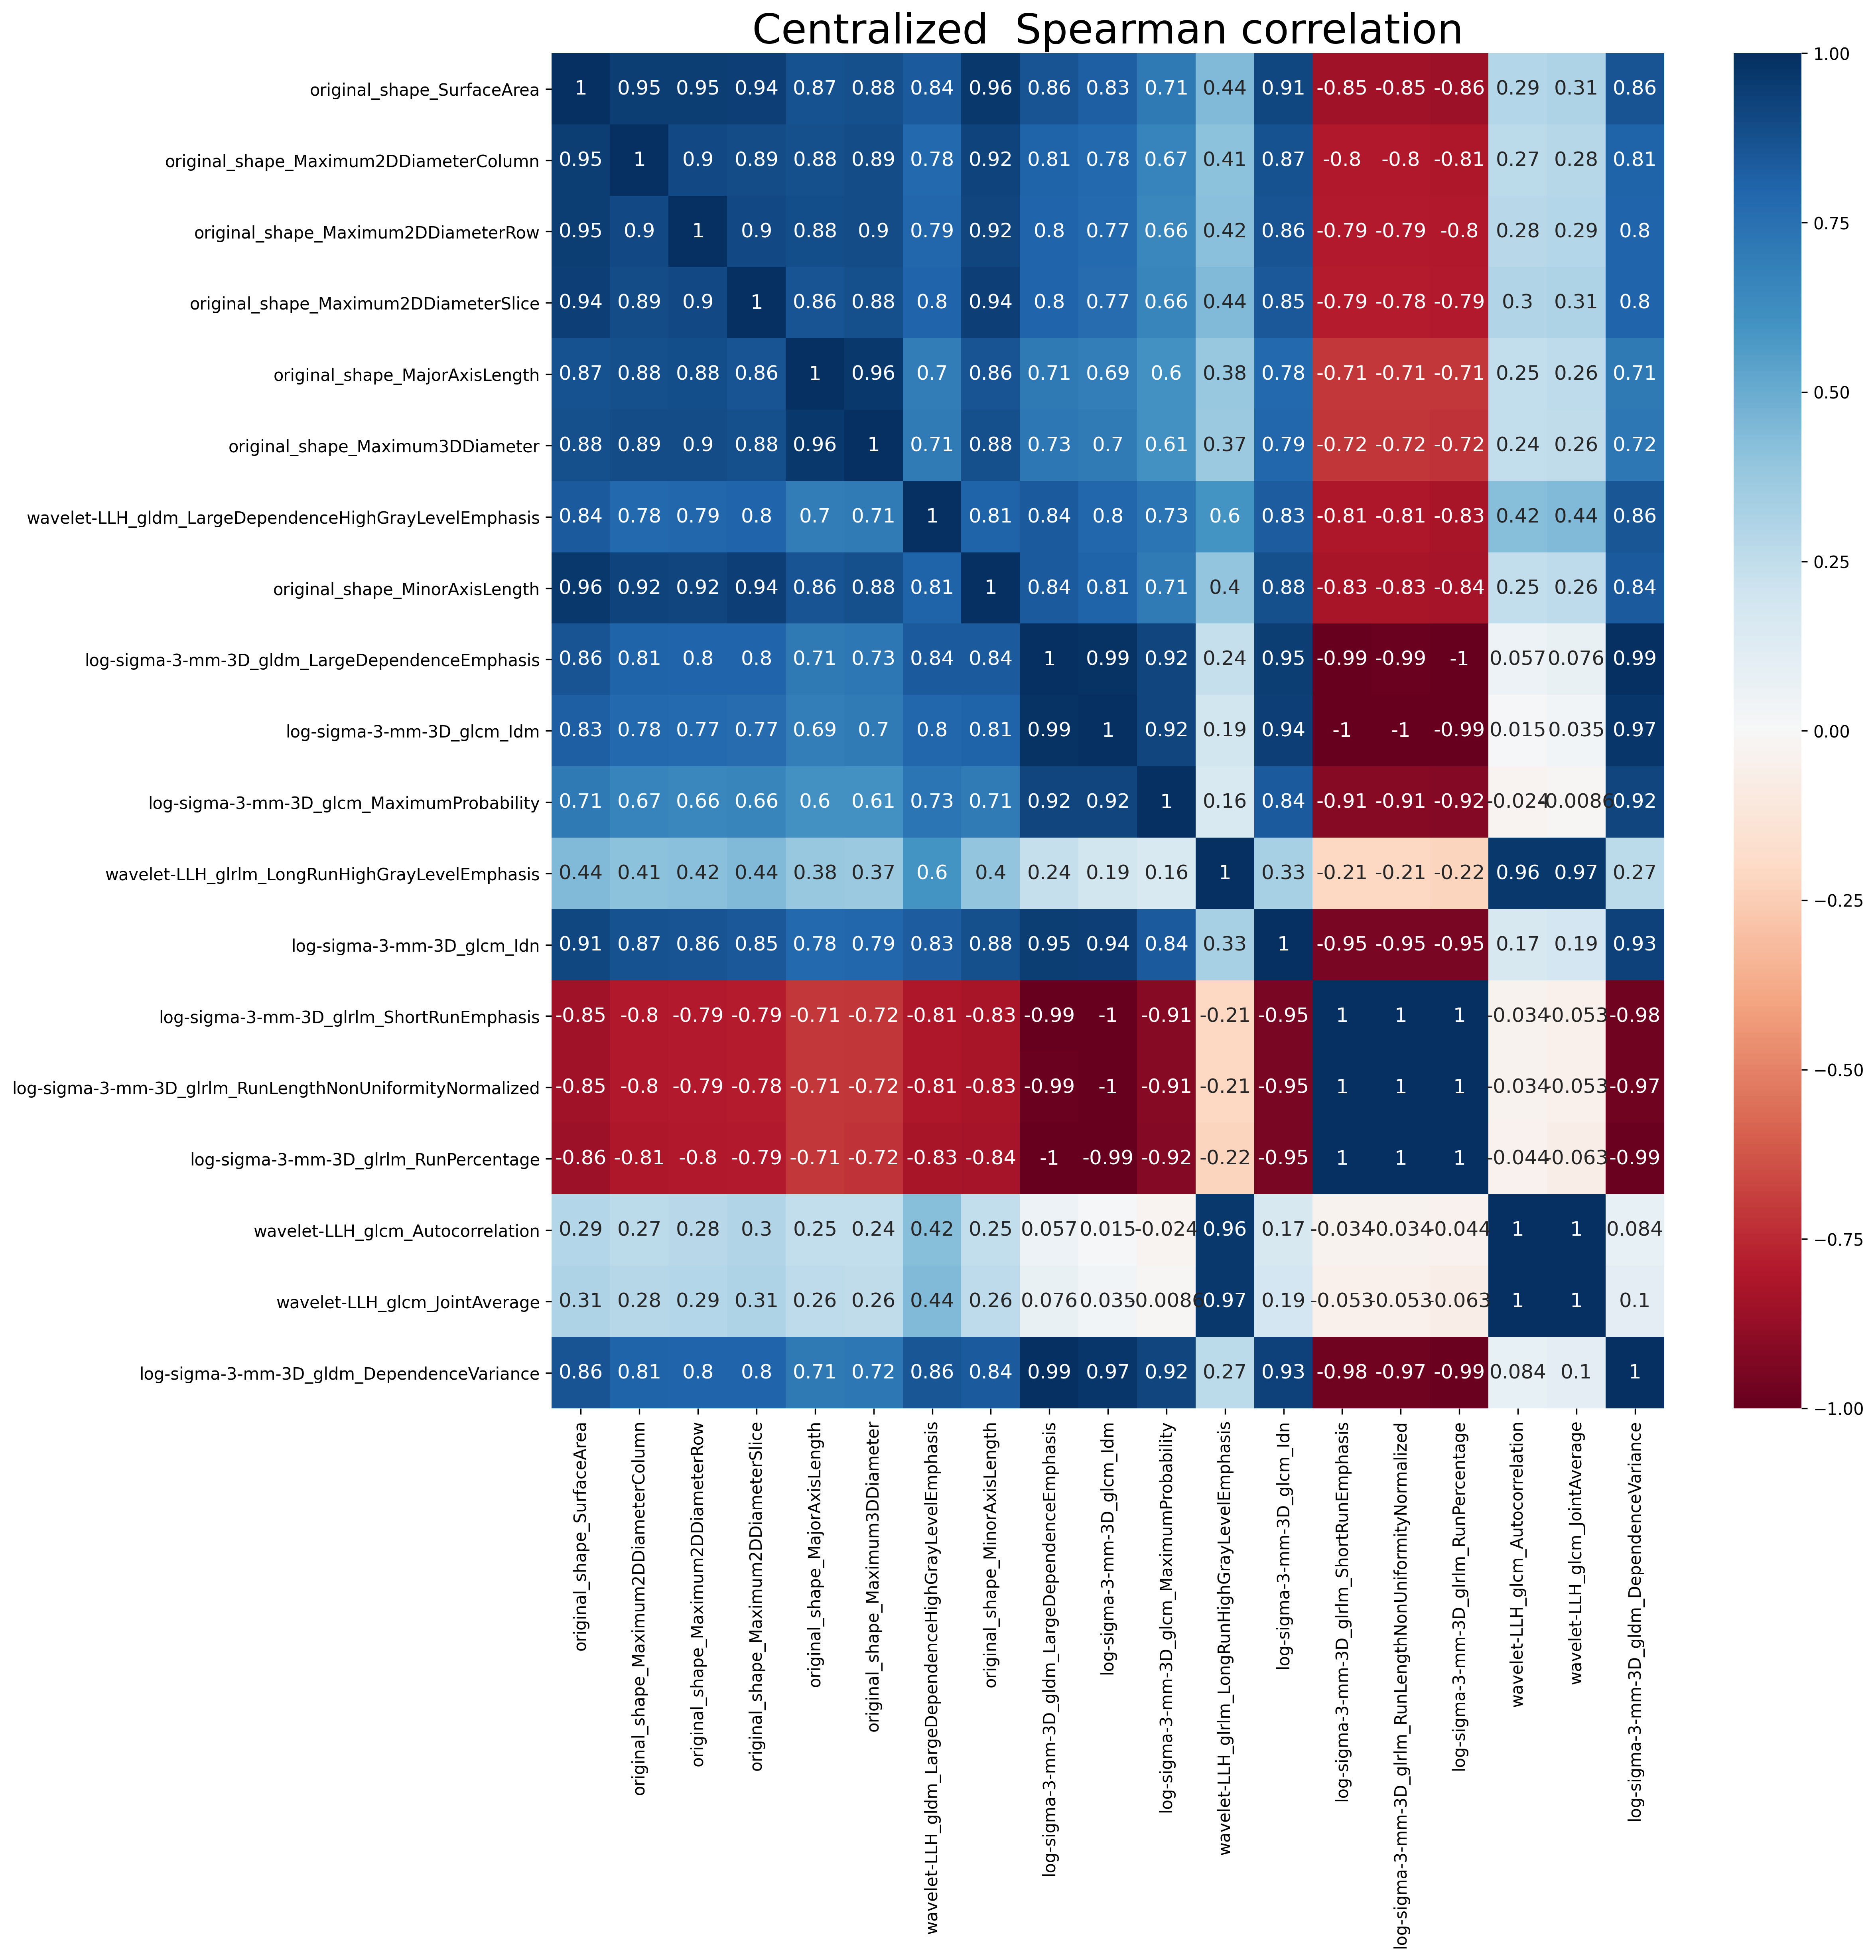

In [110]:
sns.heatmap(gb_s200u_central, xticklabels=gb_s200u_central.columns.values,
             yticklabels=gb_s200u_central.columns.values, annot=True,cmap='RdBu',annot_kws={'size':12},
              vmax=1,vmin=-1,)#.fig.suptitle('200_20_Global spearman correlation') 

#plt.figure(figsize=(15,15),dpi=300) 
plt.gcf().set_dpi(300)
plt.gcf().set_size_inches(15,15)

plt.title('Centralized  Spearman correlation',size='25')

Text(0.5, 1.0, 'Centralized  Spearman correlation')

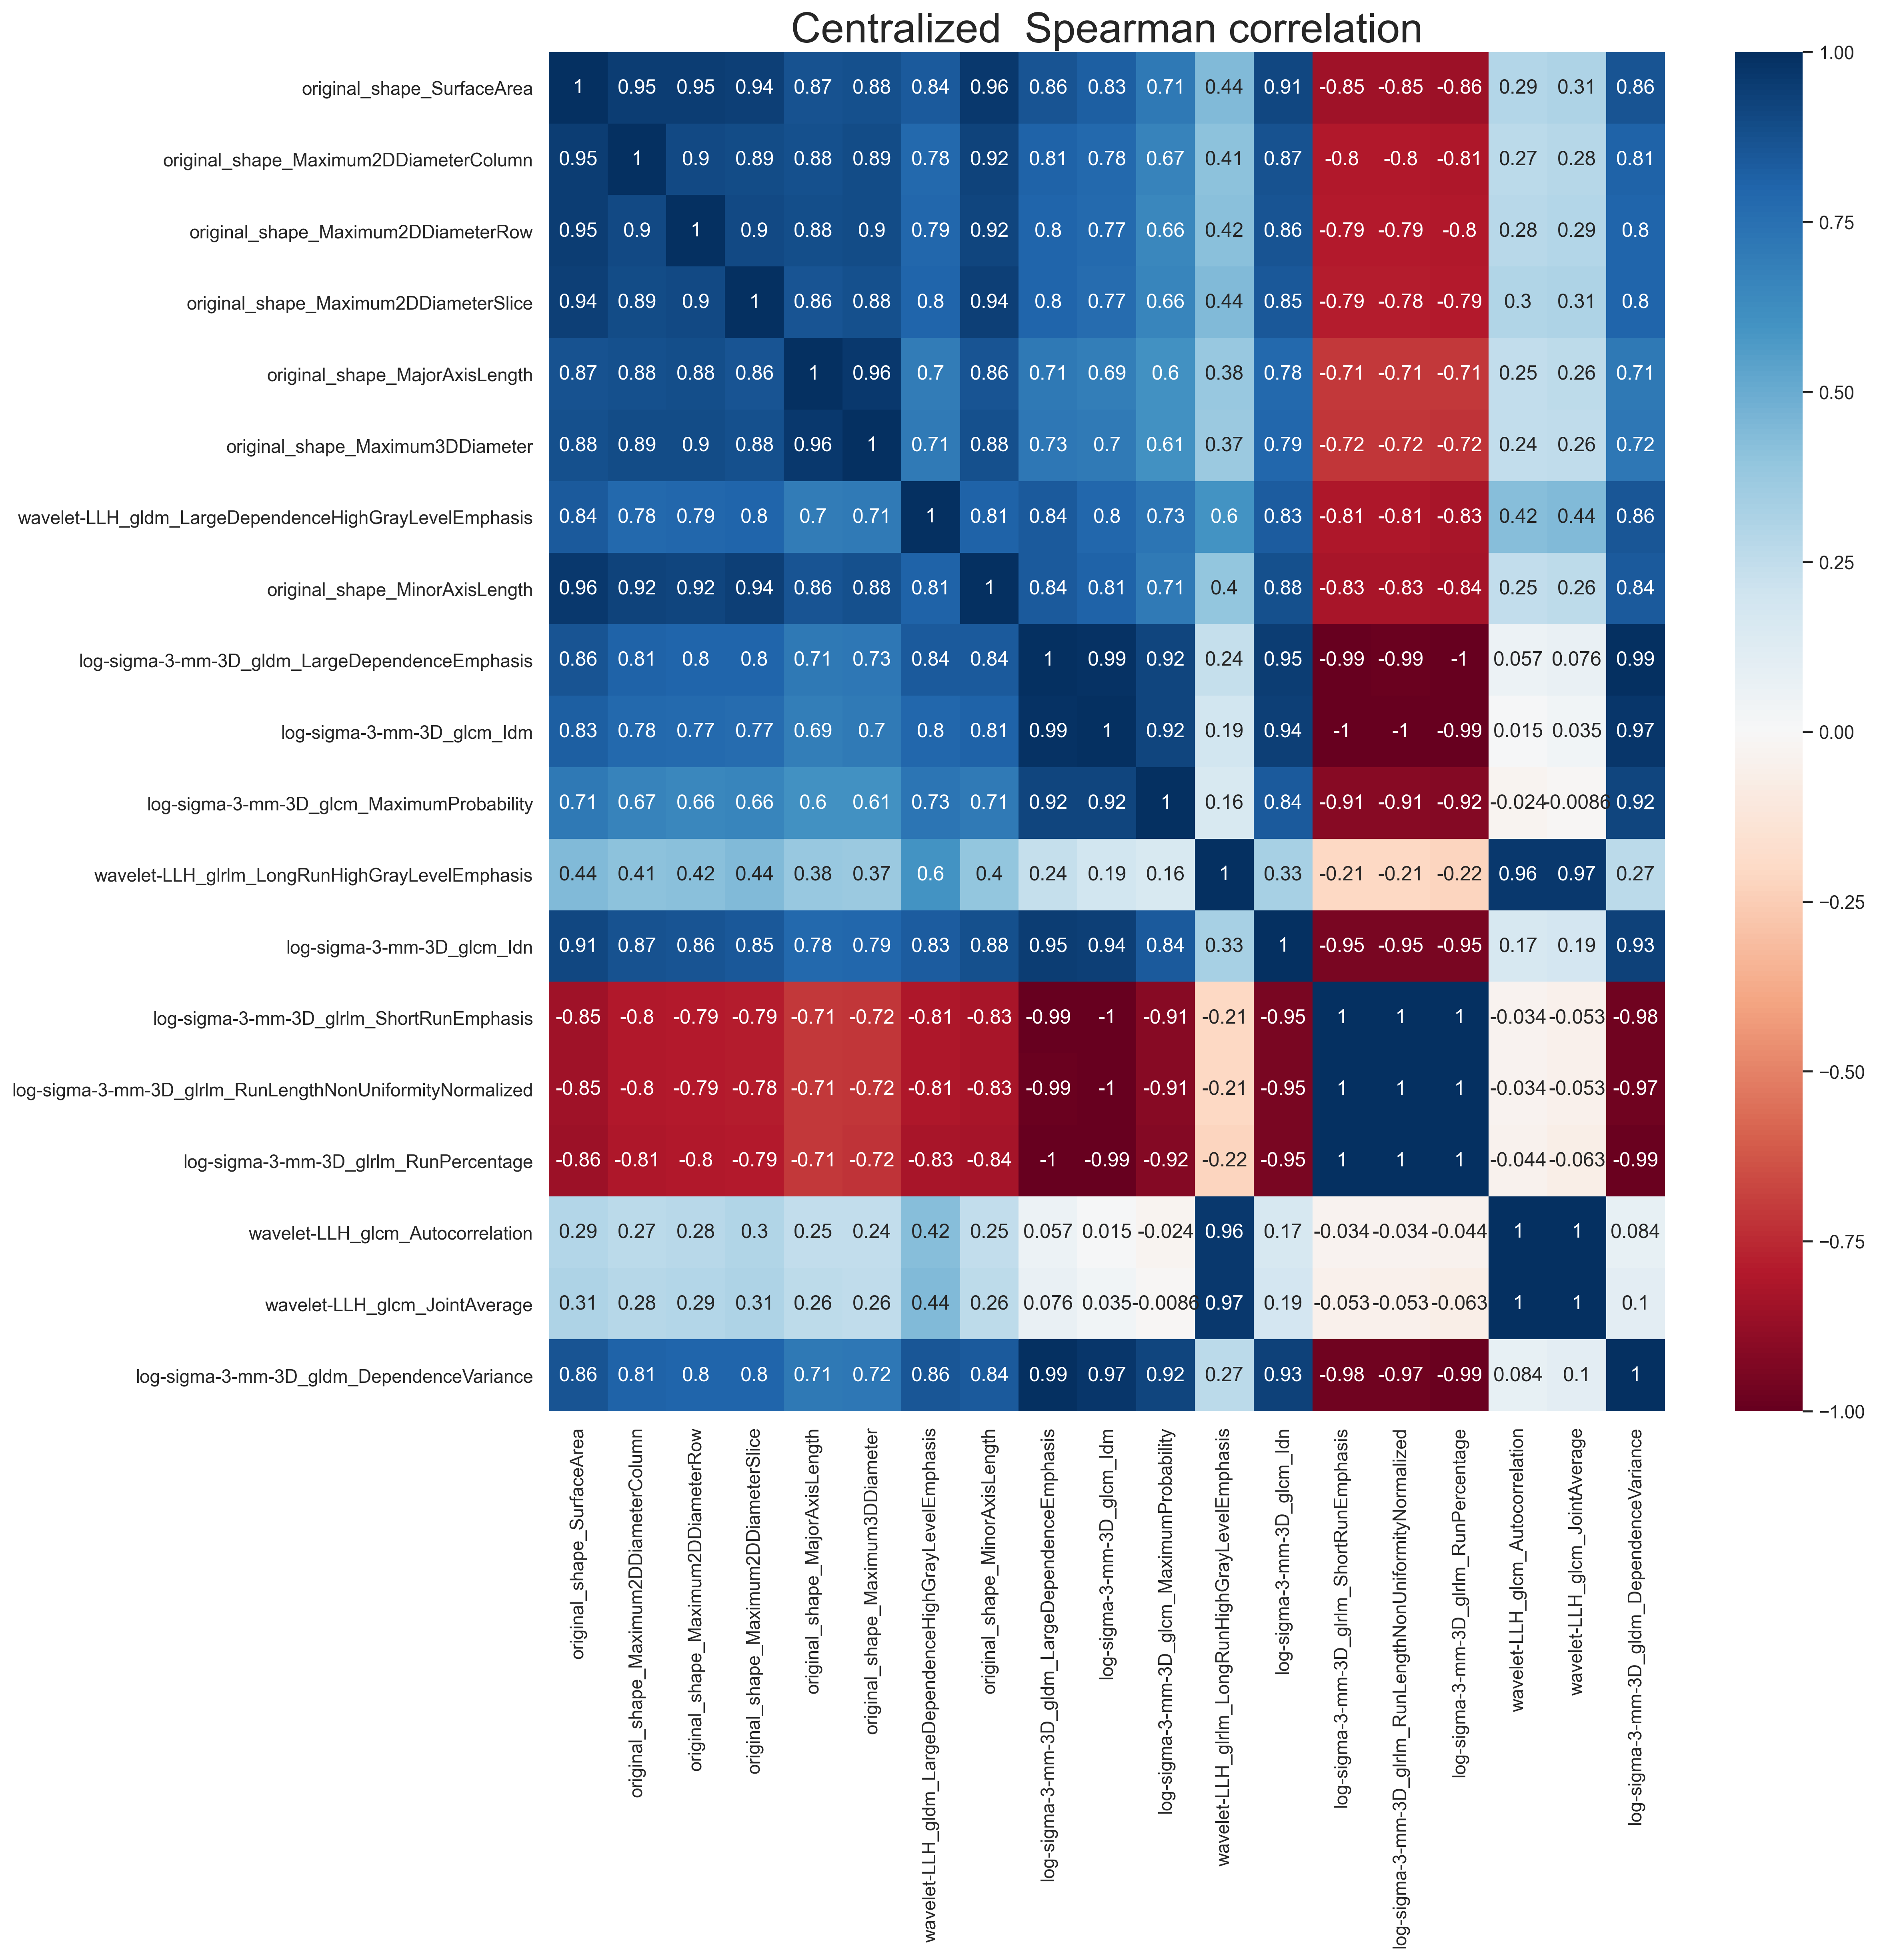

In [437]:
#old

Text(0.5, 1.0, 'Distributed spearman correlation')

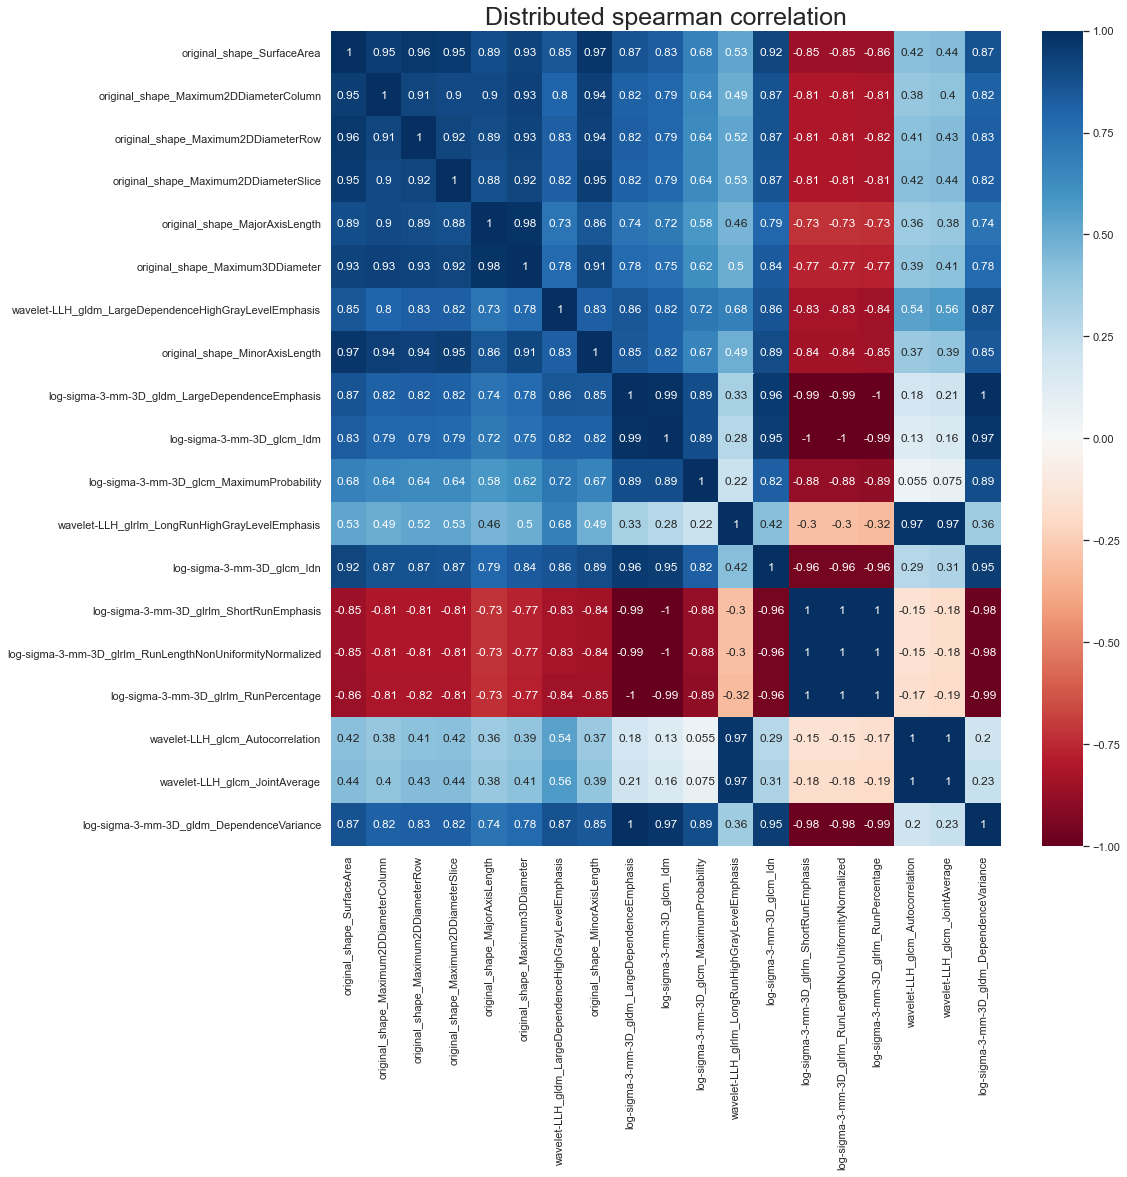

In [438]:
sns.heatmap(gb_s200u, xticklabels=gb_s200u.columns.values,
             yticklabels=gb_s200u.columns.values, annot=True,cmap='RdBu',annot_kws={'size':12},
              vmax=1,vmin=-1,)#.fig.suptitle('200_20_Global spearman correlation') 
plt.gcf().set_size_inches(15,15)
#plt.savefig('200_GLobal_z_scaled_UNICOX_20_Global_Pearson_stable_features_full.pdf',format='pdf')
plt.title('Distributed spearman correlation',size='25')

Text(0.5, 1.0, 'Distributed spearman correlation')

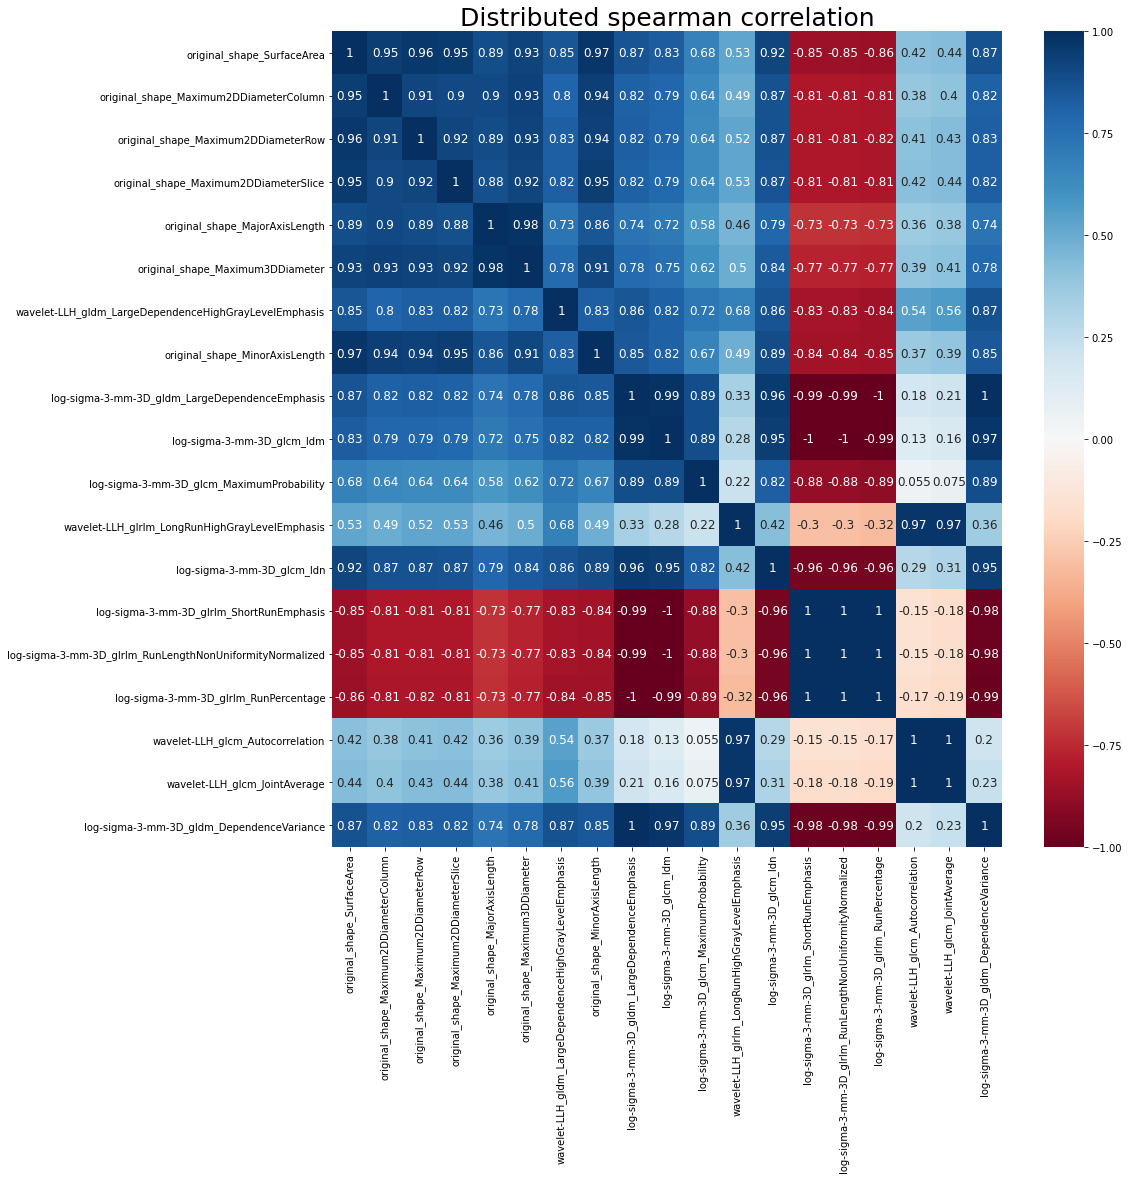

In [108]:
sns.heatmap(gb_s200u, xticklabels=gb_s200u.columns.values,
             yticklabels=gb_s200u.columns.values, annot=True,cmap='RdBu',annot_kws={'size':12},
              vmax=1,vmin=-1,)#.fig.suptitle('200_20_Global spearman correlation') 
plt.gcf().set_size_inches(15,15)
#plt.savefig('200_GLobal_z_scaled_UNICOX_20_Global_Pearson_stable_features_full.pdf',format='pdf')
plt.title('Distributed spearman correlation',size='25')

In [624]:
pwd

'D:\\gb_NLP_to_paper\\gb_nlp_scripts\\gb_nlp_scripts'

In [ ]:
GLobal_z_scaled_UNICOX_Global_spearman_20_stable_features_full.pdf

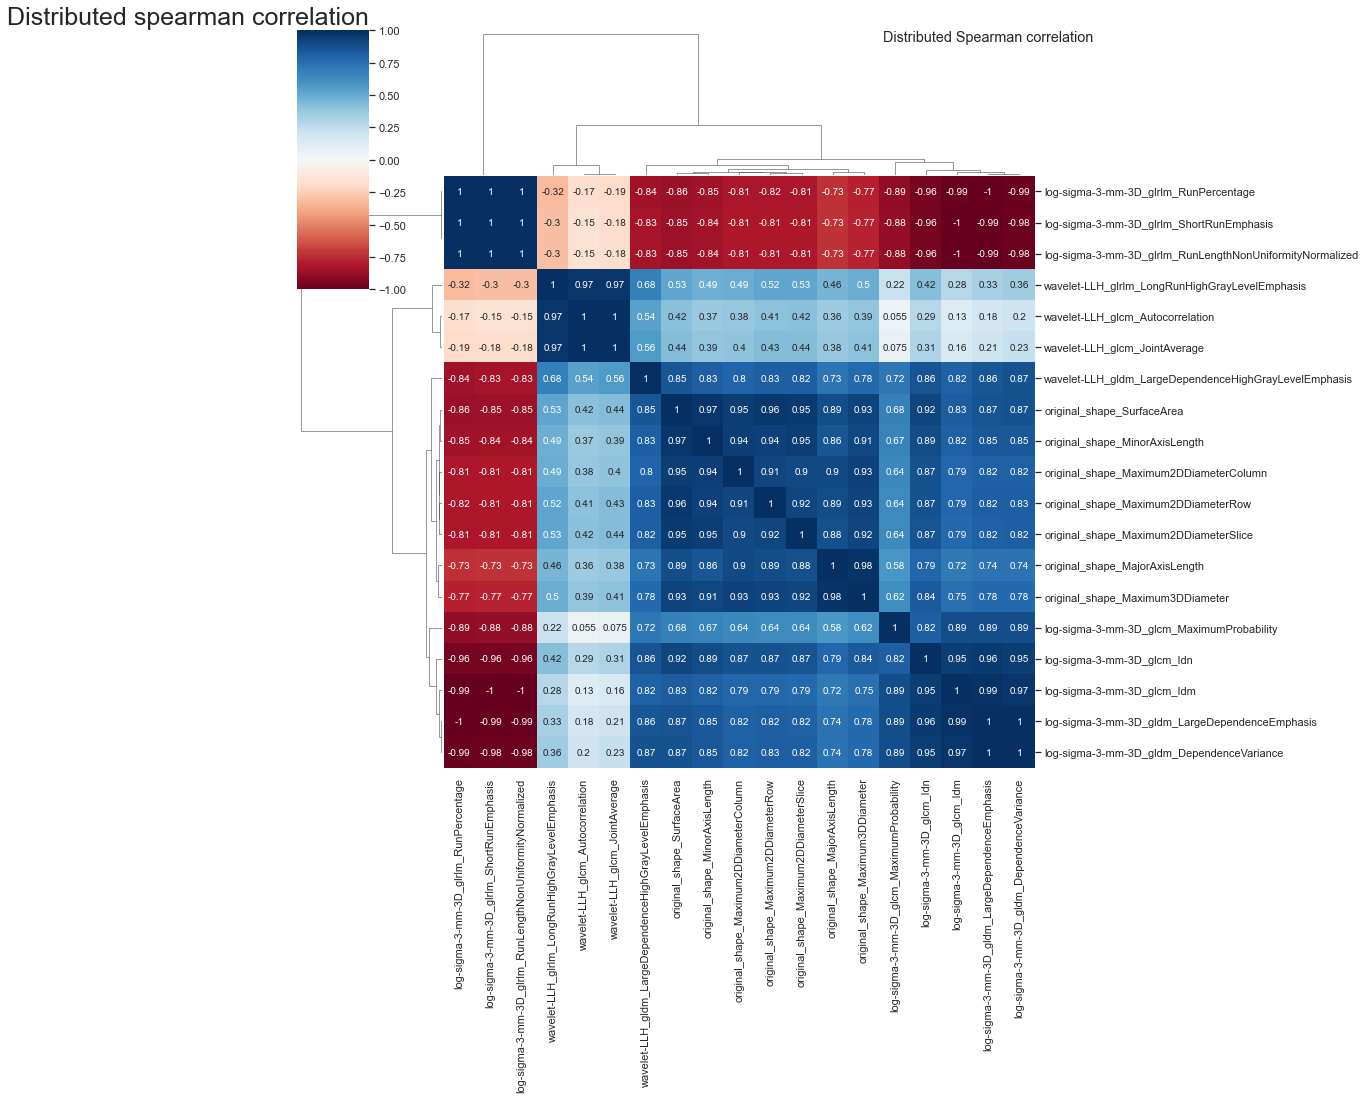

In [114]:
from matplotlib.pyplot import figure
sns.set(font_scale=1)
# applying mask
mask = np.triu(np.ones_like(gb_s200u))
#figure(figsize=(20,20), dpi=300)
sns.clustermap(gb_s200u, xticklabels=gb_s200u.columns.values,
             yticklabels=gb_s200u.columns.values, annot=True,cmap='RdBu',annot_kws={'size':10},
              vmax=1,vmin=-1,).fig.suptitle('Distributed Spearman correlation') 
plt.gcf().set_size_inches(20,20)
#plt.gcf().dpi(300)
plt.title('Distributed spearman correlation',size='25',loc='right')
#plt.savefig('GLobal_z_scaled_UNICOX_Global_spearman_20_stable_features_full.pdf',dpi=300, format='pdf')
plt.savefig('GLobal_z_scaled_UNICOX_Global_spearman_20_stable_features_full_aug.jpg',dpi=300, format='jpg')

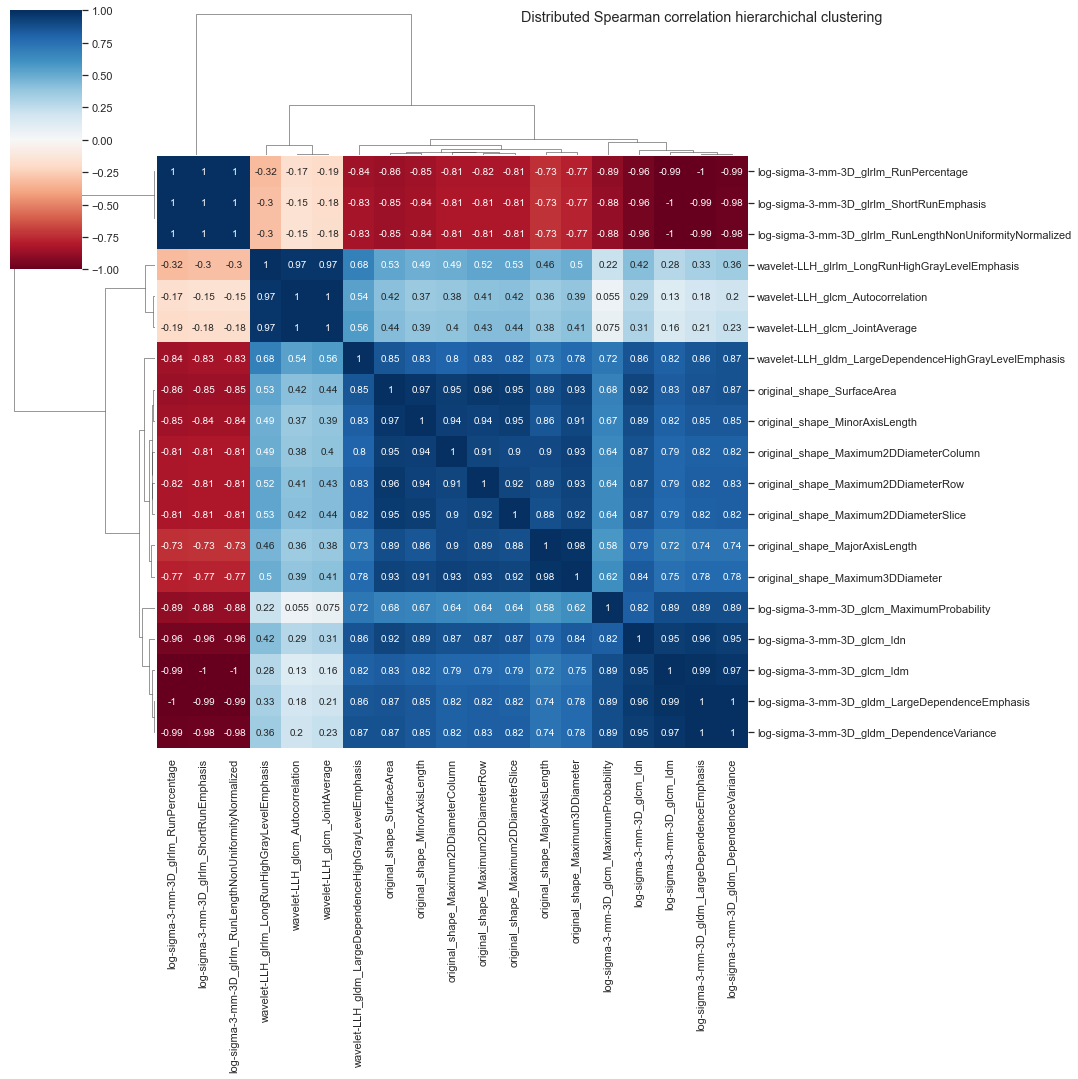

In [461]:
#

In [615]:
scipy.cluster.hierarchy.linkage()

<function scipy.cluster.hierarchy.linkage(y, method='single', metric='euclidean', optimal_ordering=False)>

In [224]:
gb_s200u

,original_shape_SurfaceArea,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_MajorAxisLength,original_shape_Maximum3DDiameter,wavelet-LLH_gldm_LargeDependenceHighGrayLevelEmphasis,original_shape_MinorAxisLength,log-sigma-3-mm-3D_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_glcm_Idm,log-sigma-3-mm-3D_glcm_MaximumProbability,wavelet-LLH_glrlm_LongRunHighGrayLevelEmphasis,log-sigma-3-mm-3D_glcm_Idn,log-sigma-3-mm-3D_glrlm_ShortRunEmphasis,log-sigma-3-mm-3D_glrlm_RunLengthNonUniformityNormalized,log-sigma-3-mm-3D_glrlm_RunPercentage,wavelet-LLH_glcm_Autocorrelation,wavelet-LLH_glcm_JointAverage,log-sigma-3-mm-3D_gldm_DependenceVariance
original_shape_SurfaceArea,1.000000,0.949468,0.963788,0.953469,0.889215,0.928132,0.853190,0.971711,0.867122,0.833923,0.678620,0.531166,0.915236,-0.853901,-0.853754,-0.860810,0.415087,0.435917,0.868144
original_shape_Maximum2DDiameterColumn,0.949468,1.000000,0.914169,0.899112,0.899577,0.934426,0.799446,0.937823,0.818195,0.789291,0.641792,0.492479,0.871485,-0.807284,-0.807157,-0.812858,0.383527,0.403131,0.817224
original_shape_Maximum2DDiameterRow,0.963788,0.914169,1.000000,0.918598,0.894564,0.928432,0.826922,0.936199,0.823836,0.791661,0.639707,0.524490,0.873818,-0.809494,-0.809270,-0.816433,0.413252,0.433101,0.826797
original_shape_Maximum2DDiameterSlice,0.953469,0.899112,0.918598,1.000000,0.875489,0.915576,0.822264,0.951717,0.819553,0.787804,0.637428,0.527994,0.865158,-0.805443,-0.805149,-0.812894,0.416861,0.436380,0.821706
original_shape_MajorAxisLength,0.889215,0.899577,0.894564,0.875489,1.000000,0.977386,0.730796,0.859303,0.736997,0.715030,0.584248,0.463766,0.792294,-0.726544,-0.726178,-0.731558,0.363433,0.380668,0.736875
original_shape_Maximum3DDiameter,0.928132,0.934426,0.928432,0.915576,0.977386,1.000000,0.779348,0.906934,0.779573,0.753097,0.620362,0.498888,0.836055,-0.767807,-0.767464,-0.773607,0.392786,0.410760,0.779901
wavelet-LLH_gldm_LargeDependenceHighGrayLevelEmphasis,0.853190,0.799446,0.826922,0.822264,0.730796,0.779348,1.000000,0.825194,0.856547,0.818671,0.719667,0.683234,0.859476,-0.831432,-0.830692,-0.843993,0.544356,0.563650,0.870146
original_shape_MinorAxisLength,0.971711,0.937823,0.936199,0.951717,0.859303,0.906934,0.825194,1.000000,0.851078,0.819045,0.667829,0.491884,0.894544,-0.838621,-0.838476,-0.845335,0.374256,0.394643,0.851058
log-sigma-3-mm-3D_gldm_LargeDependenceEmphasis,0.867122,0.818195,0.823836,0.819553,0.736997,0.779573,0.856547,0.851078,1.000000,0.988156,0.889973,0.332565,0.958521,-0.993392,-0.992965,-0.997734,0.180443,0.205477,0.995315
log-sigma-3-mm-3D_glcm_Idm,0.833923,0.789291,0.791661,0.787804,0.715030,0.753097,0.818671,0.819045,0.988156,1.000000,0.888092,0.281908,0.951393,-0.997264,-0.997244,-0.994980,0.134663,0.160384,0.973099


In [109]:
gb_s200u_central=merged_cent_scaled[gb_s200u.columns].corr(method='spearman')


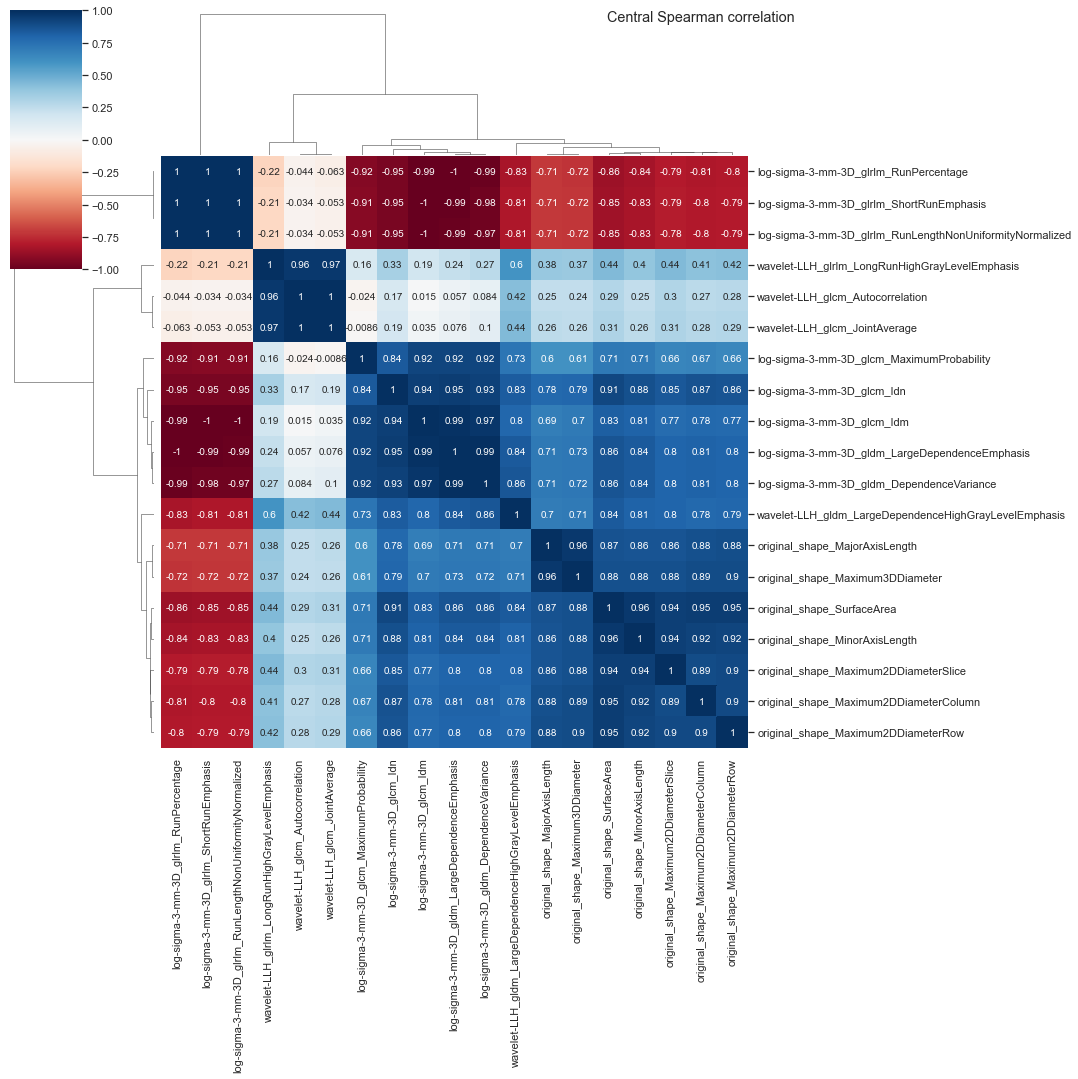

In [462]:
sns.clustermap(gb_s200u_central, xticklabels=gb_s200u_central.columns.values,
             yticklabels=gb_s200u_central.columns.values, annot=True,cmap='RdBu',annot_kws={'size':10},
              vmax=1,vmin=-1,).fig.suptitle('Central Spearman correlation',) 
plt.gcf().set_size_inches(20,20)

### kmeans of distributed spearman (gb_s200u) and centralized spearman (gb_s200u_central )

In [485]:
gb_s200u

,original_shape_SurfaceArea,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_MajorAxisLength,original_shape_Maximum3DDiameter,wavelet-LLH_gldm_LargeDependenceHighGrayLevelEmphasis,original_shape_MinorAxisLength,log-sigma-3-mm-3D_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_glcm_Idm,log-sigma-3-mm-3D_glcm_MaximumProbability,wavelet-LLH_glrlm_LongRunHighGrayLevelEmphasis,log-sigma-3-mm-3D_glcm_Idn,log-sigma-3-mm-3D_glrlm_ShortRunEmphasis,log-sigma-3-mm-3D_glrlm_RunLengthNonUniformityNormalized,log-sigma-3-mm-3D_glrlm_RunPercentage,wavelet-LLH_glcm_Autocorrelation,wavelet-LLH_glcm_JointAverage,log-sigma-3-mm-3D_gldm_DependenceVariance
original_shape_SurfaceArea,1.000000,0.949468,0.963788,0.953469,0.889215,0.928132,0.853190,0.971711,0.867122,0.833923,0.678620,0.531166,0.915236,-0.853901,-0.853754,-0.860810,0.415087,0.435917,0.868144
original_shape_Maximum2DDiameterColumn,0.949468,1.000000,0.914169,0.899112,0.899577,0.934426,0.799446,0.937823,0.818195,0.789291,0.641792,0.492479,0.871485,-0.807284,-0.807157,-0.812858,0.383527,0.403131,0.817224
original_shape_Maximum2DDiameterRow,0.963788,0.914169,1.000000,0.918598,0.894564,0.928432,0.826922,0.936199,0.823836,0.791661,0.639707,0.524490,0.873818,-0.809494,-0.809270,-0.816433,0.413252,0.433101,0.826797
original_shape_Maximum2DDiameterSlice,0.953469,0.899112,0.918598,1.000000,0.875489,0.915576,0.822264,0.951717,0.819553,0.787804,0.637428,0.527994,0.865158,-0.805443,-0.805149,-0.812894,0.416861,0.436380,0.821706
original_shape_MajorAxisLength,0.889215,0.899577,0.894564,0.875489,1.000000,0.977386,0.730796,0.859303,0.736997,0.715030,0.584248,0.463766,0.792294,-0.726544,-0.726178,-0.731558,0.363433,0.380668,0.736875
original_shape_Maximum3DDiameter,0.928132,0.934426,0.928432,0.915576,0.977386,1.000000,0.779348,0.906934,0.779573,0.753097,0.620362,0.498888,0.836055,-0.767807,-0.767464,-0.773607,0.392786,0.410760,0.779901
wavelet-LLH_gldm_LargeDependenceHighGrayLevelEmphasis,0.853190,0.799446,0.826922,0.822264,0.730796,0.779348,1.000000,0.825194,0.856547,0.818671,0.719667,0.683234,0.859476,-0.831432,-0.830692,-0.843993,0.544356,0.563650,0.870146
original_shape_MinorAxisLength,0.971711,0.937823,0.936199,0.951717,0.859303,0.906934,0.825194,1.000000,0.851078,0.819045,0.667829,0.491884,0.894544,-0.838621,-0.838476,-0.845335,0.374256,0.394643,0.851058
log-sigma-3-mm-3D_gldm_LargeDependenceEmphasis,0.867122,0.818195,0.823836,0.819553,0.736997,0.779573,0.856547,0.851078,1.000000,0.988156,0.889973,0.332565,0.958521,-0.993392,-0.992965,-0.997734,0.180443,0.205477,0.995315
log-sigma-3-mm-3D_glcm_Idm,0.833923,0.789291,0.791661,0.787804,0.715030,0.753097,0.818671,0.819045,0.988156,1.000000,0.888092,0.281908,0.951393,-0.997264,-0.997244,-0.994980,0.134663,0.160384,0.973099


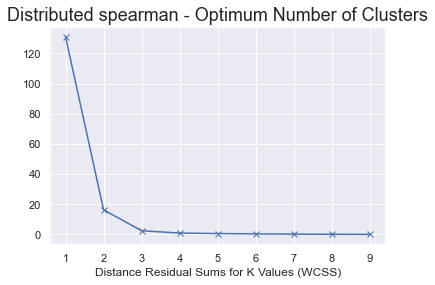

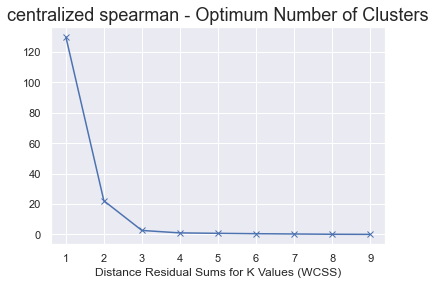

In [491]:
### KMEANS CLUSTERING

from sklearn.cluster import KMeans

# **5 KMeans Clustering
kmeans = KMeans()
ssd = []
K = range(1, 10)

for k in K:
    kmeans = KMeans(n_clusters=k).fit(gb_s200u)
    ssd.append(kmeans.inertia_)

ssd

plt.plot(K, ssd, "bx-")
plt.xlabel("Distance Residual Sums for K Values (WCSS)")
plt.title("Distributed spearman - Optimum Number of Clusters",fontsize=18)
plt.show()

kmeans = KMeans()
ssd = []
K = range(1, 10)

for k in K:
    kmeans = KMeans(n_clusters=k).fit(gb_s200u_central)
    ssd.append(kmeans.inertia_)

ssd

plt.plot(K, ssd, "bx-")
plt.xlabel("Distance Residual Sums for K Values (WCSS)")
plt.title("centralized spearman - Optimum Number of Clusters",fontsize=18)
plt.show()

In [495]:
gb_s200u

,original_shape_SurfaceArea,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_MajorAxisLength,original_shape_Maximum3DDiameter,wavelet-LLH_gldm_LargeDependenceHighGrayLevelEmphasis,original_shape_MinorAxisLength,log-sigma-3-mm-3D_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_glcm_Idm,log-sigma-3-mm-3D_glcm_MaximumProbability,wavelet-LLH_glrlm_LongRunHighGrayLevelEmphasis,log-sigma-3-mm-3D_glcm_Idn,log-sigma-3-mm-3D_glrlm_ShortRunEmphasis,log-sigma-3-mm-3D_glrlm_RunLengthNonUniformityNormalized,log-sigma-3-mm-3D_glrlm_RunPercentage,wavelet-LLH_glcm_Autocorrelation,wavelet-LLH_glcm_JointAverage,log-sigma-3-mm-3D_gldm_DependenceVariance
original_shape_SurfaceArea,1.000000,0.949468,0.963788,0.953469,0.889215,0.928132,0.853190,0.971711,0.867122,0.833923,0.678620,0.531166,0.915236,-0.853901,-0.853754,-0.860810,0.415087,0.435917,0.868144
original_shape_Maximum2DDiameterColumn,0.949468,1.000000,0.914169,0.899112,0.899577,0.934426,0.799446,0.937823,0.818195,0.789291,0.641792,0.492479,0.871485,-0.807284,-0.807157,-0.812858,0.383527,0.403131,0.817224
original_shape_Maximum2DDiameterRow,0.963788,0.914169,1.000000,0.918598,0.894564,0.928432,0.826922,0.936199,0.823836,0.791661,0.639707,0.524490,0.873818,-0.809494,-0.809270,-0.816433,0.413252,0.433101,0.826797
original_shape_Maximum2DDiameterSlice,0.953469,0.899112,0.918598,1.000000,0.875489,0.915576,0.822264,0.951717,0.819553,0.787804,0.637428,0.527994,0.865158,-0.805443,-0.805149,-0.812894,0.416861,0.436380,0.821706
original_shape_MajorAxisLength,0.889215,0.899577,0.894564,0.875489,1.000000,0.977386,0.730796,0.859303,0.736997,0.715030,0.584248,0.463766,0.792294,-0.726544,-0.726178,-0.731558,0.363433,0.380668,0.736875
original_shape_Maximum3DDiameter,0.928132,0.934426,0.928432,0.915576,0.977386,1.000000,0.779348,0.906934,0.779573,0.753097,0.620362,0.498888,0.836055,-0.767807,-0.767464,-0.773607,0.392786,0.410760,0.779901
wavelet-LLH_gldm_LargeDependenceHighGrayLevelEmphasis,0.853190,0.799446,0.826922,0.822264,0.730796,0.779348,1.000000,0.825194,0.856547,0.818671,0.719667,0.683234,0.859476,-0.831432,-0.830692,-0.843993,0.544356,0.563650,0.870146
original_shape_MinorAxisLength,0.971711,0.937823,0.936199,0.951717,0.859303,0.906934,0.825194,1.000000,0.851078,0.819045,0.667829,0.491884,0.894544,-0.838621,-0.838476,-0.845335,0.374256,0.394643,0.851058
log-sigma-3-mm-3D_gldm_LargeDependenceEmphasis,0.867122,0.818195,0.823836,0.819553,0.736997,0.779573,0.856547,0.851078,1.000000,0.988156,0.889973,0.332565,0.958521,-0.993392,-0.992965,-0.997734,0.180443,0.205477,0.995315
log-sigma-3-mm-3D_glcm_Idm,0.833923,0.789291,0.791661,0.787804,0.715030,0.753097,0.818671,0.819045,0.988156,1.000000,0.888092,0.281908,0.951393,-0.997264,-0.997244,-0.994980,0.134663,0.160384,0.973099


In [496]:
gb_s200u_central

,original_shape_SurfaceArea,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_MajorAxisLength,original_shape_Maximum3DDiameter,wavelet-LLH_gldm_LargeDependenceHighGrayLevelEmphasis,original_shape_MinorAxisLength,log-sigma-3-mm-3D_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_glcm_Idm,log-sigma-3-mm-3D_glcm_MaximumProbability,wavelet-LLH_glrlm_LongRunHighGrayLevelEmphasis,log-sigma-3-mm-3D_glcm_Idn,log-sigma-3-mm-3D_glrlm_ShortRunEmphasis,log-sigma-3-mm-3D_glrlm_RunLengthNonUniformityNormalized,log-sigma-3-mm-3D_glrlm_RunPercentage,wavelet-LLH_glcm_Autocorrelation,wavelet-LLH_glcm_JointAverage,log-sigma-3-mm-3D_gldm_DependenceVariance
original_shape_SurfaceArea,1.000000,0.948819,0.950571,0.942009,0.874957,0.880310,0.836639,0.961678,0.861646,0.828051,0.711431,0.440364,0.912783,-0.847369,-0.847182,-0.855621,0.290178,0.306238,0.861137
original_shape_Maximum2DDiameterColumn,0.948819,1.000000,0.900093,0.890637,0.882682,0.891920,0.783618,0.922092,0.812375,0.784700,0.670979,0.407938,0.871881,-0.801525,-0.801453,-0.807733,0.267760,0.283002,0.809447
original_shape_Maximum2DDiameterRow,0.950571,0.900093,1.000000,0.899857,0.883129,0.898401,0.789436,0.915341,0.803945,0.774013,0.655609,0.417548,0.863693,-0.791983,-0.791900,-0.798584,0.275990,0.290823,0.801768
original_shape_Maximum2DDiameterSlice,0.942009,0.890637,0.899857,1.000000,0.864058,0.881311,0.796913,0.942830,0.801489,0.768621,0.657913,0.439268,0.851480,-0.785215,-0.784890,-0.794606,0.297267,0.311908,0.804492
original_shape_MajorAxisLength,0.874957,0.882682,0.883129,0.864058,1.000000,0.963873,0.696166,0.860599,0.714730,0.693740,0.601859,0.375052,0.784603,-0.705569,-0.705348,-0.710563,0.246863,0.259392,0.711599
original_shape_Maximum3DDiameter,0.880310,0.891920,0.898401,0.881311,0.963873,1.000000,0.710585,0.875996,0.726005,0.703280,0.605294,0.371700,0.794506,-0.716715,-0.716604,-0.721704,0.243345,0.256175,0.723474
wavelet-LLH_gldm_LargeDependenceHighGrayLevelEmphasis,0.836639,0.783618,0.789436,0.796913,0.696166,0.710585,1.000000,0.806367,0.839439,0.796425,0.733019,0.601343,0.833813,-0.810002,-0.809135,-0.825775,0.423229,0.438518,0.859358
original_shape_MinorAxisLength,0.961678,0.922092,0.915341,0.942830,0.860599,0.875996,0.806367,1.000000,0.841591,0.807718,0.705857,0.398418,0.882679,-0.826247,-0.826012,-0.835355,0.247652,0.263007,0.842148
log-sigma-3-mm-3D_gldm_LargeDependenceEmphasis,0.861646,0.812375,0.803945,0.801489,0.714730,0.726005,0.839439,0.841591,1.000000,0.987933,0.920345,0.237383,0.947404,-0.992513,-0.991932,-0.997830,0.057447,0.076333,0.993107
log-sigma-3-mm-3D_glcm_Idm,0.828051,0.784700,0.774013,0.768621,0.693740,0.703280,0.796425,0.807718,0.987933,1.000000,0.916087,0.188187,0.940855,-0.997591,-0.997560,-0.994836,0.015276,0.034653,0.969304


In [1]:
from sklearn.datasets import make_blobs
from sklearn.cluster  import KMeans
from sklearn.metrics  import silhouette_samples, silhouette_score

import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

In [ ]:
silhouette_score()

For n_clusters = 2 The average silhouette_score is : 0.8472472372243065
For n_clusters = 3 The average silhouette_score is : 0.8196457713066326
For n_clusters = 4 The average silhouette_score is : 0.6848776180515168
For n_clusters = 5 The average silhouette_score is : 0.6715188161516581
For n_clusters = 6 The average silhouette_score is : 0.6413076446634378


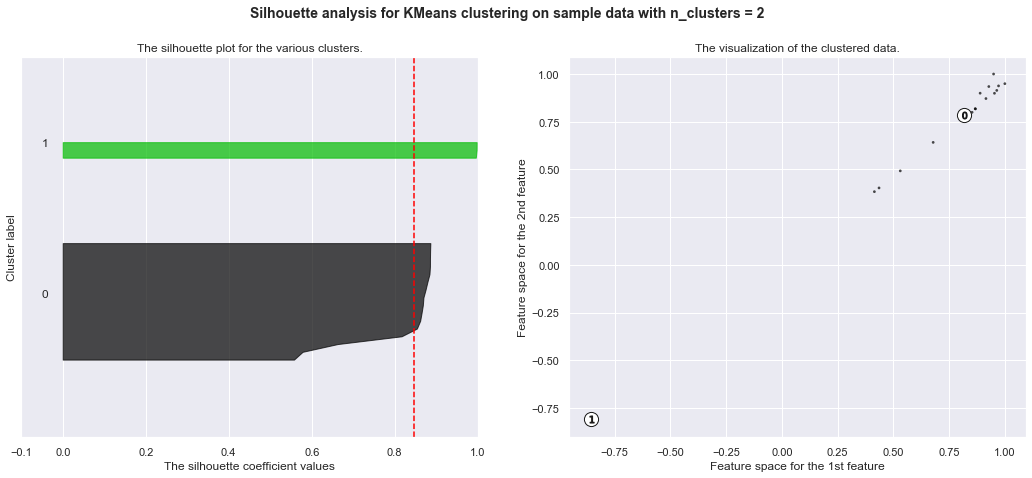

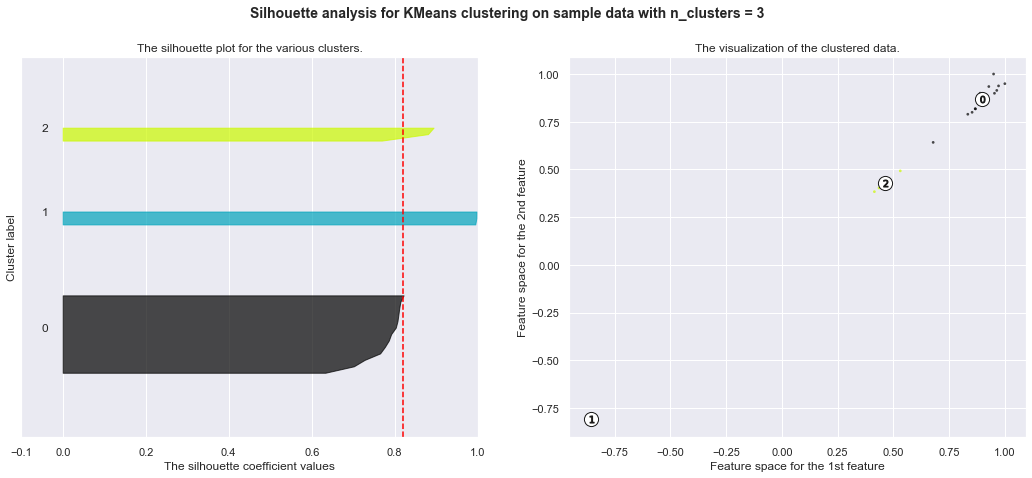

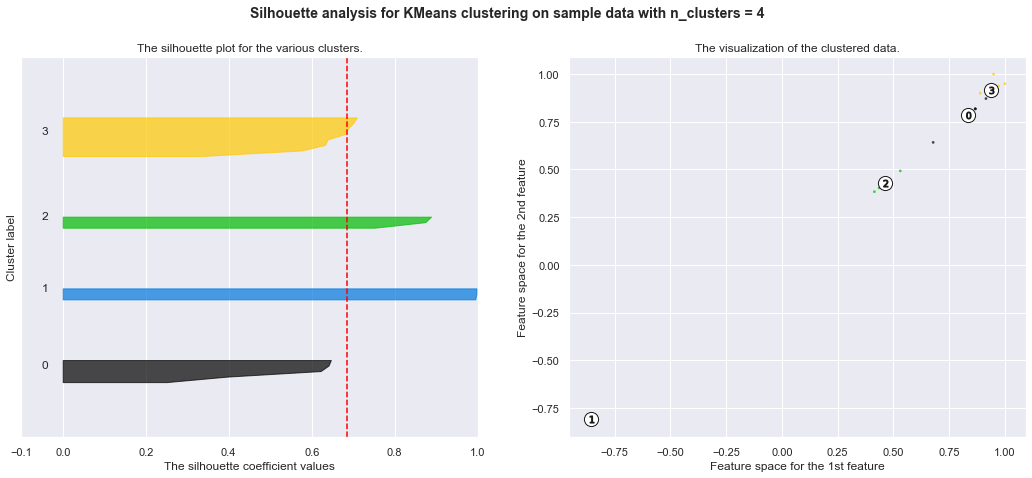

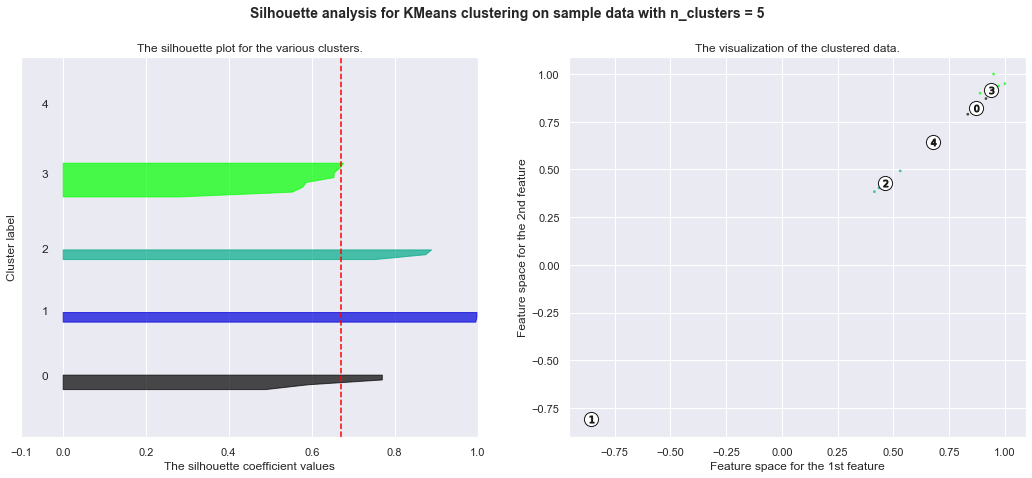

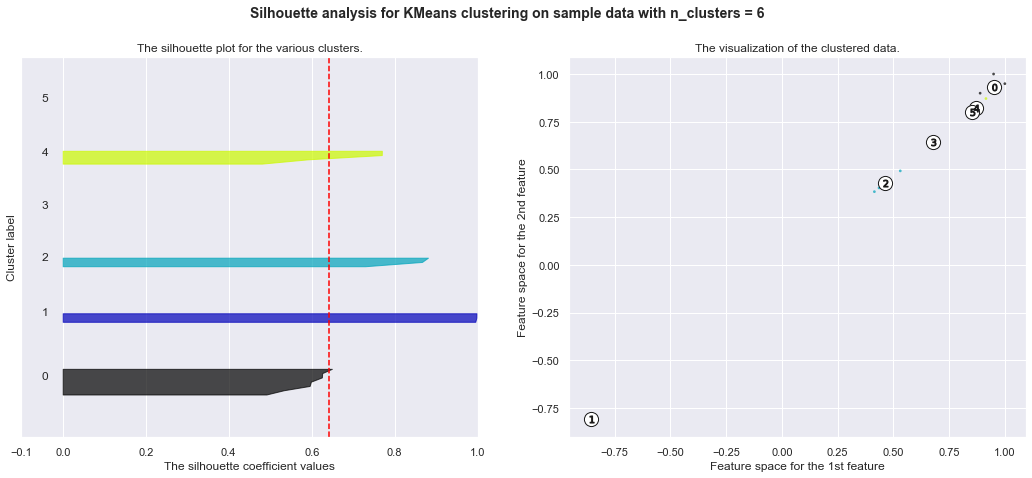

In [502]:
#X=np.array(gb_s200u_central) # centralized 
X=np.array(gb_s200u)         # distributed


len(X)

# Generating the sample data from make_blobs
# This particular setting has one distinct cluster and 3 clusters placed close
# together.
import matplotlib
import matplotlib.pyplot as plt
range_n_clusters = [2, 3, 4, 5, 6]

for n_clusters in range_n_clusters:
    # Create a subplot with 1 row and 2 columns
    fig, (ax1, ax2) = plt.subplots(1, 2)
    fig.set_size_inches(18, 7)

    # The 1st subplot is the silhouette plot
    # The silhouette coefficient can range from -1, 1 but in this example all
    # lie within [-0.1, 1]
    ax1.set_xlim([-0.1, 1])
    # The (n_clusters+1)*10 is for inserting blank space between silhouette
    # plots of individual clusters, to demarcate them clearly.
    ax1.set_ylim([0, len(X) + (n_clusters + 1) * 10])

    # Initialize the clusterer with n_clusters value and a random generator
    # seed of 10 for reproducibility.
    clusterer = KMeans(n_clusters=n_clusters, random_state=10)
    cluster_labels = clusterer.fit_predict(X)

    # The silhouette_score gives the average value for all the samples.
    # This gives a perspective into the density and separation of the formed
    # clusters
    silhouette_avg = silhouette_score(X, cluster_labels)
    print(
        "For n_clusters =",
        n_clusters,
        "The average silhouette_score is :",
        silhouette_avg,
    )

    # Compute the silhouette scores for each sample
    sample_silhouette_values = silhouette_samples(X, cluster_labels)

    y_lower = 10
    for i in range(n_clusters):
        # Aggregate the silhouette scores for samples belonging to
        # cluster i, and sort them
        ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]

        ith_cluster_silhouette_values.sort()

        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i

        color = cm.nipy_spectral(float(i) / n_clusters)
        ax1.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            ith_cluster_silhouette_values,
            facecolor=color,
            edgecolor=color,
            alpha=0.7,
        )

        # Label the silhouette plots with their cluster numbers at the middle
        ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))

        # Compute the new y_lower for next plot
        y_lower = y_upper + 10  # 10 for the 0 samples

    ax1.set_title("The silhouette plot for the various clusters.")
    ax1.set_xlabel("The silhouette coefficient values")
    ax1.set_ylabel("Cluster label")

    # The vertical line for average silhouette score of all the values
    ax1.axvline(x=silhouette_avg, color="red", linestyle="--")

    ax1.set_yticks([])  # Clear the yaxis labels / ticks
    ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])

    # 2nd Plot showing the actual clusters formed
    colors = matplotlib.cm.nipy_spectral(cluster_labels.astype(float) / n_clusters)
    ax2.scatter(
        X[:, 0], X[:, 1], marker=".", s=30, lw=0, alpha=0.7, c=colors, edgecolor="k"
    )

    # Labeling the clusters
    centers = clusterer.cluster_centers_
    # Draw white circles at cluster centers
    ax2.scatter(
        centers[:, 0],
        centers[:, 1],
        marker="o",
        c="white",
        alpha=1,
        s=200,
        edgecolor="k",
    )

    for i, c in enumerate(centers):
        ax2.scatter(c[0], c[1], marker="$%d$" % i, alpha=1, s=50, edgecolor="k")

    ax2.set_title("The visualization of the clustered data.")
    ax2.set_xlabel("Feature space for the 1st feature")
    ax2.set_ylabel("Feature space for the 2nd feature")

    plt.suptitle(
        "Silhouette analysis for KMeans clustering on sample data with n_clusters = %d"
        % n_clusters,
        fontsize=14,
        fontweight="bold",
    )

plt.show()

### getting the medoid features


### centralized

In [111]:
from sklearn.metrics import pairwise_distances_argmin_min

#https://stackoverflow.com/questions/21660937/get-nearest-point-to-centroid-scikit-learn
#*gb ft
from sklearn.metrics import pairwise_distances_argmin_min
#X = np.random.randn(10, 4)
km = KMeans(n_clusters=3,random_state=88).fit(gb_s200u_central) # spearman
#km = KMeans(n_clusters=4).fit(gb_p200u) # pearson
closest, _ = pairwise_distances_argmin_min(km.cluster_centers_, gb_s200u_central)
# kmeans medoids features
ft=gb_s200u_central.iloc[:,closest].columns

print(closest)
print('Centralized medoid features :\n',ft)

[ 7 13 17]
Centralized medoid features :
 Index(['original_shape_MinorAxisLength',
       'log-sigma-3-mm-3D_glrlm_ShortRunEmphasis',
       'wavelet-LLH_glcm_JointAverage'],
      dtype='object')


In [608]:
#old

[ 7 13 17]
Centralized medoid features :
 Index(['original_shape_MinorAxisLength',
       'log-sigma-3-mm-3D_glrlm_ShortRunEmphasis',
       'wavelet-LLH_glcm_JointAverage'],
      dtype='object')


In [610]:
km.labels_

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 1, 1, 1, 2, 2, 0])

In [512]:
#

[17  7 13]
Centralized medoid features :
 Index(['wavelet-LLH_glcm_JointAverage', 'original_shape_MinorAxisLength',
       'log-sigma-3-mm-3D_glrlm_ShortRunEmphasis'],
      dtype='object')


### Distributed

In [112]:

from sklearn.metrics import pairwise_distances_argmin_min

#https://stackoverflow.com/questions/21660937/get-nearest-point-to-centroid-scikit-learn
#*gb ft
from sklearn.metrics import pairwise_distances_argmin_min
#X = np.random.randn(10, 4)
km = KMeans(n_clusters=3,random_state=88).fit(gb_s200u) # spearman
#km = KMeans(n_clusters=4).fit(gb_p200u) # pearson
closest, _ = pairwise_distances_argmin_min(km.cluster_centers_, gb_s200u)
# kmeans medoids features
ft=gb_s200u.iloc[:,closest].columns

print(closest)
print('Distributed medoid features :\n',ft)

[ 7 13 17]
Distributed medoid features :
 Index(['original_shape_MinorAxisLength',
       'log-sigma-3-mm-3D_glrlm_ShortRunEmphasis',
       'wavelet-LLH_glcm_JointAverage'],
      dtype='object')


In [517]:
ft

Index(['original_shape_MinorAxisLength',
       'log-sigma-3-mm-3D_glrlm_ShortRunEmphasis',
       'wavelet-LLH_glcm_JointAverage'],
      dtype='object')

In [1]:
pwd

'D:\\gb_NLP_to_paper\\gb_nlp_scripts\\gb_nlp_scripts'

In [520]:
merged_cent_scaled_surv=merged_cent_scaled.copy()

In [521]:
merged_cent_scaled_surv['death_status_event']=dlt['death_status_event']
merged_cent_scaled_surv['survival_time_in_days']=dlt['survival_time_in_days']
merged_cent_scaled_surv

,original_shape_Maximum2DDiameterColumn,wavelet-HLH_glcm_ClusterProminence,original_shape_Maximum3DDiameter,log-sigma-3-mm-3D_glcm_Idn,original_shape_MajorAxisLength,wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,original_shape_Maximum2DDiameterRow,wavelet-HLH_glcm_DifferenceVariance,log-sigma-3-mm-3D_ngtdm_Contrast,wavelet-HLH_glrlm_GrayLevelVariance,...,wavelet-LHL_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation.1,wavelet-LHH_glrlm_GrayLevelVariance,wavelet-LLH_glcm_JointEnergy,wavelet-HHH_glcm_Contrast,wavelet-LHH_gldm_GrayLevelVariance,wavelet-HHH_glcm_SumSquares,wavelet-HHH_glcm_ClusterTendency,death_status_event,survival_time_in_days
0,1.003739,-0.158721,0.535940,0.628197,0.767221,0.523326,0.615067,0.066242,-0.490118,-0.043837,...,-0.351005,-0.127728,0.550521,-0.402601,-0.159881,0.520281,-0.156373,-0.152626,1.0,2165.0
1,1.642767,-0.329026,1.282039,1.096060,1.013728,0.327130,1.226576,-0.362113,-0.611660,-0.479030,...,0.342149,-0.694530,-0.342811,-0.150280,-0.269416,-0.370517,-0.275863,-0.282657,1.0,155.0
2,-0.216873,0.809710,0.254632,-0.078844,0.446229,1.265552,0.663042,1.634997,-0.081437,1.345334,...,-0.658494,0.769422,0.228810,-0.526722,2.456639,0.242156,2.440335,2.422623,1.0,256.0
3,1.516258,-0.317079,1.102962,0.459016,1.470287,-0.179160,1.483437,-0.146537,-0.482261,-0.237869,...,-0.337237,-0.462217,-0.385522,-0.449540,-0.061080,-0.383259,-0.062385,-0.063758,1.0,141.0
4,0.487014,0.248305,0.716379,0.863866,0.576249,1.618291,0.702004,0.410808,-0.500723,0.233464,...,-0.415342,-0.061913,0.367737,-0.389888,0.744822,0.342355,0.743289,0.741537,1.0,353.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
615,0.885315,-0.059725,0.541339,1.043538,0.441490,0.373957,0.630391,-0.171056,-0.585207,-0.325233,...,1.569666,-0.905226,-0.414633,0.068464,-0.527748,-0.427510,-0.522133,-0.516086,0.0,1393.0
616,-0.003808,0.036517,0.296296,0.472986,-0.118651,1.348556,0.453352,0.368000,-0.413330,0.267665,...,0.532921,-0.198438,1.066664,-0.151394,0.154520,0.994858,0.149982,0.145142,0.0,994.0
617,0.070299,-0.166010,-0.207855,0.411030,-0.097291,0.641483,0.096052,0.267954,-0.358336,0.092173,...,-0.080996,0.383293,0.454956,-0.502563,0.626963,0.442780,0.621264,0.615112,0.0,1232.0
618,-1.183544,-0.279267,-1.241374,-1.528069,-1.183300,-0.699906,-1.246375,-0.165271,0.913824,-0.050025,...,-0.852876,0.580512,-0.770352,-0.418656,-0.646213,-0.737823,-0.649934,-0.653772,0.0,2100.0


In [541]:
merged_cent_scaled_surv

,original_shape_Maximum2DDiameterColumn,wavelet-HLH_glcm_ClusterProminence,original_shape_Maximum3DDiameter,log-sigma-3-mm-3D_glcm_Idn,original_shape_MajorAxisLength,wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,original_shape_Maximum2DDiameterRow,wavelet-HLH_glcm_DifferenceVariance,log-sigma-3-mm-3D_ngtdm_Contrast,wavelet-HLH_glrlm_GrayLevelVariance,...,wavelet-LHL_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation.1,wavelet-LHH_glrlm_GrayLevelVariance,wavelet-LLH_glcm_JointEnergy,wavelet-HHH_glcm_Contrast,wavelet-LHH_gldm_GrayLevelVariance,wavelet-HHH_glcm_SumSquares,wavelet-HHH_glcm_ClusterTendency,death_status_event,survival_time_in_days
0,1.003739,-0.158721,0.535940,0.628197,0.767221,0.523326,0.615067,0.066242,-0.490118,-0.043837,...,-0.351005,-0.127728,0.550521,-0.402601,-0.159881,0.520281,-0.156373,-0.152626,1.0,2165.0
1,1.642767,-0.329026,1.282039,1.096060,1.013728,0.327130,1.226576,-0.362113,-0.611660,-0.479030,...,0.342149,-0.694530,-0.342811,-0.150280,-0.269416,-0.370517,-0.275863,-0.282657,1.0,155.0
2,-0.216873,0.809710,0.254632,-0.078844,0.446229,1.265552,0.663042,1.634997,-0.081437,1.345334,...,-0.658494,0.769422,0.228810,-0.526722,2.456639,0.242156,2.440335,2.422623,1.0,256.0
3,1.516258,-0.317079,1.102962,0.459016,1.470287,-0.179160,1.483437,-0.146537,-0.482261,-0.237869,...,-0.337237,-0.462217,-0.385522,-0.449540,-0.061080,-0.383259,-0.062385,-0.063758,1.0,141.0
4,0.487014,0.248305,0.716379,0.863866,0.576249,1.618291,0.702004,0.410808,-0.500723,0.233464,...,-0.415342,-0.061913,0.367737,-0.389888,0.744822,0.342355,0.743289,0.741537,1.0,353.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
615,0.885315,-0.059725,0.541339,1.043538,0.441490,0.373957,0.630391,-0.171056,-0.585207,-0.325233,...,1.569666,-0.905226,-0.414633,0.068464,-0.527748,-0.427510,-0.522133,-0.516086,0.0,1393.0
616,-0.003808,0.036517,0.296296,0.472986,-0.118651,1.348556,0.453352,0.368000,-0.413330,0.267665,...,0.532921,-0.198438,1.066664,-0.151394,0.154520,0.994858,0.149982,0.145142,0.0,994.0
617,0.070299,-0.166010,-0.207855,0.411030,-0.097291,0.641483,0.096052,0.267954,-0.358336,0.092173,...,-0.080996,0.383293,0.454956,-0.502563,0.626963,0.442780,0.621264,0.615112,0.0,1232.0
618,-1.183544,-0.279267,-1.241374,-1.528069,-1.183300,-0.699906,-1.246375,-0.165271,0.913824,-0.050025,...,-0.852876,0.580512,-0.770352,-0.418656,-0.646213,-0.737823,-0.649934,-0.653772,0.0,2100.0


In [558]:
ft1=ft

In [563]:
fts=list(ft1)+["survival_time_in_days","death_status_event"]


In [567]:
fts

['original_shape_MinorAxisLength',
 'log-sigma-3-mm-3D_glrlm_ShortRunEmphasis',
 'wavelet-LLH_glcm_JointAverage',
 'survival_time_in_days',
 'death_status_event']

In [568]:
merged_cent_scaled_surv.loc[:,fts]

,original_shape_MinorAxisLength,log-sigma-3-mm-3D_glrlm_ShortRunEmphasis,wavelet-LLH_glcm_JointAverage,survival_time_in_days,death_status_event
0,1.018901,0.155804,0.852834,2165.0,1.0
1,2.085765,-1.084622,1.228290,155.0,1.0
2,-0.174926,0.640628,1.010584,256.0,1.0
3,0.561282,0.030055,0.053798,141.0,1.0
4,0.698493,0.032897,2.012696,353.0,1.0
...,...,...,...,...,...
615,1.489209,-1.619509,1.603532,1393.0,0.0
616,0.374334,-0.065144,1.898173,994.0,0.0
617,0.167231,0.362941,0.675293,1232.0,0.0
618,-1.323024,0.852431,-1.306829,2100.0,0.0


#### Centralized(Merged) Cox on selected features

In [599]:
print('Centralized(Merged) Cox on selected features')
cph_mg = CoxPHFitter(baseline_estimation_method='breslow')
#death_status_event	survival_time_in_days
#tmp=merg_raw.loc[:,[g,"survival_time_in_days","death_status_event"]]
#fts=list(ft,"survival_time_in_days","death_status_event")
cph_mg.fit(merged_cent_scaled_surv.loc[:,fts],"survival_time_in_days","death_status_event",)
#cph_mg.summary
print(cph_mg.summary.loc[:,['coef','exp(coef)','se(coef)','p']])
print('\n\t\t\t\t',"c-index",np.round(cph_mg.concordance_index_,decimals=3))

Centralized(Merged) Cox on selected features
                                              coef  exp(coef)  se(coef)  \
covariate                                                                 
original_shape_MinorAxisLength            0.026961   1.027328  0.083786   
log-sigma-3-mm-3D_glrlm_ShortRunEmphasis -0.221815   0.801064  0.079574   
wavelet-LLH_glcm_JointAverage             0.171630   1.187238  0.050624   

                                                 p  
covariate                                           
original_shape_MinorAxisLength            0.747614  
log-sigma-3-mm-3D_glrlm_ShortRunEmphasis  0.005311  
wavelet-LLH_glcm_JointAverage             0.000698  

				 c-index 0.594


In [602]:
cph_mg.summary.loc[:,['coef','exp(coef)','se(coef)','exp(coef) lower 95%','exp(coef) upper 95%','z','p']]

,coef,exp(coef),se(coef),exp(coef) lower 95%,exp(coef) upper 95%,z,p
covariate,,,,,,,
original_shape_MinorAxisLength,0.026961,1.027328,0.083786,0.871747,1.210676,0.321787,0.747614
log-sigma-3-mm-3D_glrlm_ShortRunEmphasis,-0.221815,0.801064,0.079574,0.685384,0.936269,-2.787531,0.005311
wavelet-LLH_glcm_JointAverage,0.171630,1.187238,0.050624,1.075095,1.311079,3.390299,0.000698


In [597]:
cph_mg.summary

,coef,exp(coef),se(coef),coef lower 95%,coef upper 95%,exp(coef) lower 95%,exp(coef) upper 95%,cmp to,z,p,-log2(p)
covariate,,,,,,,,,,,
original_shape_MinorAxisLength,0.026961,1.027328,0.083786,-0.137256,0.191179,0.871747,1.210676,0.0,0.321787,0.747614,0.419635
log-sigma-3-mm-3D_glrlm_ShortRunEmphasis,-0.221815,0.801064,0.079574,-0.377777,-0.065853,0.685384,0.936269,0.0,-2.787531,0.005311,7.556765
wavelet-LLH_glcm_JointAverage,0.171630,1.187238,0.050624,0.072409,0.270850,1.075095,1.311079,0.0,3.390299,0.000698,10.484146


0.5938095298169478

In [575]:
cph_mg.loc[:,['coef','exp(coef)','p','c-index']]

AttributeError: CoxPHFitter has no attribute 'loc'

In [31]:
merg_raw=pd.concat([lung1_raw,tmh_raw])
merg_raw.reset_index(inplace=True)
merg_raw.drop(columns='index',inplace=True)
merg_raw['death_status_event']=dlt['death_status_event']
merg_raw['survival_time_in_days']=dlt['survival_time_in_days']
merg_raw

NameError: name 'dlt' is not defined

In [331]:
u1=[]
for g in tqdm.tqdm(merg_raw.columns[:-2]):
    #print(g)
    cph_mg = CoxPHFitter(baseline_estimation_method='breslow')
    #death_status_event	survival_time_in_days
    tmp=merg_raw.loc[:,[g,"survival_time_in_days","death_status_event"]]
    cph_mg.fit(tmp,"survival_time_in_days","death_status_event",)
    #cph_mg.predict_median(X=tmp)

    # the c-index:
    #cph_mg.print_summary(columns=['coef','exp(coef)','p','concordance'],decimals=10)
    u1.append([g,cph_mg.summary.loc[g]['coef'],
    cph_mg.summary.loc[g]['exp(coef)'],
    cph_mg.summary.loc[g]['p'],cph_mg.concordance_index_])
cent_uni_raw=pd.DataFrame(u,columns=['features','coef','exp(coef)','p','c-index'])    

100%|████████████████████████████████████████████████████████████████████████████████| 217/217 [00:20<00:00, 10.79it/s]


In [334]:
cent_uni_raw[cent_uni_raw['c-index']>0.58]

,features,coef,exp(coef),p,c-index
2,original_shape_Maximum3DDiameter,0.227002,1.254833,8.665062e-07,0.582178
3,log-sigma-3-mm-3D_glcm_Idn,0.210454,1.234239,5.332416e-05,0.581875
4,original_shape_MajorAxisLength,0.228584,1.256819,5.350951e-08,0.589381
6,original_shape_Maximum2DDiameterRow,0.274437,1.315790,1.601251e-08,0.580563
30,log-sigma-3-mm-3D_glcm_Idmn,0.167382,1.182206,1.618678e-03,0.581528
142,original_shape_SurfaceArea,0.304661,1.356165,5.294371e-11,0.581339


In [408]:
merg_raw_qnt=merg_raw.copy()
series0=merg_raw_qnt['original_shape_Maximum2DDiameterColumn']
series0
series=series0
series

0       94.339811
1      114.769334
2       55.317267
3      110.724884
4       77.820306
          ...    
615     90.553851
616     62.128898
617     64.498062
618     24.413111
619     57.723479
Name: original_shape_Maximum2DDiameterColumn, Length: 620, dtype: float64

In [409]:
import pandas as pd
import numpy as np
#set the lower and higher percentile range
lower_percentile = 0.2
higher_percentile = 0.8

#returns values at the given quantile within the specified range
low, high = series.quantile([lower_percentile, higher_percentile])

#cap values below low to low
series[series < low] = low

#cap values above high to high
series[series > high] = high

print(series)    

print(lower_percentile, 'low percentile: ', low)
print(higher_percentile, 'high percentile: ', high)

0      85.125756
1      85.125756
2      55.317267
3      85.125756
4      77.820306
         ...    
615    85.125756
616    62.128898
617    64.498062
618    34.985711
619    57.723479
Name: original_shape_Maximum2DDiameterColumn, Length: 620, dtype: float64
0.2 low percentile:  34.98571137
0.8 high percentile:  85.12575611600002


In [410]:
# before quantiling
merg_raw['original_shape_Maximum2DDiameterColumn']

0       94.339811
1      114.769334
2       55.317267
3      110.724884
4       77.820306
          ...    
615     90.553851
616     62.128898
617     64.498062
618     24.413111
619     57.723479
Name: original_shape_Maximum2DDiameterColumn, Length: 620, dtype: float64

In [411]:
# after quantiling
series

0      85.125756
1      85.125756
2      55.317267
3      85.125756
4      77.820306
         ...    
615    85.125756
616    62.128898
617    64.498062
618    34.985711
619    57.723479
Name: original_shape_Maximum2DDiameterColumn, Length: 620, dtype: float64

In [412]:
s1=pd.DataFrame(series)
s1['death_status_event']=dlt['death_status_event']
s1['survival_time_in_days']=dlt['survival_time_in_days']
s1

,original_shape_Maximum2DDiameterColumn,death_status_event,survival_time_in_days
0,85.125756,1.0,2165.0
1,85.125756,1.0,155.0
2,55.317267,1.0,256.0
3,85.125756,1.0,141.0
4,77.820306,1.0,353.0
...,...,...,...
615,85.125756,0.0,1393.0
616,62.128898,0.0,994.0
617,64.498062,0.0,1232.0
618,34.985711,0.0,2100.0


In [413]:
cph_mg = CoxPHFitter(baseline_estimation_method='breslow')
    #death_status_event	survival_time_in_days
tmp=merg_raw.loc[:,['original_shape_Maximum2DDiameterColumn',"survival_time_in_days","death_status_event"]]
cph_mg.fit(tmp,"survival_time_in_days","death_status_event",)
cph_mg.summary
cph_mg.concordance_index_

0.5778539619261484

In [414]:
cph_mg = CoxPHFitter(baseline_estimation_method='breslow')
    #death_status_event	survival_time_in_days
tmp=s1.loc[:,['original_shape_Maximum2DDiameterColumn',"survival_time_in_days","death_status_event"]]
cph_mg.fit(tmp,"survival_time_in_days","death_status_event",)
cph_mg.summary
cph_mg.concordance_index_

0.5751542255919866

Text(0.5, 0, 'Balance')

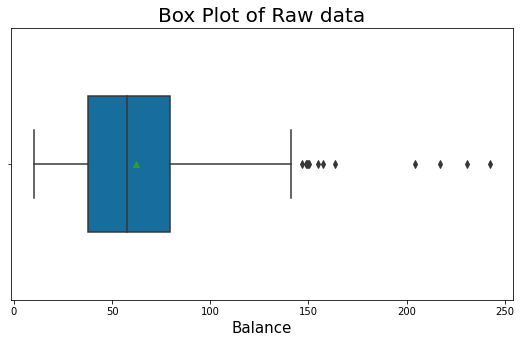

In [354]:
#Box plot------- code 
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
plt.figure(figsize=(9,5))

boxplot = sns.boxplot( x=merg_raw['original_shape_Maximum2DDiameterColumn'], data=merg_raw,showmeans=True,
                 width=0.5,
                 palette="colorblind")

plt.title("Box Plot of Raw data", fontsize=20)
plt.xlabel("Balance", fontsize=15)

In [ ]:
sns.boxplot( 

Text(0.5, 0, 'Balance')

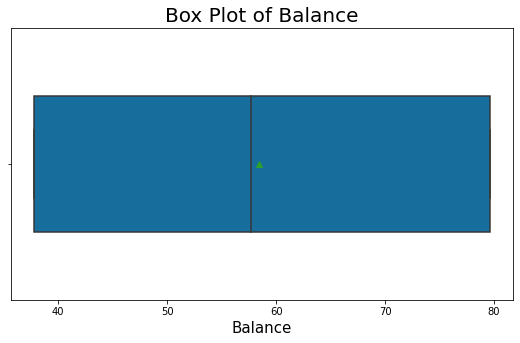

In [355]:
plt.figure(figsize=(9,5))

boxplot = sns.boxplot( x=series,showmeans=True, data=merg_raw,
                 width=0.5,
                 palette="colorblind")

plt.title("Box Plot of Balance", fontsize=20)
plt.xlabel("Balance", fontsize=15)